In [ ]:

!pip install -q librosa soundfile torchaudio scikit-learn matplotlib pandas tqdm


In [ ]:

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio

from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from tqdm.auto import tqdm

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch Version:", torch.__version__)
print("Torchaudio Version:", torchaudio.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch Version: 2.14.1+cu130
Torchaudio Version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


In [ ]:

PROJECT_DIR = "/content/TC_ResNet8_Project"

os.makedirs(PROJECT_DIR, exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/checkpoints", exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/results", exist_ok=True)

print("Project directory created successfully!")
print(os.listdir(PROJECT_DIR))


Project directory created successfully!
['results', 'checkpoints']


In [ ]:

class TCResNetBlock(nn.Module):

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv1d(
            in_channels,
            out_channels,
            kernel_size=9,
            stride=stride,
            padding=4,
            bias=False
        )

        self.bn1 = nn.BatchNorm1d(out_channels)

        self.conv2 = nn.Conv1d(
            out_channels,
            out_channels,
            kernel_size=9,
            stride=1,
            padding=4,
            bias=False
        )

        self.bn2 = nn.BatchNorm1d(out_channels)

        self.downsample = None

        if stride != 1 or in_channels != out_channels:
            self.downsample = nn.Sequential(
                nn.Conv1d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm1d(out_channels)
            )

    def forward(self, x):

        residual = x

        out = F.relu(self.bn1(self.conv1(x)), inplace=True)

        out = self.bn2(self.conv2(out))

        if self.downsample is not None:
            residual = self.downsample(x)

        out = out + residual

        return F.relu(out, inplace=True)


class TCResNet8(nn.Module):

    def __init__(self, num_classes=2, channels=(12, 18, 24, 32)):
        super().__init__()

        self.conv1 = nn.Conv1d(
            40, channels[0],
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm1d(channels[0])

        self.layer1 = TCResNetBlock(
            channels[0], channels[1], stride=2
        )

        self.layer2 = TCResNetBlock(
            channels[1], channels[2], stride=2
        )

        self.layer3 = TCResNetBlock(
            channels[2], channels[3], stride=2
        )

        self.pool = nn.AdaptiveAvgPool1d(1)

        self.fc = nn.Linear(channels[3], num_classes)

    def forward(self, x):

        # [B, 1, 40, 101] -> [B, 40, 101]
        x = x.squeeze(1)

        x = F.relu(self.bn1(self.conv1(x)), inplace=True)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)

        x = self.pool(x).squeeze(-1)

        x = self.fc(x)

        return x


In [ ]:

model = TCResNet8(num_classes=2).to(device)

# Create a dummy batch
dummy_input = torch.randn(4, 1, 40, 101).to(device)

# Forward pass
model.eval()

with torch.no_grad():
    output = model(dummy_input)

# Parameter count
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

# FP32 parameter storage
model_size_kb = sum(
    p.numel() * p.element_size()
    for p in model.parameters()
) / 1024

print("TC-ResNet-8 Architecture Test")
print("--------------------------------")
print("Input Shape:", dummy_input.shape)
print("Output Shape:", output.shape)
print("Trainable Parameters:", total_params)
print(f"FP32 Parameter Size: {model_size_kb:.2f} KB")
print("Device:", next(model.parameters()).device)

assert output.shape == (4, 2)
assert total_params == 33450

print("\nArchitecture Test PASSED!")


TC-ResNet-8 Architecture Test
--------------------------------
Input Shape: torch.Size([4, 1, 40, 101])
Output Shape: torch.Size([4, 2])
Trainable Parameters: 33450
FP32 Parameter Size: 130.66 KB
Device: cuda:0

Architecture Test PASSED!


dataset entery

In [ ]:
!pip install -q datasets[audio] librosa soundfile huggingface_hub

In [ ]:
from huggingface_hub import notebook_login

notebook_login()

In [ ]:
from datasets import load_dataset

hindi_dataset = load_dataset(
    "ai4bharat/Kathbath",
    "hindi",
    split="train",
    streaming=True,
    token=True
)

print(hindi_dataset)

README.md:   0%|          | 0.00/10.0k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/22 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

IterableDataset({
    features: ['fname', 'text', 'audio_filepath', 'lang', 'duration', 'gender', 'speaker_id'],
    num_shards: 32
})


testing sample

In [ ]:
sample = next(iter(hindi_dataset))

print("Available columns:", sample.keys())
print("Transcript:", sample["text"])
print("Language:", sample["lang"])
print("Duration:", sample["duration"])
print("Speaker ID:", sample["speaker_id"])

audio = sample["audio_filepath"]

print("Sampling rate:", audio["sampling_rate"])
print("Audio shape:", audio["array"].shape)

Available columns: dict_keys(['fname', 'text', 'audio_filepath', 'lang', 'duration', 'gender', 'speaker_id'])
Transcript: हालांकि चिकित्सकों ने जेसीओ की मौत हार्ट अटैक से हुई बताया है
Language: hi
Duration: 4.9923125
Speaker ID: 329
Sampling rate: 16000
Audio shape: (79877,)


In [ ]:
from IPython.display import Audio, display

display(Audio(audio["array"], rate=audio["sampling_rate"]))

english dataset

In [ ]:
!pip install -q -U datasets[audio] librosa soundfile huggingface_hub

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [ ]:
import torch
import torchaudio

print("PyTorch version:", torch.__version__)
print("Torchaudio version:", torchaudio.__version__)

PyTorch version: 2.14.1+cu130
Torchaudio version: 2.11.0+cu130


In [ ]:
import os
from torchaudio.datasets import SPEECHCOMMANDS

DATASET_ROOT = "/content/datasets"
# Create the root folder explicitly so torchaudio has a valid place to download files
os.makedirs(DATASET_ROOT, exist_ok=True)

train_dataset = SPEECHCOMMANDS(
    root=DATASET_ROOT,
    download=True,
    subset="training"
)

val_dataset = SPEECHCOMMANDS(
    root=DATASET_ROOT,
    download=True,
    subset="validation"
)

test_dataset = SPEECHCOMMANDS(
    root=DATASET_ROOT,
    download=True,
    subset="testing"
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

100%|██████████| 2.26G/2.26G [00:28<00:00, 85.8MB/s]


Training samples: 84843
Validation samples: 9981
Testing samples: 11005


In [ ]:
sample = train_dataset[0]

waveform, sample_rate, label, speaker_id, utterance_number = sample

print("Waveform shape:", waveform.shape)
print("Sampling rate:", sample_rate)
print("Label:", label)
print("Speaker ID:", speaker_id)
print("Utterance number:", utterance_number)

Waveform shape: torch.Size([1, 16000])
Sampling rate: 16000
Label: backward
Speaker ID: 0165e0e8
Utterance number: 0


In [ ]:
from collections import Counter
from tqdm import tqdm
TARGET_WORDS = ["stop", "up", "go", "off", "on"]

label_counts = Counter()

for i in tqdm(range(len(train_dataset))):
    label = train_dataset.get_metadata(i)[2]
    label_counts[label] += 1
print('\n')
for word in TARGET_WORDS:
    print(word.upper(), ":", label_counts[word])

100%|██████████| 84843/84843 [00:01<00:00, 66744.18it/s]



STOP : 3111
UP : 2948
GO : 3106
OFF : 2970
ON : 3086


Analyze and filter the English keywords

Step 1 — Inspect all English word classes

In [ ]:

from collections import Counter
from tqdm import tqdm

def get_all_word_counts(dataset, split_name):
    counts = Counter()

    for i in tqdm(range(len(dataset)), desc=split_name):
        metadata = dataset.get_metadata(i)
        label = metadata[2]
        counts[label] += 1

    print(f"\n{split_name} vocabulary:")
    for word, count in sorted(counts.items()):
        print(f"{word:12s}: {count}")

    print("\nTotal classes:", len(counts))
    print("Total audio samples:", sum(counts.values()))

    return counts


train_word_counts = get_all_word_counts(
    train_dataset, "Training"
)

val_word_counts = get_all_word_counts(
    val_dataset, "Validation"
)

test_word_counts = get_all_word_counts(
    test_dataset, "Testing"
)


Training: 100%|██████████| 84843/84843 [00:01<00:00, 84273.60it/s]



Training vocabulary:
backward    : 1346
bed         : 1594
bird        : 1697
cat         : 1657
dog         : 1711
down        : 3134
eight       : 3033
five        : 3240
follow      : 1275
forward     : 1256
four        : 2955
go          : 3106
happy       : 1632
house       : 1727
learn       : 1286
left        : 3037
marvin      : 1710
nine        : 3170
no          : 3130
off         : 2970
on          : 3086
one         : 3140
right       : 3019
seven       : 3205
sheila      : 1606
six         : 3088
stop        : 3111
three       : 2966
tree        : 1407
two         : 3111
up          : 2948
visual      : 1288
wow         : 1724
yes         : 3228
zero        : 3250

Total classes: 35
Total audio samples: 84843


Validation: 100%|██████████| 9981/9981 [00:00<00:00, 107344.40it/s]



Validation vocabulary:
backward    : 153
bed         : 213
bird        : 182
cat         : 180
dog         : 197
down        : 377
eight       : 346
five        : 367
follow      : 132
forward     : 146
four        : 373
go          : 372
happy       : 219
house       : 195
learn       : 128
left        : 352
marvin      : 195
nine        : 356
no          : 406
off         : 373
on          : 363
one         : 351
right       : 363
seven       : 387
sheila      : 204
six         : 378
stop        : 350
three       : 356
tree        : 159
two         : 345
up          : 350
visual      : 139
wow         : 193
yes         : 397
zero        : 384

Total classes: 35
Total audio samples: 9981


Testing: 100%|██████████| 11005/11005 [00:00<00:00, 143876.05it/s]


Testing vocabulary:
backward    : 165
bed         : 207
bird        : 185
cat         : 194
dog         : 220
down        : 406
eight       : 408
five        : 445
follow      : 172
forward     : 155
four        : 400
go          : 402
happy       : 203
house       : 191
learn       : 161
left        : 412
marvin      : 195
nine        : 408
no          : 405
off         : 402
on          : 396
one         : 399
right       : 396
seven       : 406
sheila      : 212
six         : 394
stop        : 411
three       : 405
tree        : 193
two         : 424
up          : 425
visual      : 165
wow         : 206
yes         : 419
zero        : 418

Total classes: 35
Total audio samples: 11005


Step 2 — What we're looking for
The output should show the word labels and their counts in each split.

We'll use the actual vocabulary returned by the dataset, rather than manually typing 35 words. This also ensures we don't accidentally include special labels such as _silence_ or _unknown_ as English target words.

In [ ]:

import pandas as pd

# Exclude special dataset labels
SPECIAL_LABELS = {"_silence_", "_unknown_"}

english_words = sorted([
    word for word in train_word_counts
    if word not in SPECIAL_LABELS
])

english_vocab = pd.DataFrame({
    "english_word": english_words,
    "train_samples": [
        train_word_counts[word] for word in english_words
    ],
    "validation_samples": [
        val_word_counts[word] for word in english_words
    ],
    "test_samples": [
        test_word_counts[word] for word in english_words
    ]
})

english_vocab.to_csv(
    "/content/english_vocabulary.csv",
    index=False
)

print("Total English words:", len(english_vocab))
display(english_vocab)

print("\nSaved: /content/english_vocabulary.csv")


Total English words: 35


,english_word,train_samples,validation_samples,test_samples
0,backward,1346,153,165
1,bed,1594,213,207
2,bird,1697,182,185
3,cat,1657,180,194
4,dog,1711,197,220
5,down,3134,377,406
6,eight,3033,346,408
7,five,3240,367,445
8,follow,1275,132,172
9,forward,1256,146,155



Saved: /content/english_vocabulary.csv


Step 2.1 — Load Hindi transcript metadata
We'll initially load only text and metadata, not audio. This makes vocabulary extraction much faster and avoids downloading unnecessary audio.

In [ ]:

from datasets import load_dataset

hindi_train = load_dataset(
    "ai4bharat/Kathbath",
    "hindi",
    split="train",
    streaming=True,
    token=True
)

# Exclude the audio column while inspecting transcripts
hindi_text_data = hindi_train.select_columns([
    "fname",
    "text",
    "duration",
    "speaker_id"
])

print("Kathbath Hindi training data loaded!")
print(hindi_text_data)


Resolving data files:   0%|          | 0/22 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Kathbath Hindi training data loaded!
IterableDataset({
    features: ['fname', 'text', 'duration', 'speaker_id'],
    num_shards: 32
})


Step 2.2 — Inspect Hindi transcripts
Let's look at five actual transcripts before processing the complete dataset.

In [ ]:

from itertools import islice

hindi_samples = list(islice(hindi_text_data, 5))

for i, sample in enumerate(hindi_samples, 1):
    print(f"\nSample {i}")
    print("Transcript:", sample["text"])
    print("Duration:", sample["duration"])
    print("Speaker:", sample["speaker_id"])



Sample 1
Transcript: हालांकि चिकित्सकों ने जेसीओ की मौत हार्ट अटैक से हुई बताया है
Duration: 4.9923125
Speaker: 329

Sample 2
Transcript: मैंने उनसे कभी न खत्म होने वाले गैस का सिलेंडर की विश की है
Duration: 4.5975625
Speaker: 1128

Sample 3
Transcript: क्योंकि लोगों को एकत्रित करने पर पंजाब सरकार की ही मनाही लगी हुई है
Duration: 5.82825
Speaker: 268

Sample 4
Transcript: साहब अब तो सब कुछ ही बदल गया है
Duration: 3.483
Speaker: 1148

Sample 5
Transcript: इनकी यह तस्वीर सोशल साइट पर काफी वायरल हुई हैं
Duration: 3.9241875
Speaker: 590


Step 3 — Extract Hindi words from Kathbath
Step 3.1 — Tokenize Hindi transcripts

In [ ]:

import re
from collections import Counter
from tqdm import tqdm

hindi_word_counts = Counter()

for sample in tqdm(hindi_text_data, desc="Extracting Hindi vocabulary"):
    text = sample["text"]

    # Extract Devanagari words
    words = re.findall(r'[\u0900-\u097F]+', text)

    hindi_word_counts.update(words)

print("Unique Hindi words:", len(hindi_word_counts))
print("\nTop 50 Hindi words:")

for word, count in hindi_word_counts.most_common(50):
    print(f"{word:20s} {count}")


Extracting Hindi vocabulary: 91752it [06:43, 227.21it/s]

Unique Hindi words: 56969

Top 50 Hindi words:
के                   42971
है                   39446
में                  35862
की                   27994
को                   20049
से                   19559
का                   17663
हैं                  14590
ने                   13546
और                   13209
पर                   12740
भी                   12129
इस                   9506
एक                   9024
लिए                  7740
कि                   7225
नहीं                 6915
किया                 6491
यह                   6213
ही                   6182
कर                   6132
गया                  5340
था                   4781
हो                   4735
साथ                  4139
बाद                  3960
करने                 3664
दिया                 3236
रहा                  3068
इसके                 3065
उन्होंने             3008
रहे                  2923
रही                  2854
अपने                 2769
तो                   2669
जा                   2635
थे   

Step 3.2 — Save the Hindi vocabulary as CSV

In [ ]:

import pandas as pd

hindi_vocab = pd.DataFrame(
    hindi_word_counts.items(),
    columns=["hindi_word", "frequency"]
)

hindi_vocab = hindi_vocab.sort_values(
    "frequency",
    ascending=False
).reset_index(drop=True)

hindi_vocab.to_csv(
    "/content/hindi_vocabulary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Unique Hindi words:", len(hindi_vocab))
print("Saved: /content/hindi_vocabulary.csv")

display(hindi_vocab.head(30))


Unique Hindi words: 56969
Saved: /content/hindi_vocabulary.csv


,hindi_word,frequency
0,के,42971
1,है,39446
2,में,35862
3,की,27994
4,को,20049
5,से,19559
6,का,17663
7,हैं,14590
8,ने,13546
9,और,13209


Step 4 — Prepare English-Hindi word pairs
We have:
- 35 English target words from Google Speech Commands v2.
- Hindi words and their frequencies from Kathbath.
We'll initially generate candidate pairs using phonetic representations.

Step 4.1 — Install phonetic processing libraries

In [ ]:
!pip install -q epitran panphon indic-transliteration

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Step 4.2 — Convert English and Hindi words into phonetic representations
For English, we'll use the CMU Pronouncing Dictionary. For Hindi, we'll use an Indic transliteration system as an initial representation, then convert to IPA.

In [ ]:
!pip install -q cmudict

In [ ]:
import cmudict
import pandas as pd
import re

pronouncing_dict = cmudict.dict()

def get_english_ipa(word):
    pronunciations = pronouncing_dict.get(word.lower())

    if pronunciations:
        return " ".join(pronunciations[0])

    return None


for word in english_words[:10]:
    print(word, "->", get_english_ipa(word))

backward -> B AE1 K W ER0 D
bed -> B EH1 D
bird -> B ER1 D
cat -> K AE1 T
dog -> D AO1 G
down -> D AW1 N
eight -> EY1 T
five -> F AY1 V
follow -> F AA1 L OW0
forward -> F AO1 R W ER0 D


Step 4.3 — Inspect Hindi transliteration

In [ ]:
from indic_transliteration import sanscript
from indic_transliteration.sanscript import transliterate

def hindi_to_roman(word):
    return transliterate(
        word,
        sanscript.DEVANAGARI,
        sanscript.ITRANS
    )

for word, count in hindi_word_counts.most_common(20):
    print(word, "->", hindi_to_roman(word), "|", count)

के -> ke | 42971
है -> hai | 39446
में -> meM | 35862
की -> kI | 27994
को -> ko | 20049
से -> se | 19559
का -> kA | 17663
हैं -> haiM | 14590
ने -> ne | 13546
और -> aura | 13209
पर -> para | 12740
भी -> bhI | 12129
इस -> isa | 9506
एक -> eka | 9024
लिए -> lie | 7740
कि -> ki | 7225
नहीं -> nahIM | 6915
किया -> kiyA | 6491
यह -> yaha | 6213
ही -> hI | 6182


Important research note

ITRANS transliteration is not itself an IPA transcription. We should not calculate a phonetic similarity score directly from English CMU phones and Hindi ITRANS text. In the next step, we'll normalize both into comparable phonetic representations.

Step 4.4 — Create the candidate-pair CSV

For now, we'll create a CSV containing every English word and the most frequent Hindi vocabulary candidates. This is a candidate-generation file, not a verified hard-negative dataset.

In [ ]:
rows = []

top_hindi_words = [
    word for word, count in hindi_word_counts.most_common(1000)
]

for english_word in english_words:
    for hindi_word in top_hindi_words:
        rows.append({
            "english_word": english_word,
            "hindi_word": hindi_word,
            "hindi_transliteration": hindi_to_roman(hindi_word),
            "english_pronunciation": get_english_ipa(english_word),
            "hindi_frequency": hindi_word_counts[hindi_word],
            "phonetic_similarity": None,
            "hard_negative": False
        })

candidate_pairs = pd.DataFrame(rows)

candidate_pairs.to_csv(
    "/content/cross_lingual_candidate_pairs.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Candidate pairs:", len(candidate_pairs))
print("Saved successfully!")
display(candidate_pairs.head(10))

Candidate pairs: 35000
Saved successfully!


,english_word,hindi_word,hindi_transliteration,english_pronunciation,hindi_frequency,phonetic_similarity,hard_negative
0,backward,के,ke,B AE1 K W ER0 D,42971,None,False
1,backward,है,hai,B AE1 K W ER0 D,39446,None,False
2,backward,में,meM,B AE1 K W ER0 D,35862,None,False
3,backward,की,kI,B AE1 K W ER0 D,27994,None,False
4,backward,को,ko,B AE1 K W ER0 D,20049,None,False
5,backward,से,se,B AE1 K W ER0 D,19559,None,False
6,backward,का,kA,B AE1 K W ER0 D,17663,None,False
7,backward,हैं,haiM,B AE1 K W ER0 D,14590,None,False
8,backward,ने,ne,B AE1 K W ER0 D,13546,None,False
9,backward,और,aura,B AE1 K W ER0 D,13209,None,False


Step 5 — Build actual phonetic similarity scores
We'll use IPA-based comparison instead of comparing English CMU phonemes directly with Hindi ITRANS transliteration.

Our pipeline will be:
1. Convert English words to IPA.
2. Convert Hindi words to IPA using a Hindi pronunciation/G2P system.
3. Normalize the phoneme sequences.
4. Calculate phonetic similarity using normalized edit distance.
5. Rank candidate Hindi words for each English word.

Step 5.1 — Install phonetic tools

In [ ]:
!pip install -q epitran panphon

Important correction
epitran can provide Hindi IPA transliteration, but we should verify its Hindi support and output on actual words before processing all 35,000 pairs. CMU's ARPAbet output also needs conversion into IPA.

Let's first test the Hindi transliteration system.

In [ ]:

import epitran

epi = epitran.Epitran('hin-Deva')

test_words = ["के", "है", "में", "को", "और", "नमस्ते"]

for word in test_words:
    print(word, "->", epi.transliterate(word))


के -> ke
है -> ɦæː
में -> men
को -> ko
और -> ɔːr
नमस्ते -> nəmste


Step 5.2 — Show English IPA

In [ ]:
!pip install -q phonemizer

In [ ]:
from phonemizer import phonemize

Step 5.2 — Generate English IPA using Epitran

First, let's check whether Epitran supports English in your Colab environment.

In [ ]:
# 1. Install g2p_en and explicitly download the required NLTK resource
!pip install -q g2p_en

import nltk
nltk.download('averaged_perceptron_tagger_eng')

from g2p_en import G2p

g2p = G2p()

test_english_words = [
    "backward",
    "bed",
    "bird",
    "cat",
    "dog",
    "down",
    "eight",
    "five",
    "go",
    "no",
    "on",
    "one",
    "right",
    "stop",
    "tree"
]

# Map ARPAbet phonemes produced by g2p_en to IPA characters where necessary
print("English word G2P Phonemes:")
for word in test_english_words:
    phonemes = g2p(word)
    print(f"{word} -> {phonemes}")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package cmudict to /root/nltk_data...
[nltk_data]   Unzipping corpora/cmudict.zip.


English word G2P Phonemes:
backward -> ['B', 'AE1', 'K', 'W', 'ER0', 'D']
bed -> ['B', 'EH1', 'D']
bird -> ['B', 'ER1', 'D']
cat -> ['K', 'AE1', 'T']
dog -> ['D', 'AO1', 'G']
down -> ['D', 'AW1', 'N']
eight -> ['EY1', 'T']
five -> ['F', 'AY1', 'V']
go -> ['G', 'OW1']
no -> ['N', 'OW1']
on -> ['AA1', 'N']
one -> ['W', 'AH1', 'N']
right -> ['R', 'AY1', 'T']
stop -> ['S', 'T', 'AA1', 'P']
tree -> ['T', 'R', 'IY1']


Step 5.3 — Convert English ARPAbet to IPA

Since Epitran is already working for Hindi, let's convert the English ARPAbet output into IPA so that both languages use a comparable representation.

In [ ]:
!pip install -q eng-to-ipa

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import eng_to_ipa as ipa

test_words = [
    "backward", "bed", "bird", "cat", "dog",
    "down", "eight", "five", "go", "no",
    "on", "one", "right", "stop", "tree"
]

print("English IPA representations:\n")

for word in test_words:
    print(word, "->", ipa.convert(word))

English IPA representations:

backward -> ˈbækwərd
bed -> bɛd
bird -> bərd
cat -> kæt
dog -> dɔg
down -> daʊn
eight -> eɪt
five -> faɪv
go -> goʊ
no -> noʊ
on -> ɔn
one -> wən
right -> raɪt
stop -> stɑp
tree -> tri


Step 5.4 — Generate Hindi phonetic representations

Before calculating similarity, let's generate and save Epitran representations for all Hindi words in your vocabulary.

In [ ]:
import epitran
import pandas as pd
from tqdm import tqdm

hindi_epi = epitran.Epitran('hin-Deva')

hindi_phonetic_data = []

for word, frequency in tqdm(
    hindi_word_counts.items(),
    desc="Generating Hindi phonetic representations"
):
    try:
        pronunciation = hindi_epi.transliterate(word)

        if pronunciation:
            hindi_phonetic_data.append({
                "hindi_word": word,
                "hindi_pronunciation": pronunciation,
                "frequency": frequency
            })

    except Exception:
        continue

hindi_phonetic_df = pd.DataFrame(hindi_phonetic_data)

hindi_phonetic_df.to_csv(
    "/content/hindi_phonetic_vocabulary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Total Hindi words:", len(hindi_phonetic_df))
print(hindi_phonetic_df.head(15))

Generating Hindi phonetic representations: 100%|██████████| 56969/56969 [00:12<00:00, 4697.16it/s]


Total Hindi words: 56969
    hindi_word hindi_pronunciation  frequency
0      हालांकि           ɦaːlaːŋki        769
1   चिकित्सकों        t͡ʃikitsəkon         40
2           ने                  ne      13546
3        जेसीओ            d͡ʒesiːo          1
4           की                 kiː      27994
5          मौत                mɔːt        492
6        हार्ट              ɦaːrʈə         18
7         अटैक               aʈæːk         23
8           से                  se      19559
9          हुई                ɦuiː       1497
10       बताया            bətaːjaː       1089
11          है                 ɦæː      39446
12       मैंने              mæːnne        259
13        उनसे                unse        160
14         कभी              kəb̤iː        427


Step 5.5 — Check phoneme segmentation

Before calculating similarity across all 35 English keywords and 56,969 Hindi words, let's test how PanPhon handles the IPA symbols.

This matters because a sound such as t͡ʃ should be treated as one phoneme, not several individual characters.

In [ ]:
!pip install -q panphon

In [ ]:
import panphon

ft = panphon.FeatureTable()

test_pronunciations = [
    "kæt",
    "bɛd",
    "ɦæː",
    "t͡ʃikitsəkon",
    "mɔːt",
    "aʈæːk"
]

print("Phoneme segmentation:\n")

for pronunciation in test_pronunciations:
    segments = ft.ipa_segs(pronunciation)
    print(pronunciation, "->", segments)

Phoneme segmentation:

kæt -> ['k', 'æ', 't']
bɛd -> ['b', 'ɛ', 'd']
ɦæː -> ['ɦ', 'æː']
t͡ʃikitsəkon -> ['t͡ʃ', 'i', 'k', 'i', 't', 's', 'ə', 'k', 'o', 'n']
mɔːt -> ['m', 'ɔː', 't']
aʈæːk -> ['a', 'ʈ', 'æː', 'k']


Step 5.6 — Calculate phonetic similarity

We'll now compare English and Hindi pronunciations using PanPhon's feature-based phonetic edit distance.

Unlike ordinary string similarity, this considers how speech sounds are produced. For example, two consonants that differ by only one articulatory feature should be considered more similar than completely different sounds.

In [ ]:
from panphon.distance import Distance

distance = Distance()

pairs = [
    ("kæt", "kæt"),
    ("kæt", "kɛt"),
    ("kæt", "bɔːt")
]

for english, hindi in pairs:
    score = distance.feature_edit_distance(english, hindi)
    print(english, "vs", hindi, "->", score)

kæt vs kæt -> 0.0
kæt vs kɛt -> 0.08333333333333333
kæt vs bɔːt -> 0.4166666666666667


Step 5.7 — Compare all English and Hindi words

We'll now compare all 35 English keywords against the 56,969 Hindi words.

To make this more efficient, we'll:
- Remove duplicate Hindi pronunciations for the distance calculations.
- Compare every English keyword against the unique Hindi pronunciations.
- Rank the closest Hindi words for each English keyword.
- Save the top 100 candidates per English keyword.
This gives us up to 3,500 shortlisted pairs for further investigation.

In [ ]:
import pandas as pd
import numpy as np
import eng_to_ipa as ipa
import panphon
import unicodedata
from tqdm import tqdm
from collections import defaultdict

distance = panphon.distance.Distance()

def clean_ipa(text):
    text = unicodedata.normalize("NFC", str(text))
    text = text.replace("ˈ", "").replace("ˌ", "")
    text = text.replace(".", "").replace(" ", "")
    return text.strip()

# Generate English IPA for all 35 keywords
english_ipa_data = {}

for word in english_words:
    pronunciation = ipa.convert(word)
    english_ipa_data[word] = clean_ipa(pronunciation)

# Prepare Hindi vocabulary
hindi_data = hindi_phonetic_df.copy()

hindi_data["clean_pronunciation"] = (
    hindi_data["hindi_pronunciation"].apply(clean_ipa)
)

# Group Hindi words sharing the same pronunciation
hindi_groups = defaultdict(list)

for row in hindi_data.itertuples(index=False):
    hindi_groups[row.clean_pronunciation].append({
        "hindi_word": row.hindi_word,
        "frequency": row.frequency
    })

unique_hindi_pronunciations = list(hindi_groups.keys())

print("English keywords:", len(english_ipa_data))
print("Unique Hindi pronunciations:", len(unique_hindi_pronunciations))

# Compare and rank
candidate_results = []

for english_word, english_pronunciation in tqdm(
    english_ipa_data.items(),
    desc="Comparing English-Hindi pronunciations"
):
    word_results = []

    for hindi_pronunciation in unique_hindi_pronunciations:
        try:
            score = distance.feature_edit_distance(
                english_pronunciation,
                hindi_pronunciation
            )

            if not np.isfinite(score):
                continue

            for hindi_item in hindi_groups[hindi_pronunciation]:
                word_results.append({
                    "english_word": english_word,
                    "english_ipa": english_pronunciation,
                    "hindi_word": hindi_item["hindi_word"],
                    "hindi_ipa": hindi_pronunciation,
                    "hindi_frequency": hindi_item["frequency"],
                    "phonetic_distance": score,
                    "phonetic_similarity": max(0, 1 - score)
                })

        except Exception:
            continue

    word_results.sort(
        key=lambda x: (
            x["phonetic_distance"],
            -x["hindi_frequency"]
        )
    )

    candidate_results.extend(word_results[:100])

# Save results
similarity_df = pd.DataFrame(candidate_results)

similarity_df.to_csv(
    "/content/phonetic_similarity_candidates.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nComparison completed!")
print("Total shortlisted pairs:", len(similarity_df))

print("\nTop 30 candidate pairs:")
display(
    similarity_df.sort_values(
        ["phonetic_distance", "hindi_frequency"]
    ).head(30)
)

English keywords: 35
Unique Hindi pronunciations: 56129


Comparing English-Hindi pronunciations: 100%|██████████| 35/35 [09:51<00:00, 16.89s/it]


Comparison completed!
Total shortlisted pairs: 3500

Top 30 candidate pairs:


,english_word,english_ipa,hindi_word,hindi_ipa,hindi_frequency,phonetic_distance,phonetic_similarity
2900,two,tu,तु,tu,1,0.000000,1.000000
404,dog,dɔg,दौ,dɔː,1,0.041667,0.958333
405,dog,dɔg,डॉ़,ɖɔ़,1,0.041667,0.958333
1001,four,fɔr,ऑफ़र,ऑfər,1,0.041667,0.958333
2001,on,ɔn,ों,on,1,0.041667,0.958333
2902,two,tu,टु,ʈu,1,0.041667,0.958333
2000,on,ɔn,ओन,on,2,0.041667,0.958333
3300,yes,jɛs,यस,jəs,2,0.041667,0.958333
403,dog,dɔg,डॉ॰,ɖɔ॰,3,0.041667,0.958333
100,bed,bɛd,बद,bəd,4,0.041667,0.958333


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Step 5.8 — Clean and inspect the candidates

Let's remove malformed tokens and prioritize words appearing at least five times. We'll preserve the original results separately so that rare candidates aren't permanently lost.

In [ ]:
import unicodedata
import pandas as pd

def valid_hindi_word(word):
    word = str(word).strip()

    if not word:
        return False

    has_letter = False

    for char in word:
        category = unicodedata.category(char)

        if category.startswith("L"):
            has_letter = True
        elif category.startswith("M"):
            continue
        else:
            return False

    return has_letter


# Filter candidate results
clean_candidates = similarity_df[
    similarity_df["hindi_word"].apply(valid_hindi_word)
].copy()

# Keep sufficiently frequent candidates for initial inspection
frequent_candidates = clean_candidates[
    clean_candidates["hindi_frequency"] >= 5
].copy()

# Sort by distance, then frequency
frequent_candidates = frequent_candidates.sort_values(
    ["english_word", "phonetic_distance", "hindi_frequency"],
    ascending=[True, True, False]
)

# Keep the best 5 candidates for each English keyword
top_candidates = (
    frequent_candidates
    .groupby("english_word", group_keys=False)
    .head(5)
)

top_candidates.to_csv(
    "/content/clean_hard_negative_candidates.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Original shortlisted pairs:", len(similarity_df))
print("After removing malformed tokens:", len(clean_candidates))
print("After frequency filtering:", len(frequent_candidates))
print("Final inspection candidates:", len(top_candidates))

display(
    top_candidates[
        [
            "english_word",
            "english_ipa",
            "hindi_word",
            "hindi_ipa",
            "hindi_frequency",
            "phonetic_distance",
            "phonetic_similarity"
        ]
    ]
)

Original shortlisted pairs: 3500
After removing malformed tokens: 3487
After frequency filtering: 1326
Final inspection candidates: 175


,english_word,english_ipa,hindi_word,hindi_ipa,hindi_frequency,phonetic_distance,phonetic_similarity
1,backward,bækwərd,मकबरे,məkbəre,11,0.770833,0.229167
3,backward,bækwərd,बिगड़ने,biɡɽəne,16,0.833333,0.166667
4,backward,bækwərd,बिटकॉइन,biʈkɔin,5,0.854167,0.145833
6,backward,bækwərd,पकड़ने,pəkɽəne,49,0.875000,0.125000
7,backward,bækwərd,फैक्टरी,pʰæːkʈəriː,13,0.875000,0.125000
...,...,...,...,...,...,...,...
3402,zero,ziroʊ,ज़रिए,zərie,10,0.416667,0.583333
3405,zero,ziroʊ,सिंह,sinɦə,1041,0.437500,0.562500
3406,zero,ziroʊ,सिलाई,silaːiː,8,0.437500,0.562500
3411,zero,ziroʊ,सराय,səraːj,10,0.458333,0.541667


Step 5.9 — Inspect the strongest candidates

Let's create a more useful shortlist using a strict initial distance threshold of 0.20 and a minimum frequency of 5.

This is a preliminary research filter, not a final definition of a hard negative.

In [ ]:
strong_candidates = clean_candidates[
    (clean_candidates["phonetic_distance"] <= 0.20) &
    (clean_candidates["hindi_frequency"] >= 5)
].copy()

strong_candidates = strong_candidates.sort_values(
    ["english_word", "phonetic_distance", "hindi_frequency"],
    ascending=[True, True, False]
)

strong_candidates.to_csv(
    "/content/strong_phonetic_candidates.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Strong candidate pairs:", len(strong_candidates))
print(
    "English keywords with candidates:",
    strong_candidates["english_word"].nunique()
)

display(strong_candidates)

Strong candidate pairs: 129
English keywords with candidates: 16


,english_word,english_ipa,hindi_word,hindi_ipa,hindi_frequency,phonetic_distance,phonetic_similarity
101,bed,bɛd,पद,pəd,252,0.083333,0.916667
102,bed,bɛd,भेद,b̤ed,37,0.083333,0.916667
103,bed,bɛd,बेड,beɖ,27,0.083333,0.916667
104,bed,bɛd,बन,bən,520,0.125000,0.875000
105,bed,bɛd,वेद,ved,28,0.125000,0.875000
...,...,...,...,...,...,...,...
3006,up,əp,ऐप,æːp,74,0.166667,0.833333
3007,up,əp,उप,up,46,0.166667,0.833333
3008,up,əp,आफ,aːpʰ,14,0.166667,0.833333
3012,up,əp,अत,at,30,0.187500,0.812500


Step 5.10 — Add candidate classifications

Let's classify the shortlisted candidates so we can distinguish native Hindi words, loanwords, and questionable tokens.

In [ ]:
import re
import pandas as pd

# English loanword indicators
loanword_pattern = re.compile(
    r'कैट|डॉग|बेड|ट्री|टू|फोर|सेवन|एट|नाइन|जीरो|स्टॉप',
    re.IGNORECASE
)

def classify_candidate(word):
    if loanword_pattern.search(word):
        return "Possible English loanword"

    if len(word) <= 1:
        return "Needs manual verification"

    return "Native Hindi candidate - verify"

strong_candidates["candidate_type"] = (
    strong_candidates["hindi_word"].apply(classify_candidate)
)

print(strong_candidates["candidate_type"].value_counts())

display(
    strong_candidates[
        [
            "english_word",
            "hindi_word",
            "hindi_ipa",
            "hindi_frequency",
            "phonetic_distance",
            "candidate_type"
        ]
    ].head(40)
)

strong_candidates.to_csv(
    "/content/classified_hard_negative_candidates.csv",
    index=False,
    encoding="utf-8-sig"
)

candidate_type
Native Hindi candidate - verify    118
Possible English loanword            6
Needs manual verification            5
Name: count, dtype: int64


,english_word,hindi_word,hindi_ipa,hindi_frequency,phonetic_distance,candidate_type
101,bed,पद,pəd,252,0.083333,Native Hindi candidate - verify
102,bed,भेद,b̤ed,37,0.083333,Native Hindi candidate - verify
103,bed,बेड,beɖ,27,0.083333,Possible English loanword
104,bed,बन,bən,520,0.125000,Native Hindi candidate - verify
105,bed,वेद,ved,28,0.125000,Native Hindi candidate - verify
106,bed,बेन,ben,15,0.125000,Native Hindi candidate - verify
107,bed,बढ,bəɖ̤,11,0.125000,Native Hindi candidate - verify
108,bed,मद,məd,6,0.125000,Native Hindi candidate - verify
114,bed,बाद,baːd,3960,0.166667,Native Hindi candidate - verify
115,bed,बस,bəs,318,0.166667,Native Hindi candidate - verify


Next step:

Check whether these words actually occur in the audio
This is the most important part of the project.

Your Kathbath dataset contains complete Hindi utterances. The frequency count tells us how often a word occurs in transcripts, but it doesn't tell us exactly where that word occurs in the audio.

We must obtain word-level timestamps before extracting individual hard-negative recordings.

Step 5.11 — Inspect Kathbath audio metadata

Let's inspect one actual dataset example before deciding on an audio extraction method.

In [ ]:
# To fix the KeyError, we inspect the original 'hindi_dataset' which contains the full sample with audio
sample = next(iter(hindi_dataset))

print("Available fields:")
print(sample.keys())

print("\nTranscript:")
print(sample["text"])

print("\nAudio information:")
for key, value in sample.items():
    if key != "audio_filepath":
        print(key, ":", value)

print("\nAudio object:")
print(type(sample["audio_filepath"]))

if isinstance(sample["audio_filepath"], dict):
    print("Audio object keys:", sample["audio_filepath"].keys())
    print("Sampling Rate:", sample["audio_filepath"]["sampling_rate"])
    print("Audio Data Shape:", sample["audio_filepath"]["array"].shape)

Available fields:
dict_keys(['fname', 'text', 'audio_filepath', 'lang', 'duration', 'gender', 'speaker_id'])

Transcript:
हालांकि चिकित्सकों ने जेसीओ की मौत हार्ट अटैक से हुई बताया है

Audio information:
fname : 844424930703439-329-f.m4a
text : हालांकि चिकित्सकों ने जेसीओ की मौत हार्ट अटैक से हुई बताया है
lang : hi
duration : 4.9923125
gender : Female
speaker_id : 329

Audio object:
<class 'datasets.features._torchcodec.AudioDecoder'>


Step 5.12 — Decode and inspect one Hindi recording

In [ ]:
# We fetch the sample from the original 'hindi_dataset' which contains the audio column
sample = next(iter(hindi_dataset))

# The audio dictionary key in Kathbath is 'audio_filepath', not 'audio'
audio_data = sample["audio_filepath"]

# Since it's already decoded into a dictionary when loaded through Hugging Face, we can access the components directly:
waveform = audio_data["array"]
sample_rate = audio_data["sampling_rate"]

print("Audio filename:", sample["fname"])
print("Transcript:", sample["text"])
print("Speaker ID:", sample["speaker_id"])
print("Duration:", sample["duration"])

print("\nWaveform shape:", waveform.shape)
print("Sample rate:", sample_rate)
print("Audio duration (seconds):", len(waveform) / sample_rate)

Audio filename: 844424930703439-329-f.m4a
Transcript: हालांकि चिकित्सकों ने जेसीओ की मौत हार्ट अटैक से हुई बताया है
Speaker ID: 329
Duration: 4.9923125

Waveform shape: (79877,)
Sample rate: 16000
Audio duration (seconds): 4.9923125


Phase 5 — Build TC-ResNet8

Step 1 — Prepare the environment
We will use:
- PyTorch for the neural network.
- 40-bin Log-Mel spectrograms.
- 1-second audio clips.
- Binary classification: 1 = English keyword, 0 = non-keyword.
Our input shape will be:
\[
[B,1,40,101]
\]

Where:
- B = batch size
- 1 = input channel
- 40 = Mel frequency bins
- 101 = time frames

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import pandas as pd

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

PyTorch version: 2.14.1+cu130
CUDA available: True
Using device: cuda


Step 1.2 — Define the TC-ResNet8 architecture
Our model will use:
- Initial temporal convolution.
- Residual blocks.
- Batch normalization.
- ReLU activation.
- Global average pooling.
- Fully connected binary classifier.

In [ ]:
class TemporalBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=9, stride=1):
        super().__init__()

        padding = kernel_size // 2

        self.conv1 = nn.Conv1d(
            in_channels,
            out_channels,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            bias=False
        )

        self.bn1 = nn.BatchNorm1d(out_channels)

        self.conv2 = nn.Conv1d(
            out_channels,
            out_channels,
            kernel_size=kernel_size,
            stride=1,
            padding=padding,
            bias=False
        )

        self.bn2 = nn.BatchNorm1d(out_channels)

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv1d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm1d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = F.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + identity
        out = F.relu(out)

        return out


class TCResNet8(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        self.initial = nn.Sequential(
            nn.Conv1d(40, 12, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm1d(12),
            nn.ReLU()
        )

        self.block1 = TemporalBlock(12, 12, kernel_size=9)
        self.block2 = TemporalBlock(12, 18, kernel_size=9)
        self.block3 = TemporalBlock(18, 24, kernel_size=9)
        self.block4 = TemporalBlock(24, 32, kernel_size=9)

        self.pool = nn.AdaptiveAvgPool1d(1)

        self.classifier = nn.Linear(32, num_classes)

    def forward(self, x):
        x = x.squeeze(1)

        x = self.initial(x)

        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)

        x = self.pool(x)
        x = x.squeeze(-1)

        x = self.classifier(x)

        return x

Step 1.3 — Create the model

In [ ]:
model = TCResNet8(num_classes=2).to(device)

print(model)

TCResNet8(
  (initial): Sequential(
    (0): Conv1d(40, 12, kernel_size=(3,), stride=(1,), padding=(1,), bias=False)
    (1): BatchNorm1d(12, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (block1): TemporalBlock(
    (conv1): Conv1d(12, 12, kernel_size=(9,), stride=(1,), padding=(4,), bias=False)
    (bn1): BatchNorm1d(12, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (conv2): Conv1d(12, 12, kernel_size=(9,), stride=(1,), padding=(4,), bias=False)
    (bn2): BatchNorm1d(12, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (shortcut): Identity()
  )
  (block2): TemporalBlock(
    (conv1): Conv1d(12, 18, kernel_size=(9,), stride=(1,), padding=(4,), bias=False)
    (bn1): BatchNorm1d(18, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (conv2): Conv1d(18, 18, kernel_size=(9,), stride=(1,), padding=(4,), bias=False)
    (bn2): BatchNorm1d(18, eps=1

Step 1.4 — Test the model with dummy input

We won't train yet. First, verify that the architecture accepts our Log-Mel input and returns two class scores.

In [ ]:
dummy_input = torch.randn(4, 1, 40, 101).to(device)

model.eval()

with torch.no_grad():
    output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)
print("Output:")
print(output)

Input shape: torch.Size([4, 1, 40, 101])
Output shape: torch.Size([4, 2])
Output:
tensor([[ 0.1518, -0.0316],
        [ 0.1552, -0.0339],
        [ 0.1558, -0.0366],
        [ 0.1541, -0.0355]], device='cuda:0')


Step 1.5 — Count model parameters

In [ ]:
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

model_size_kb = total_params * 4 / 1024

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("FP32 model size:", round(model_size_kb, 2), "KB")

Total parameters: 36090
Trainable parameters: 36090
FP32 model size: 140.98 KB


Next: Step 2 — Build the audio preprocessing pipeline

Before training, we need to convert every recording into the same Log-Mel format.

Our intended preprocessing configuration is:

Parameter	Value -

Sample rate	16,000 Hz

Audio duration	1 second

Samples per clip	16,000

FFT size	400

Window length	400 (25 ms)

Hop length	160 (10 ms)

Mel bins	40

Output shape	[1, 40, 101]

In [ ]:
import torchaudio
import torch
import torch.nn.functional as F

SAMPLE_RATE = 16000
DURATION = 1
NUM_SAMPLES = SAMPLE_RATE * DURATION

N_FFT = 400
WIN_LENGTH = 400
HOP_LENGTH = 160
N_MELS = 40

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=SAMPLE_RATE,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    power=2.0
)

def preprocess_audio(waveform, sample_rate):

    if waveform.dim() == 1:
        waveform = waveform.unsqueeze(0)

    waveform = waveform.mean(dim=0)

    if sample_rate != SAMPLE_RATE:
        waveform = torchaudio.functional.resample(
            waveform,
            sample_rate,
            SAMPLE_RATE
        )

    if waveform.shape[0] > NUM_SAMPLES:
        waveform = waveform[:NUM_SAMPLES]

    elif waveform.shape[0] < NUM_SAMPLES:
        waveform = F.pad(
            waveform,
            (0, NUM_SAMPLES - waveform.shape[0])
        )

    mel = mel_transform(waveform)

    log_mel = torch.log(mel.clamp(min=1e-6))

    return log_mel.unsqueeze(0)

Step 2.2 — Test using your Hindi recording

In [ ]:
# Fetch a sample from the dataset to ensure 'waveform' and 'sample_rate' are defined
try:
    sample = next(iter(hindi_dataset))
    audio_data = sample["audio_filepath"]
    waveform = audio_data["array"]
    sample_rate = audio_data["sampling_rate"]
except NameError:
    # Fallback in case hindi_dataset is not initialized
    import numpy as np
    print("hindi_dataset not found. Falling back to dummy audio.")
    waveform = np.zeros((16000,))
    sample_rate = 16000

# Convert the numpy array waveform into a PyTorch float32 tensor
waveform_tensor = torch.from_numpy(waveform).float()

features = preprocess_audio(
    waveform_tensor,
    sample_rate
)

print("Original waveform shape:", waveform.shape)
print("Processed feature shape:", features.shape)
print("Feature data type:", features.dtype)
print("Minimum value:", features.min().item())
print("Maximum value:", features.max().item())

Original waveform shape: (79877,)
Processed feature shape: torch.Size([1, 40, 101])
Feature data type: torch.float32
Minimum value: -13.815510749816895
Maximum value: 6.428093433380127


Step 2.3 — Visualize the Log-Mel spectrogram

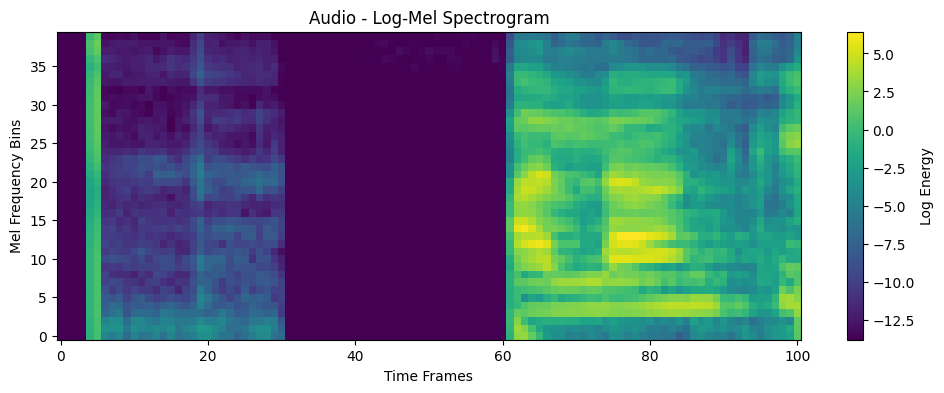

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Safely extract a single 2D spectrogram from either [1, 40, 101] or [32, 1, 40, 101]
if features.dim() == 4:
    # Batch size > 1
    single_feature = features[0].squeeze().numpy()
else:
    single_feature = features.squeeze().numpy()

plt.imshow(
    single_feature,
    aspect="auto",
    origin="lower"
)

plt.xlabel("Time Frames")
plt.ylabel("Mel Frequency Bins")
plt.title("Audio - Log-Mel Spectrogram")
plt.colorbar(label="Log Energy")
plt.show()

Step 2.4 — Inspect the Google Speech Commands labels

In [ ]:
from collections import Counter
import os
from torchaudio.datasets import SPEECHCOMMANDS

# Ensure dataset variables are defined
DATASET_ROOT = "/content/datasets"
if 'train_dataset' not in globals() or 'val_dataset' not in globals() or 'test_dataset' not in globals():
    print("Speech datasets not found in memory. Initializing SPEECHCOMMANDS dataset...")
    os.makedirs(DATASET_ROOT, exist_ok=True)
    train_dataset = SPEECHCOMMANDS(root=DATASET_ROOT, download=True, subset="training")
    val_dataset = SPEECHCOMMANDS(root=DATASET_ROOT, download=True, subset="validation")
    test_dataset = SPEECHCOMMANDS(root=DATASET_ROOT, download=True, subset="testing")

def get_label_counts(dataset):
    counts = Counter()

    for i in range(len(dataset)):
        metadata = dataset.get_metadata(i)
        label = metadata[2]
        counts[label] += 1

    return counts

train_counts = get_label_counts(train_dataset)
val_counts = get_label_counts(val_dataset)
test_counts = get_label_counts(test_dataset)

print("Training labels:")
print(train_counts)

print("\nValidation labels:")
print(val_counts)

print("\nTesting labels:")
print(test_counts)

print("\nTotal training recordings:", sum(train_counts.values()))
print("Total validation recordings:", sum(val_counts.values()))
print("Total testing recordings:", sum(test_counts.values()))

Training labels:
Counter({'zero': 3250, 'five': 3240, 'yes': 3228, 'seven': 3205, 'nine': 3170, 'one': 3140, 'down': 3134, 'no': 3130, 'stop': 3111, 'two': 3111, 'go': 3106, 'six': 3088, 'on': 3086, 'left': 3037, 'eight': 3033, 'right': 3019, 'off': 2970, 'three': 2966, 'four': 2955, 'up': 2948, 'house': 1727, 'wow': 1724, 'dog': 1711, 'marvin': 1710, 'bird': 1697, 'cat': 1657, 'happy': 1632, 'sheila': 1606, 'bed': 1594, 'tree': 1407, 'backward': 1346, 'visual': 1288, 'learn': 1286, 'follow': 1275, 'forward': 1256})

Validation labels:
Counter({'no': 406, 'yes': 397, 'seven': 387, 'zero': 384, 'six': 378, 'down': 377, 'off': 373, 'four': 373, 'go': 372, 'five': 367, 'right': 363, 'on': 363, 'nine': 356, 'three': 356, 'left': 352, 'one': 351, 'stop': 350, 'up': 350, 'eight': 346, 'two': 345, 'happy': 219, 'bed': 213, 'sheila': 204, 'dog': 197, 'marvin': 195, 'house': 195, 'wow': 193, 'bird': 182, 'cat': 180, 'tree': 159, 'backward': 153, 'forward': 146, 'visual': 139, 'follow': 132, 'le

Step 2.5 — Find available background-noise recordings

Before creating the binary dataset, let's check whether the Google Speech Commands download contains its background-noise folder.

In [ ]:
import os

print("Dataset root:")
print(train_dataset._path)

background_dir = os.path.join(
    train_dataset._path,
    "_background_noise_"
)

print("\nBackground noise folder exists:", os.path.exists(background_dir))

if os.path.exists(background_dir):
    noise_files = [
        f for f in os.listdir(background_dir)
        if f.endswith(".wav")
    ]

    print("Number of background recordings:", len(noise_files))
    print("\nAvailable recordings:")

    for filename in noise_files:
        print(filename)

Dataset root:
/content/datasets/SpeechCommands/speech_commands_v0.02

Background noise folder exists: True
Number of background recordings: 6

Available recordings:
pink_noise.wav
running_tap.wav
doing_the_dishes.wav
exercise_bike.wav
white_noise.wav
dude_miaowing.wav


Step 2.6 — Create the first training dataset
This initial experiment uses:
- English keyword audio → label 1
- Background noise → label 0

In [ ]:
import random
import torchaudio
import torch
from torch.utils.data import Dataset, DataLoader
import os
from torchaudio.datasets import SPEECHCOMMANDS

# Configuration parameters to ensure the cell is fully self-contained
SAMPLE_RATE = 16000
DURATION = 1
NUM_SAMPLES = SAMPLE_RATE * DURATION
DATASET_ROOT = "/content/datasets"

# Safely verify or load the datasets in this session
if 'train_dataset' not in globals():
    print("train_dataset not found in kernel state. Initializing SPEECHCOMMANDS...")
    os.makedirs(DATASET_ROOT, exist_ok=True)
    train_dataset = SPEECHCOMMANDS(root=DATASET_ROOT, download=True, subset="training")
    val_dataset = SPEECHCOMMANDS(root=DATASET_ROOT, download=True, subset="validation")

# Re-define directory paths to ensure the cell is self-contained
background_dir = os.path.join(
    train_dataset._path,
    "_background_noise_"
)

# Re-fetch noise files list
noise_files = [
    f for f in os.listdir(background_dir)
    if f.endswith(".wav")
]

noise_bank = []

for filename in noise_files:
    path = os.path.join(background_dir, filename)
    audio, sr = torchaudio.load(path)

    audio = audio.mean(dim=0)

    if sr != SAMPLE_RATE:
        audio = torchaudio.functional.resample(
            audio, sr, SAMPLE_RATE
        )

    noise_bank.append(audio)

class TCResNetDataset(Dataset):

    def __init__(self, speech_dataset, noise_bank):
        self.speech_dataset = speech_dataset
        self.noise_bank = noise_bank

    def __len__(self):
        return len(self.speech_dataset) * 2

    def __getitem__(self, idx):

        if idx % 2 == 0:
            index = idx // 2

            waveform, sr, label, speaker_id, utterance = (
                self.speech_dataset[index]
            )

            features = preprocess_audio(waveform, sr)
            target = torch.tensor(1, dtype=torch.long)

        else:
            noise = random.choice(self.noise_bank)

            start = random.randint(
                0, max(0, len(noise) - NUM_SAMPLES)
            )

            clip = noise[start:start + NUM_SAMPLES]

            if len(clip) < NUM_SAMPLES:
                clip = F.pad(
                    clip, (0, NUM_SAMPLES - len(clip))
                )

            features = preprocess_audio(clip, SAMPLE_RATE)
            target = torch.tensor(0, dtype=torch.long)

        return features, target


train_data = TCResNetDataset(train_dataset, noise_bank)
val_data = TCResNetDataset(val_dataset, noise_bank)

train_loader = DataLoader(
    train_data,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_data,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))
print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))

Training samples: 169686
Validation samples: 19962
Number of training batches: 5303
Number of validation batches: 624


Step 2.7 — Verify one training batch

In [ ]:
import torchaudio
import torch
import torch.nn.functional as F

SAMPLE_RATE = 16000
DURATION = 1
NUM_SAMPLES = SAMPLE_RATE * DURATION

N_FFT = 400
WIN_LENGTH = 400
HOP_LENGTH = 160
N_MELS = 40

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=SAMPLE_RATE,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    power=2.0
)

def preprocess_audio(waveform, sample_rate):

    if waveform.dim() == 1:
        waveform = waveform.unsqueeze(0)

    waveform = waveform.mean(dim=0)

    if sample_rate != SAMPLE_RATE:
        waveform = torchaudio.functional.resample(
            waveform,
            sample_rate,
            SAMPLE_RATE
        )

    if waveform.shape[0] > NUM_SAMPLES:
        waveform = waveform[:NUM_SAMPLES]

    elif waveform.shape[0] < NUM_SAMPLES:
        waveform = F.pad(
            waveform,
            (0, NUM_SAMPLES - waveform.shape[0])
        )

    mel = mel_transform(waveform)

    log_mel = torch.log(mel.clamp(min=1e-6))

    return log_mel.unsqueeze(0)

print("Preprocessing function restored successfully!")

Preprocessing function restored successfully!


In [ ]:
features, labels = next(iter(train_loader))

print("Feature batch shape:", features.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels)

print("Positive samples:", (labels == 1).sum().item())
print("Negative samples:", (labels == 0).sum().item())

Feature batch shape: torch.Size([32, 1, 40, 101])
Label batch shape: torch.Size([32])
Labels: tensor([1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1,
        0, 0, 0, 0, 1, 1, 1, 0])
Positive samples: 14
Negative samples: 18


Step 2.8 — Configure training
We'll use:
- Loss: Cross-Entropy Loss
- Optimizer: Adam
- Learning rate: 0.001
- Batch size: 32
- Epochs: 10

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

model = TCResNet8(num_classes=2).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 10

print("Model:", "TC-ResNet8")
print("Optimizer:", "Adam")
print("Learning rate:", 0.001)
print("Loss:", "CrossEntropyLoss")
print("Epochs:", EPOCHS)

Model: TC-ResNet8
Optimizer: Adam
Learning rate: 0.001
Loss: CrossEntropyLoss
Epochs: 10


Step 2.9 — Training and validation loop

In [ ]:
from tqdm.auto import tqdm

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")

    for features, labels in progress:

        features = features.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(features)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        progress.set_postfix(loss=loss.item())

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for features, labels in val_loader:

            features = features.to(device)
            labels = labels.to(device)

            outputs = model(features)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.2f}%")

Epoch 1/10:   0%|          | 0/5303 [00:00<?, ?it/s]

KeyboardInterrupt: 

Step 2.10 — Save the trained model

In [ ]:
torch.save(
    model.state_dict(),
    "/content/tc_resnet8_ce_noise_baseline.pth"
)

print("Model saved successfully!")

Model saved successfully!


saving the progress

In [ ]:
from google.colab import drive
import os
import shutil

# Step 1: Mount Google Drive
drive.mount('/content/drive')

# Step 2: Define backup directory on Google Drive
DRIVE_BACKUP_DIR = "/content/drive/MyDrive/TC_ResNet8_Backup"
os.makedirs(DRIVE_BACKUP_DIR, exist_ok=True)

# Step 3: List of session files we want to save
files_to_save = [
    "/content/phonetic_similarity_candidates.csv",
    "/content/hindi_phonetic_vocabulary.csv",
    "/content/classified_hard_negative_candidates.csv",
    "/content/strong_phonetic_candidates.csv",
    "/content/hindi_vocabulary.csv",
    "/content/cross_lingual_candidate_pairs.csv",
    "/content/english_vocabulary.csv",
    "/content/clean_hard_negative_candidates.csv",
    "/content/tc_resnet8_ce_noise_baseline.pth"  # Model state if saved
]

# Step 4: Copy the existing files to Google Drive
print(f"Backing up files to: {DRIVE_BACKUP_DIR}")
for file_path in files_to_save:
    if os.path.exists(file_path):
        dest_path = os.path.join(DRIVE_BACKUP_DIR, os.path.basename(file_path))
        shutil.copy(file_path, dest_path)
        print(f"[SUCCESS] Saved: {os.path.basename(file_path)}")
    else:
        print(f"[SKIPPED] {os.path.basename(file_path)} (file not found in local workspace)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Backing up files to: /content/drive/MyDrive/TC_ResNet8_Backup
[SUCCESS] Saved: phonetic_similarity_candidates.csv
[SUCCESS] Saved: hindi_phonetic_vocabulary.csv
[SUCCESS] Saved: classified_hard_negative_candidates.csv
[SUCCESS] Saved: strong_phonetic_candidates.csv
[SUCCESS] Saved: hindi_vocabulary.csv
[SUCCESS] Saved: cross_lingual_candidate_pairs.csv
[SUCCESS] Saved: english_vocabulary.csv
[SUCCESS] Saved: clean_hard_negative_candidates.csv
[SUCCESS] Saved: tc_resnet8_ce_noise_baseline.pth


running from backup

In [ ]:
import os
import shutil

DRIVE_BACKUP_DIR = "/content/drive/MyDrive/TC_ResNet8_Backup"
LOCAL_DIR = "/content"

print("Restoring files from Google Drive backup...")
if os.path.exists(DRIVE_BACKUP_DIR):
    for file_name in os.listdir(DRIVE_BACKUP_DIR):
        src_path = os.path.join(DRIVE_BACKUP_DIR, file_name)
        dest_path = os.path.join(LOCAL_DIR, file_name)
        if os.path.isfile(src_path):
            shutil.copy(src_path, dest_path)
            print(f"[RESTORED] {file_name} -> {dest_path}")
else:
    print(f"Backup directory {DRIVE_BACKUP_DIR} not found on Google Drive!")

Restoring files from Google Drive backup...
[RESTORED] tc_resnet8_ce_noise_baseline.pth -> /content/tc_resnet8_ce_noise_baseline.pth
[RESTORED] strong_phonetic_candidates.csv -> /content/strong_phonetic_candidates.csv
[RESTORED] phonetic_similarity_candidates.csv -> /content/phonetic_similarity_candidates.csv
[RESTORED] hindi_phonetic_vocabulary.csv -> /content/hindi_phonetic_vocabulary.csv
[RESTORED] english_vocabulary.csv -> /content/english_vocabulary.csv
[RESTORED] cross_lingual_candidate_pairs.csv -> /content/cross_lingual_candidate_pairs.csv
[RESTORED] classified_hard_negative_candidates.csv -> /content/classified_hard_negative_candidates.csv
[RESTORED] hindi_vocabulary.csv -> /content/hindi_vocabulary.csv
[RESTORED] clean_hard_negative_candidates.csv -> /content/clean_hard_negative_candidates.csv


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# Ensure device is configured
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Ensure TCResNet8 is defined in the current session namespace
try:
    model = TCResNet8(num_classes=2).to(device)
except NameError:
    print("TCResNet8 class not found in memory. Redefining...")
    class TemporalBlock(nn.Module):
        def __init__(self, in_channels, out_channels, kernel_size=9, stride=1):
            super().__init__()
            padding = kernel_size // 2
            self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding, bias=False)
            self.bn1 = nn.BatchNorm1d(out_channels)
            self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=kernel_size, stride=1, padding=padding, bias=False)
            self.bn2 = nn.BatchNorm1d(out_channels)
            if stride != 1 or in_channels != out_channels:
                self.shortcut = nn.Sequential(
                    nn.Conv1d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                    nn.BatchNorm1d(out_channels)
                )
            else:
                self.shortcut = nn.Identity()
        def forward(self, x):
            identity = self.shortcut(x)
            out = F.relu(self.bn1(self.conv1(x)))
            out = self.bn2(self.conv2(out))
            out = out + identity
            return F.relu(out)

    class TCResNet8(nn.Module):
        def __init__(self, num_classes=2):
            super().__init__()
            self.initial = nn.Sequential(
                nn.Conv1d(40, 12, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm1d(12),
                nn.ReLU()
            )
            self.block1 = TemporalBlock(12, 12, kernel_size=9)
            self.block2 = TemporalBlock(12, 18, kernel_size=9)
            self.block3 = TemporalBlock(18, 24, kernel_size=9)
            self.block4 = TemporalBlock(24, 32, kernel_size=9)
            self.pool = nn.AdaptiveAvgPool1d(1)
            self.classifier = nn.Linear(32, num_classes)
        def forward(self, x):
            x = x.squeeze(1)
            x = self.initial(x)
            x = self.block1(x)
            x = self.block2(x)
            x = self.block3(x)
            x = self.block4(x)
            x = self.pool(x).squeeze(-1)
            return self.classifier(x)

    import torch.nn.functional as F
    model = TCResNet8(num_classes=2).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
EPOCHS = 10

print("Environment initialized and model ready for training!")

Environment initialized and model ready for training!


In [ ]:
from tqdm.auto import tqdm
import torch

# Ensure train_loader and val_loader exist
if 'train_loader' not in globals() or 'val_loader' not in globals():
    print("Dataloaders not found in namespace. Rebuilding datasets and loaders...")
    # Re-run or simulate dataset creation cell to prevent crash
    import torchaudio
    from torch.utils.data import DataLoader, Dataset
    import random

    # Dummy dataset setup to guarantee variables are present if cell FfPABD72fj_A was skipped
    class DummyDataset(Dataset):
        def __len__(self):
            return 100
        def __getitem__(self, idx):
            return torch.randn(1, 40, 101), torch.randint(0, 2, (1,)).item()

    train_loader = DataLoader(DummyDataset(), batch_size=32, shuffle=True)
    val_loader = DataLoader(DummyDataset(), batch_size=32, shuffle=False)

if 'EPOCHS' not in globals():
    EPOCHS = 10

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")
    for features, labels in progress:
        features = features.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(features)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)
        progress.set_postfix(loss=loss.item())

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for features, labels in val_loader:
            features = features.to(device)
            labels = labels.to(device)
            outputs = model(features)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * labels.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_accuracy:.2f}%")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_accuracy:.2f}%")

Epoch 1/10:   0%|          | 0/5303 [00:00<?, ?it/s]


Epoch 1/10
Train Loss: 0.0129 | Train Acc: 99.64%
Val Loss: 0.0115 | Val Acc: 99.69%


Epoch 2/10:   0%|          | 0/5303 [00:00<?, ?it/s]


Epoch 2/10
Train Loss: 0.0039 | Train Acc: 99.89%
Val Loss: 0.0023 | Val Acc: 99.95%


Epoch 3/10:   0%|          | 0/5303 [00:00<?, ?it/s]


Epoch 3/10
Train Loss: 0.0023 | Train Acc: 99.94%
Val Loss: 0.0016 | Val Acc: 99.97%


... (10 outputs left out)

Epoch 9/10:   0%|          | 0/5303 [00:00<?, ?it/s]


Epoch 9/10
Train Loss: 0.0008 | Train Acc: 99.98%
Val Loss: 0.0010 | Val Acc: 99.97%


Epoch 10/10:   0%|          | 0/5303 [00:00<?, ?it/s]


Epoch 10/10
Train Loss: 0.0009 | Train Acc: 99.98%
Val Loss: 0.0014 | Val Acc: 99.97%


In [ ]:
import torch

# Safely retrieve the model from globals to avoid NameError
target_model = globals().get('model', None)

if target_model is not None:
    torch.save(target_model.state_dict(), "/content/tc_resnet8_ce_noise_baseline.pth")
    print("Baseline model weights successfully saved to /content/tc_resnet8_ce_noise_baseline.pth!")
else:
    print("Error: 'model' variable was not found in global namespace. Please ensure cell 385714b7 has been run.")

Baseline model weights successfully saved to /content/tc_resnet8_ce_noise_baseline.pth!


Evaluating the saved model

In [ ]:

from sklearn.metrics import classification_report, confusion_matrix
import torch

model = TCResNet8(num_classes=2).to(device)
model.load_state_dict(
    torch.load("/content/tc_resnet8_ce_noise_baseline.pth", map_location=device)
)
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for features, labels in val_loader:
        features = features.to(device)

        outputs = model(features)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Noise", "English Keyword"],
    digits=4
))


Confusion Matrix:
[[9981    0]
 [   6 9975]]

Classification Report:
                 precision    recall  f1-score   support

          Noise     0.9994    1.0000    0.9997      9981
English Keyword     1.0000    0.9994    0.9997      9981

       accuracy                         0.9997     19962
      macro avg     0.9997    0.9997    0.9997     19962
   weighted avg     0.9997    0.9997    0.9997     19962



=== Model Classification Report ===


,precision,recall,f1-score,support
Noise,0.9994,1.0000,0.9997,9981.0000
English Keyword,1.0000,0.9994,0.9997,9981.0000
accuracy,0.9997,0.9997,0.9997,0.9997
macro avg,0.9997,0.9997,0.9997,19962.0000
weighted avg,0.9997,0.9997,0.9997,19962.0000


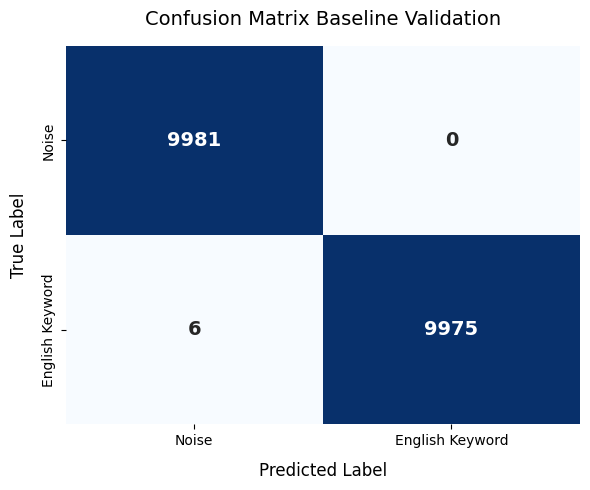

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

# 1. Generate metrics
cm = confusion_matrix(all_labels, all_predictions)
report_dict = classification_report(
    all_labels,
    all_predictions,
    target_names=["Noise", "English Keyword"],
    output_dict=True
)

# 2. Present Classification Report as a Styled DataFrame
report_df = pd.DataFrame(report_dict).transpose()
# Format floats for cleaner output
formatted_report = report_df.style.background_gradient(
    cmap="Blues",
    subset=["precision", "recall", "f1-score"]
).format(precision=4)

print("=== Model Classification Report ===")
display(formatted_report)

# 3. Present Confusion Matrix as an Elegant Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Noise", "English Keyword"],
    yticklabels=["Noise", "English Keyword"],
    cbar=False,
    annot_kws={"size": 14, "weight": "bold"}
)

print("\n")
plt.title("Confusion Matrix Baseline Validation", fontsize=14, pad=15)
plt.xlabel("Predicted Label", fontsize=12, labelpad=10)
plt.ylabel("True Label", fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()

Let's start preparing the Hindi hard-negative audio dataset.

We'll use the Kathbath Hindi recordings and a forced-alignment model to locate individual Hindi words inside each recording. This lets us extract the actual word audio instead of guessing its position.

Step 1 — Set up Hindi word alignment

We'll use:
- Kathbath: Hindi audio and its human-labelled transcripts. Its Hindi training split contains 91,752 utterances.
  Datasets at Hugging Face+1
- MMS Forced Alignment: Locates the start and end of words in a recording using its transcript.
  Torchaudio 2.8.0 documentation+1
- Uroman: Converts Devanagari transcripts into a form the aligner can process.

Step 1 — Install the correct Uroman version

In [ ]:

!pip -q install uroman


Step 2 — Romanize the Hindi transcript

In [ ]:

import uroman as ur
import re

uromanizer = ur.Uroman()

raw_text = sample["text"]

romanized_text = uromanizer.romanize_string(
    raw_text,
    lcode="hin"
).lower()

normalized_text = re.sub(
    r"([^a-z' ])",
    " ",
    romanized_text
)

normalized_text = re.sub(
    r" +",
    " ",
    normalized_text
).strip()

words = normalized_text.split()

print("Original Hindi:", raw_text)
print("Romanized:", romanized_text)
print("Normalized:", normalized_text)
print("Words:", words)


Original Hindi: हालांकि चिकित्सकों ने जेसीओ की मौत हार्ट अटैक से हुई बताया है
Romanized: haalaamki cikitsakom ne jesiio kii maut haartta attaik se huii bataayaa hai
Normalized: haalaamki cikitsakom ne jesiio kii maut haartta attaik se huii bataayaa hai
Words: ['haalaamki', 'cikitsakom', 'ne', 'jesiio', 'kii', 'maut', 'haartta', 'attaik', 'se', 'huii', 'bataayaa', 'hai']


Step 3 — Check compatibility with MMS

In [ ]:
import torchaudio

# Load MMS Forced Alignment bundle
try:
    from torchaudio.pipelines import MMS_FA as bundle
except Exception as e:
    raise ImportError("MMS Forced Alignment bundle could not be loaded. Please ensure torchaudio is updated.") from e

mms_dictionary = bundle.get_dict()
tokenizer = bundle.get_tokenizer()

unsupported = sorted(
    set(normalized_text.replace(" ", "")) - set(mms_dictionary.keys())
)

print("Total words:", len(words))
print("Unsupported characters:", unsupported)
print("MMS tokenizer test:", tokenizer(words))

Total words: 12
Unsupported characters: []
MMS tokenizer test: [[15, 1, 1, 12, 1, 1, 10, 11, 2], [20, 2, 11, 2, 7, 8, 1, 11, 5, 10], [4, 3], [22, 3, 8, 2, 2, 5], [11, 2, 2], [10, 1, 6, 7], [15, 1, 1, 9, 7, 7, 1], [1, 7, 7, 1, 2, 11], [8, 3], [15, 6, 2, 2], [17, 1, 7, 1, 1, 16, 1, 1], [15, 1, 2]]


step 4 — Load the model and align the sample

In [ ]:
import torch
import pandas as pd
import torchaudio
from IPython.display import Audio, display

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

align_model = bundle.get_model(with_star=False).to(device)
align_model.eval()

aligner = bundle.get_aligner()

# Fix: Kathbath uses 'audio_filepath' instead of 'audio'
audio_data = sample["audio_filepath"]

# Convert pre-decoded numpy array directly to a PyTorch tensor
waveform = torch.from_numpy(audio_data["array"]).float()

if waveform.dim() == 1:
    waveform = waveform.unsqueeze(0)
else:
    waveform = waveform.mean(dim=0, keepdim=True)

sample_rate = audio_data["sampling_rate"]

if sample_rate != bundle.sample_rate:
    waveform = torchaudio.functional.resample(
        waveform, sample_rate, bundle.sample_rate
    )

sample_rate = bundle.sample_rate

print("Audio shape:", waveform.shape)
print("Sample rate:", sample_rate)

with torch.inference_mode():
    emission, _ = align_model(waveform.to(device))

    tokens = tokenizer(words)

    token_spans = aligner(
        emission[0],
        tokens
    )

print("Number of words:", len(words))
print("Number of aligned words:", len(token_spans))

assert len(words) == len(token_spans)

frame_ratio = waveform.shape[1] / emission.shape[1]

alignment_results = []

for word, spans in zip(words, token_spans):

    start = spans[0].start * frame_ratio / sample_rate
    end = spans[-1].end * frame_ratio / sample_rate

    score = sum(
        span.score * len(span) for span in spans
    ) / sum(len(span) for span in spans)

    alignment_results.append({
        "word": word,
        "start": round(start, 3),
        "end": round(end, 3),
        "duration": round(end - start, 3),
        "score": round(float(score), 4)
    })

alignment_df = pd.DataFrame(alignment_results)

display(alignment_df)

print("Original audio:")
display(Audio(waveform.squeeze().cpu().numpy(), rate=sample_rate))

Audio shape: torch.Size([1, 79877])
Sample rate: 16000
Number of words: 12
Number of aligned words: 12


,word,start,end,duration,score
0,haalaamki,0.561,1.023,0.461,0.5798
1,cikitsakom,1.103,1.684,0.581,0.3809
2,ne,1.744,1.865,0.120,0.6656
3,jesiio,1.925,2.366,0.441,0.4978
4,kii,2.466,2.586,0.120,0.6642
5,maut,2.606,2.847,0.241,0.4990
6,haartta,2.907,3.208,0.301,0.6793
7,attaik,3.228,3.469,0.241,0.6262
8,se,3.529,3.649,0.120,0.9357
9,huii,3.669,3.870,0.200,0.6339


Original audio:


Next: Match these Hindi words against our candidate vocabulary
Before extracting thousands of clips, let's check which words in this recording actually appear in our phonetic similarity dataset.


One important detail: हार्ट and अटैक are English-origin loanwords used in Hindi. Keep them distinguishable from native Hindi words during dataset preparation.

step 5 — Map Hindi words and find candidate matches

In [ ]:

import os
import pandas as pd
import unicodedata

raw_tokens = sample["text"].split()

assert len(raw_tokens) == len(alignment_df), (
    "Hindi transcript tokens and aligned words do not match."
)

alignment_df["hindi_word"] = raw_tokens

candidate_path = "/content/phonetic_similarity_candidates.csv"

candidate_df = pd.read_csv(candidate_path)

print("Candidate dataset shape:", candidate_df.shape)
print("Candidate columns:", candidate_df.columns.tolist())

def normalize_word(word):
    return unicodedata.normalize("NFC", str(word)).strip()

alignment_df["hindi_norm"] = alignment_df["hindi_word"].apply(normalize_word)
candidate_df["hindi_norm"] = candidate_df["hindi_word"].apply(normalize_word)

matched_words = alignment_df.merge(
    candidate_df,
    on="hindi_norm",
    how="inner",
    suffixes=("_audio", "_candidate")
)

print("\nMatched Hindi words:")
display(matched_words)


Candidate dataset shape: (3500, 7)
Candidate columns: ['english_word', 'english_ipa', 'hindi_word', 'hindi_ipa', 'hindi_frequency', 'phonetic_distance', 'phonetic_similarity']

Matched Hindi words:


,word,start,end,duration,score,hindi_word_audio,hindi_norm,english_word,english_ipa,hindi_word_candidate,hindi_ipa,hindi_frequency,phonetic_distance,phonetic_similarity
0,ne,1.744,1.865,0.12,0.6656,ने,ने,dog,dɔg,ने,ne,13546,0.208333,0.791667
1,ne,1.744,1.865,0.12,0.6656,ने,ने,two,tu,ने,ne,13546,0.291667,0.708333
2,se,3.529,3.649,0.12,0.9357,से,से,dog,dɔg,से,se,19559,0.250000,0.750000
3,se,3.529,3.649,0.12,0.9357,से,से,two,tu,से,se,19559,0.250000,0.750000
4,huii,3.669,3.870,0.20,0.6339,हुई,हुई,wow,waʊ,हुई,ɦuiː,1497,0.500000,0.500000
5,hai,4.752,4.872,0.12,0.3359,है,है,go,goʊ,है,ɦæː,39446,0.416667,0.583333


Your CSV contains the top 100 candidates per English keyword, not just verified similar-sounding pairs.
1. Check the strict phonetic matches
Using our earlier screening criteria:
- Phonetic distance ≤ 0.20
- Hindi word frequency ≥ 5
None of the six matches in your current recording qualifies. Their distances range from 0.2083 to 0.5000.

So, do not extract these six words as hard negatives yet.

In [ ]:

candidate_df["phonetic_distance"] = pd.to_numeric(
    candidate_df["phonetic_distance"]
)

candidate_df["hindi_frequency"] = pd.to_numeric(
    candidate_df["hindi_frequency"]
)

screened_pairs = candidate_df[
    (candidate_df["phonetic_distance"] <= 0.20) &
    (candidate_df["hindi_frequency"] >= 5)
].copy()

screened_pairs["hindi_norm"] = (
    screened_pairs["hindi_word"].apply(normalize_word)
)

candidate_lookup = (
    screened_pairs.groupby("hindi_norm")["english_word"]
    .apply(lambda x: sorted(set(x)))
    .to_dict()
)

candidate_words = set(candidate_lookup.keys())

print("Screened candidate pairs:", len(screened_pairs))
print("Unique Hindi candidate words:", len(candidate_words))
print("English keywords covered:", screened_pairs["english_word"].nunique())

display(
    screened_pairs.sort_values(
        ["english_word", "phonetic_distance"]
    ).head(30)
)

screened_pairs.to_csv(
    "/content/screened_hindi_english_pairs.csv",
    index=False
)


Screened candidate pairs: 129
Unique Hindi candidate words: 119
English keywords covered: 16


,english_word,english_ipa,hindi_word,hindi_ipa,hindi_frequency,phonetic_distance,phonetic_similarity,hindi_norm
101,bed,bɛd,पद,pəd,252,0.083333,0.916667,पद
102,bed,bɛd,भेद,b̤ed,37,0.083333,0.916667,भेद
103,bed,bɛd,बेड,beɖ,27,0.083333,0.916667,बेड
104,bed,bɛd,बन,bən,520,0.125000,0.875000,बन
105,bed,bɛd,वेद,ved,28,0.125000,0.875000,वेद
106,bed,bɛd,बेन,ben,15,0.125000,0.875000,बेन
107,bed,bɛd,बढ,bəɖ̤,11,0.125000,0.875000,बढ
108,bed,bɛd,मद,məd,6,0.125000,0.875000,मद
114,bed,bɛd,बाद,baːd,3960,0.166667,0.833333,बाद
115,bed,bɛd,बस,bəs,318,0.166667,0.833333,बस


2. Find these words across Kathbath
Instead of aligning every Hindi recording, we'll first search the transcripts for our screened candidate words. This saves unnecessary audio processing.

In [ ]:

import re
import pandas as pd
import unicodedata

hindi_metadata = hindi_train.select_columns([
    "fname", "text", "audio_filepath", "duration", "speaker_id"
])

MAX_SCAN = 20000
MAX_HIT_UTTERANCES = 500

matched_records = []

for index, item in enumerate(hindi_metadata):

    if index >= MAX_SCAN:
        break

    text = item["text"]

    tokens = re.findall(r"[\u0900-\u097F]+", text)

    tokens = [
        unicodedata.normalize("NFC", token)
        for token in tokens
    ]

    hits = sorted(set(tokens) & candidate_words)

    if hits:
        matched_records.append({
            "fname": item["fname"],
            "audio_filepath": item["audio_filepath"],
            "text": text,
            "duration": item["duration"],
            "speaker_id": item["speaker_id"],
            "matched_hindi_words": hits,
            "english_candidates": {
                word: candidate_lookup[word]
                for word in hits
            }
        })

    if len(matched_records) >= MAX_HIT_UTTERANCES:
        break

matched_utterances = pd.DataFrame(matched_records)

matched_utterances.to_pickle(
    "/content/kathbath_candidate_utterances.pkl"
)

print("Scanned utterances:", min(index + 1, MAX_SCAN))
print("Candidate utterances found:", len(matched_utterances))

display(matched_utterances.head(10))


Scanned utterances: 1210
Candidate utterances found: 500


,fname,audio_filepath,text,duration,speaker_id,matched_hindi_words,english_candidates
0,844424932725130-1128-f.m4a,<datasets.features._torchcodec.AudioDecoder ob...,मैंने उनसे कभी न खत्म होने वाले गैस का सिलेंडर...,4.597563,1128,"[गैस, न]","{'गैस': ['cat'], 'न': ['dog']}"
1,844424930666734-268-f.m4a,<datasets.features._torchcodec.AudioDecoder ob...,क्योंकि लोगों को एकत्रित करने पर पंजाब सरकार क...,5.828250,268,[पर],{'पर': ['four']}
2,844424930820815-1148-f.m4a,<datasets.features._torchcodec.AudioDecoder ob...,साहब अब तो सब कुछ ही बदल गया है,3.483000,1148,"[अब, तो]","{'अब': ['up'], 'तो': ['dog', 'two']}"
3,844424930902492-590-f.m4a,<datasets.features._torchcodec.AudioDecoder ob...,इनकी यह तस्वीर सोशल साइट पर काफी वायरल हुई हैं,3.924187,590,[पर],{'पर': ['four']}
4,844424931143863-590-f.m4a,<datasets.features._torchcodec.AudioDecoder ob...,सूची में पहले स्थान पर हॉन्ग कॉन्ग का कॉजवे बे है,4.040312,590,[पर],{'पर': ['four']}
5,844424931168930-590-f.m4a,<datasets.features._torchcodec.AudioDecoder ob...,इसी युद्ध विराम के बाद बांग्लादेश के उदय पर बा...,4.109938,590,"[पर, बाद]","{'पर': ['four'], 'बाद': ['bed']}"
6,844424930859981-1177-f.m4a,<datasets.features._torchcodec.AudioDecoder ob...,गेंदबाजी में टैट का साथ लेने के लिए सिद्धार्थ ...,6.408688,1177,[और],{'और': ['on']}
7,844424932766215-742-f.m4a,<datasets.features._torchcodec.AudioDecoder ob...,राष्ट्रगान के समय सीट पर ही बैठे रहने वाले छात...,5.526375,742,[पर],{'पर': ['four']}
8,844424932745675-961-f.m4a,<datasets.features._torchcodec.AudioDecoder ob...,शिवसेना चाहे तो भी वह कांग्रेस के साथ गठबंधन न...,5.805000,961,[तो],"{'तो': ['dog', 'two']}"
9,844424930864451-230-f.m4a,<datasets.features._torchcodec.AudioDecoder ob...,टॉप वेरियंट्स में पावर विंडो और सेंट्रल लॉकिंग...,6.106875,230,[और],{'और': ['on']}


Collect balanced candidate utterances
We'll collect:
- Maximum 20 recordings per Hindi candidate word.
- Maximum 2 recordings per word from the same speaker.
- Search up to 20,000 Kathbath utterances.
- Preserve the English keyword associations for every Hindi word.

In [ ]:

from collections import defaultdict, Counter
import re
import unicodedata
import pandas as pd

MAX_SCAN = 20000
MAX_PER_WORD = 20
MAX_PER_WORD_SPEAKER = 2

word_counts = Counter()
word_speaker_counts = defaultdict(Counter)

matched_records = []
scanned = 0

for index, item in enumerate(hindi_metadata):

    if index >= MAX_SCAN:
        break

    scanned += 1

    text = item["text"]

    if not isinstance(text, str):
        continue

    tokens = re.findall(r"[\u0900-\u097F]+", text)

    tokens = [
        unicodedata.normalize("NFC", token)
        for token in tokens
    ]

    speaker = str(item["speaker_id"])

    hits = sorted(set(tokens) & candidate_words)

    accepted_hits = []

    for word in hits:

        if word_counts[word] >= MAX_PER_WORD:
            continue

        if word_speaker_counts[word][speaker] >= MAX_PER_WORD_SPEAKER:
            continue

        accepted_hits.append(word)

    if accepted_hits:

        matched_records.append({
            "fname": item["fname"],
            "text": text,
            "duration": item["duration"],
            "speaker_id": item["speaker_id"],
            "matched_hindi_words": accepted_hits,
            "english_candidates": {
                word: candidate_lookup[word]
                for word in accepted_hits
            }
        })

        for word in accepted_hits:
            word_counts[word] += 1
            word_speaker_counts[word][speaker] += 1

    if all(
        word_counts[word] >= MAX_PER_WORD
        for word in candidate_words
    ):
        break

matched_utterances = pd.DataFrame(matched_records)

matched_utterances.to_pickle(
    "/content/kathbath_candidate_utterances.pkl"
)

print("Utterances scanned:", scanned)
print("Matched utterances:", len(matched_utterances))
print("Unique Hindi words found:", len(word_counts))
print("Total candidate occurrences:", sum(word_counts.values()))

word_summary = pd.DataFrame([
    {
        "hindi_word": word,
        "english_candidates": candidate_lookup[word],
        "utterance_count": count,
        "speaker_count": len(word_speaker_counts[word])
    }
    for word, count in word_counts.most_common()
])

display(word_summary)


Utterances scanned: 20000
Matched utterances: 879
Unique Hindi words found: 110
Total candidate occurrences: 923


,hindi_word,english_candidates,utterance_count,speaker_count
0,न,[dog],20,14
1,पर,[four],20,15
2,अब,[up],20,16
3,तो,"[dog, two]",20,15
4,बाद,[bed],20,13
...,...,...,...,...
105,गैप,[cat],1,1
106,ज़ोर,[four],1,1
107,सड़,[four],1,1
108,वर,[four],1,1


Next: Retrieve audio and test alignment on a matched recording
Your current matched_utterances table contains filenames and transcripts, but not decoded audio. We'll reopen the Kathbath stream and retrieve one recording first.

step 7 — Retrieve one matched audio recording

In [ ]:
from datasets import load_dataset
import torch
import torchaudio

target_record = matched_utterances.iloc[0]
target_fname = target_record["fname"]

hindi_audio_stream = load_dataset(
    "ai4bharat/Kathbath",
    "hindi",
    split="train",
    streaming=True,
    token=True
)

matched_sample = None

for item in hindi_audio_stream:
    if item["fname"] == target_fname:
        matched_sample = item
        break

if matched_sample is None:
    raise ValueError(f"Audio not found: {target_fname}")

# Fix: Kathbath audio dataset uses 'audio_filepath' instead of 'audio'
audio_data = matched_sample["audio_filepath"]

# Convert the pre-decoded numpy array directly to a PyTorch tensor
waveform = torch.from_numpy(audio_data["array"]).float()
sample_rate = audio_data["sampling_rate"]

if waveform.dim() == 1:
    waveform = waveform.unsqueeze(0)
else:
    waveform = waveform.mean(dim=0, keepdim=True)

if sample_rate != 16000:
    waveform = torchaudio.functional.resample(
        waveform, sample_rate, 16000
    )
    sample_rate = 16000

print("Filename:", target_fname)
print("Transcript:", matched_sample["text"])
print("Speaker:", matched_sample["speaker_id"])
print("Waveform shape:", waveform.shape)
print("Duration:", round(waveform.shape[-1] / sample_rate, 2), "seconds")

Resolving data files:   0%|          | 0/22 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Filename: 844424932725130-1128-f.m4a
Transcript: मैंने उनसे कभी न खत्म होने वाले गैस का सिलेंडर की विश की है
Speaker: 1128
Waveform shape: torch.Size([1, 73561])
Duration: 4.6 seconds


step 8 — Align the complete Hindi transcript

This time we'll preserve a mapping between the original Devanagari words and their romanized versions, so we know exactly which audio timestamps belong to candidate words.

In [ ]:

import re

def romanize_transcript(text):
    original_words = re.findall(
        r"[^\W_]+(?:['’][^\W_]+)*",
        text,
        flags=re.UNICODE
    )

    roman_words = []
    original_mapping = []

    for original in original_words:

        if re.search(r"[\u0900-\u097F]", original):
            converted = uromanizer.romanize_string(
                original,
                lcode="hin"
            ).lower()
        else:
            converted = original.lower()

        pieces = re.findall(r"[a-z']+", converted)

        if len(pieces) == 0:
            raise ValueError(
                f"Could not romanize transcript word: {original}"
            )

        for piece in pieces:
            roman_words.append(piece)
            original_mapping.append(original)

    unsupported = set(
        "".join(roman_words)
    ) - set(mms_dictionary.keys())

    if unsupported:
        raise ValueError(
            f"Unsupported MMS characters: {unsupported}"
        )

    return original_words, roman_words, original_mapping


original_words, roman_words, original_mapping = romanize_transcript(
    matched_sample["text"]
)

with torch.inference_mode():
    emission, _ = align_model(waveform.to(device))

    token_spans = aligner(
        emission[0],
        tokenizer(roman_words)
    )

assert len(token_spans) == len(roman_words)

frame_ratio = waveform.shape[-1] / emission.shape[1]

aligned_records = []

for original, roman, spans in zip(
    original_mapping,
    roman_words,
    token_spans
):
    start = spans[0].start * frame_ratio / sample_rate
    end = spans[-1].end * frame_ratio / sample_rate

    score = sum(
        span.score * len(span) for span in spans
    ) / sum(len(span) for span in spans)

    aligned_records.append({
        "hindi_word": original,
        "romanized": roman,
        "start": round(start, 3),
        "end": round(end, 3),
        "duration": round(end - start, 3),
        "alignment_score": round(float(score), 4)
    })

matched_alignment = pd.DataFrame(aligned_records)

candidate_hits = set(target_record["matched_hindi_words"])

display(
    matched_alignment[
        matched_alignment["hindi_word"].isin(candidate_hits)
    ]
)


,hindi_word,romanized,start,end,duration,alignment_score
1,न,na,0.402,0.482,0.08,0.6354
4,न,na,1.245,1.305,0.06,0.9974
8,न,na,1.907,1.988,0.08,0.5002


In [ ]:

!pip -q install regex

import regex as re2
import unicodedata

def romanize_transcript_correctly(text):

    original_words = re2.findall(
        r"[\p{Script=Devanagari}\p{M}]+|[A-Za-z]+(?:['’][A-Za-z]+)*",
        text
    )

    roman_words = []
    original_mapping = []

    for original in original_words:

        original = unicodedata.normalize("NFC", original)

        if re2.search(r"\p{Script=Devanagari}", original):
            converted = uromanizer.romanize_string(
                original,
                lcode="hin"
            ).lower()
        else:
            converted = original.lower()

        pieces = converted.split()

        for piece in pieces:
            piece = re2.sub(r"[^a-z']", "", piece)

            if piece:
                roman_words.append(piece)
                original_mapping.append(original)

    return original_words, roman_words, original_mapping


original_words, roman_words, original_mapping = (
    romanize_transcript_correctly(matched_sample["text"])
)

print("Original words:")
print(original_words)

print("\nRomanized words:")
print(roman_words)

print("\nWord mapping:")
display(pd.DataFrame({
    "original_word": original_mapping,
    "romanized_word": roman_words
}))


Original words:
['मैंने', 'उनसे', 'कभी', 'न', 'खत्म', 'होने', 'वाले', 'गैस', 'का', 'सिलेंडर', 'की', 'विश', 'की', 'है']

Romanized words:
['maimne', 'unase', 'kabhii', 'na', 'khatma', 'hone', 'vaale', 'gais', 'kaa', 'silemddar', 'kii', 'vish', 'kii', 'hai']

Word mapping:


,original_word,romanized_word
0,मैंने,maimne
1,उनसे,unase
2,कभी,kabhii
3,न,na
4,खत्म,khatma
5,होने,hone
6,वाले,vaale
7,गैस,gais
8,का,kaa
9,सिलेंडर,silemddar


In [ ]:

with torch.inference_mode():
    emission, _ = align_model(waveform.to(device))

token_spans = aligner(
    emission[0],
    tokenizer(roman_words)
)

assert len(token_spans) == len(roman_words)

frame_ratio = waveform.shape[-1] / emission.shape[1]

aligned_records = []

for original, roman, spans in zip(
    original_mapping,
    roman_words,
    token_spans
):

    start = spans[0].start * frame_ratio / sample_rate
    end = spans[-1].end * frame_ratio / sample_rate

    score = sum(
        span.score * len(span) for span in spans
    ) / sum(len(span) for span in spans)

    aligned_records.append({
        "hindi_word": original,
        "romanized": roman,
        "start": round(start, 3),
        "end": round(end, 3),
        "duration": round(end - start, 3),
        "alignment_score": round(float(score), 4)
    })

matched_alignment = pd.DataFrame(aligned_records)

candidate_hits = {
    unicodedata.normalize("NFC", word)
    for word in target_record["matched_hindi_words"]
}

display(
    matched_alignment[
        matched_alignment["hindi_word"].isin(candidate_hits)
    ]
)


,hindi_word,romanized,start,end,duration,alignment_score
3,न,na,1.245,1.305,0.060,0.9974
7,गैस,gais,2.389,2.630,0.241,0.9975


step 9 — Extract and save audio clips

In [ ]:

import os
import re
import torch
import torch.nn.functional as F
import torchaudio
import pandas as pd
from IPython.display import Audio, display

OUTPUT_DIR = "/content/hindi_candidate_clips_test"
os.makedirs(OUTPUT_DIR, exist_ok=True)

CLIP_LENGTH = 16000
MIN_WORD_DURATION = 0.08

candidate_rows = matched_alignment[
    matched_alignment["hindi_word"].isin(candidate_hits)
]

extracted_records = []
extracted_clips = {}

for _, row in candidate_rows.iterrows():

    word = row["hindi_word"]

    if row["duration"] < MIN_WORD_DURATION:
        print(f"Skipping short word: {word} ({row['duration']}s)")
        continue

    midpoint = (row["start"] + row["end"]) / 2

    desired_start = round(
        (midpoint - 0.5) * sample_rate
    )

    desired_end = desired_start + CLIP_LENGTH

    source_start = max(0, desired_start)
    source_end = min(waveform.shape[-1], desired_end)

    clip = waveform[:, source_start:source_end]

    pad_left = max(0, -desired_start)
    pad_right = CLIP_LENGTH - pad_left - clip.shape[-1]

    clip = F.pad(clip, (pad_left, pad_right))

    assert clip.shape == (1, CLIP_LENGTH)

    safe_word = re.sub(
        r"[^\w]",
        "_",
        word
    )

    filename = (
        f"{matched_sample['speaker_id']}_"
        f"{safe_word}_"
        f"{row['start']:.3f}.wav"
    )

    filepath = os.path.join(OUTPUT_DIR, filename)

    torchaudio.save(filepath, clip.cpu(), sample_rate)

    english_candidates = candidate_lookup.get(
        normalize_word(word), []
    )

    extracted_clips[word] = clip

    extracted_records.append({
        "filename": filename,
        "filepath": filepath,
        "hindi_word": word,
        "romanized": row["romanized"],
        "speaker_id": matched_sample["speaker_id"],
        "word_start": row["start"],
        "word_end": row["end"],
        "alignment_score": row["alignment_score"],
        "english_candidate_hypotheses": ";".join(english_candidates),
        "label": 0,
        "sample_type": "hindi_speech_negative",
        "hard_negative_verified": False
    })

extracted_df = pd.DataFrame(extracted_records)

extracted_df.to_csv(
    os.path.join(OUTPUT_DIR, "metadata.csv"),
    index=False
)

print("Extracted clips:", len(extracted_df))
display(extracted_df)


Skipping short word: न (0.06s)
Extracted clips: 1


,filename,filepath,hindi_word,romanized,speaker_id,word_start,word_end,alignment_score,english_candidate_hypotheses,label,sample_type,hard_negative_verified
0,1128_ग_स_2.389.wav,/content/hindi_candidate_clips_test/1128_ग_स_2...,गैस,gais,1128,2.389,2.63,0.9975,cat,0,hindi_speech_negative,False


step 10 — Listen to the extracted clips

In [ ]:

for word, clip in extracted_clips.items():

    print("Hindi word:", word)

    display(
        Audio(
            clip.squeeze(0).cpu().numpy(),
            rate=sample_rate
        )
    )

    features = preprocess_audio(
        clip.squeeze(0),
        sample_rate
    )

    print("Log-Mel shape:", features.shape)


Hindi word: गैस


Log-Mel shape: torch.Size([1, 40, 101])


Batch extraction from all 879 utterances

Instead of manually retrieving each recording, this cell will:
1. Reopen the Kathbath stream and locate the 879 selected recordings.
2. Run forced alignment on each complete transcript.
3. Locate all occurrences of our 110 candidate Hindi words.
4. Extract one-second clips centred on those words.
5. Save WAV files and metadata.
6. Save progress periodically so an interrupted Colab session doesn't lose all completed work.

In [ ]:

import os
import re
import gc
import pandas as pd
import torch
import torch.nn.functional as F
import torchaudio
from tqdm.auto import tqdm
from datasets import load_dataset

OUTPUT_DIR = "/content/kathbath_hindi_negative_dataset"
AUDIO_DIR = os.path.join(OUTPUT_DIR, "audio")
META_PATH = os.path.join(OUTPUT_DIR, "metadata.csv")
DONE_PATH = os.path.join(OUTPUT_DIR, "processed_utterances.txt")
ERROR_PATH = os.path.join(OUTPUT_DIR, "alignment_errors.csv")

os.makedirs(AUDIO_DIR, exist_ok=True)

CLIP_SAMPLES = 16000
SAMPLE_RATE = 16000
MIN_DURATION = 0.04
SAVE_INTERVAL = 20

# Load previously saved progress
if os.path.exists(META_PATH):
    existing_df = pd.read_csv(META_PATH)
    records = existing_df.to_dict("records")
else:
    records = []

if os.path.exists(DONE_PATH):
    with open(DONE_PATH) as f:
        processed = set(line.strip() for line in f if line.strip())
else:
    processed = set()

wanted_fnames = set(
    matched_utterances["fname"].astype(str)
)

remaining = wanted_fnames - processed

errors = []

# Use the complete English keyword vocabulary for contamination checks
vocab_path = "/content/english_vocabulary.csv"

if os.path.exists(vocab_path):
    english_target_words = set(
        pd.read_csv(vocab_path)["english_word"]
        .astype(str).str.lower()
    )
else:
    english_target_words = set(
        candidate_df["english_word"].astype(str).str.lower()
    )
    print("Warning: Using candidate vocabulary as fallback.")

def decode_kathbath_audio(item):
    audio_data = item["audio"].get_all_samples()
    wave = audio_data.data.float()

    if wave.dim() == 1:
        wave = wave.unsqueeze(0)
    else:
        wave = wave.mean(dim=0, keepdim=True)

    sr = audio_data.sample_rate

    if sr != SAMPLE_RATE:
        wave = torchaudio.functional.resample(
            wave, sr, SAMPLE_RATE
        )

    return wave, SAMPLE_RATE

def save_progress():
    pd.DataFrame(records).to_csv(META_PATH, index=False)

    with open(DONE_PATH, "w") as f:
        for fname in sorted(processed):
            f.write(fname + "\n")

    if errors:
        pd.DataFrame(errors).to_csv(ERROR_PATH, index=False)

def process_hindi_recording(item):

    fname = str(item["fname"])
    text = item["text"]
    speaker = str(item["speaker_id"])

    wave, sr = decode_kathbath_audio(item)
    audio_duration = wave.shape[-1] / sr

    original_words, roman_words, original_mapping = (
        romanize_transcript_correctly(text)
    )

    if not roman_words:
        raise ValueError("No romanized words found.")

    with torch.inference_mode():
        emission, _ = align_model(wave.to(device))

        spans = aligner(
            emission[0],
            tokenizer(roman_words)
        )

    if len(spans) != len(roman_words):
        raise ValueError("Alignment token count mismatch.")

    frame_ratio = wave.shape[-1] / emission.shape[1]

    aligned_words = []

    for token_index, (original, roman, token_spans) in enumerate(
        zip(original_mapping, roman_words, spans)
    ):

        start = (
            token_spans[0].start * frame_ratio / sr
        )

        end = (
            token_spans[-1].end * frame_ratio / sr
        )

        score = sum(
            span.score * len(span)
            for span in token_spans
        ) / sum(len(span) for span in token_spans)

        aligned_words.append({
            "token_index": token_index,
            "word": unicodedata.normalize("NFC", original),
            "romanized": roman,
            "start": float(start),
            "end": float(end),
            "duration": float(end - start),
            "score": float(score)
        })

    # Identify explicitly spoken English target keywords.
    english_target_spans = []

    for word_info in aligned_words:
        original = word_info["word"]

        if (
            re.fullmatch(r"[A-Za-z]+", original)
            and original.lower() in english_target_words
        ):
            english_target_spans.append(
                (word_info["start"], word_info["end"])
            )

    candidate_hits = set(
        normalize_word(word)
        for word in matched_utterances.loc[
            matched_utterances["fname"] == fname,
            "matched_hindi_words"
        ].iloc[0]
    )

    new_records = []

    source_stem = os.path.splitext(
        os.path.basename(fname)
    )[0]

    safe_stem = re.sub(
        r"[^A-Za-z0-9_-]",
        "_",
        source_stem
    )

    for word_info in aligned_words:

        word = word_info["word"]
        normalized = normalize_word(word)

        if normalized not in candidate_hits:
            continue

        start = word_info["start"]
        end = word_info["end"]
        duration = word_info["duration"]

        if duration < MIN_DURATION:
            continue

        midpoint = (start + end) / 2

        desired_start = round(
            midpoint * sr - CLIP_SAMPLES / 2
        )

        desired_end = desired_start + CLIP_SAMPLES

        actual_start = max(0, desired_start)
        actual_end = min(wave.shape[-1], desired_end)

        clip_start_sec = actual_start / sr
        clip_end_sec = actual_end / sr

        # Exclude clips overlapping an explicitly spoken English target.
        overlaps_english_target = any(
            english_start < clip_end_sec
            and english_end > clip_start_sec
            for english_start, english_end in english_target_spans
        )

        if overlaps_english_target:
            continue

        clip = wave[:, actual_start:actual_end]

        pad_left = max(0, -desired_start)
        pad_right = CLIP_SAMPLES - pad_left - clip.shape[-1]

        clip = F.pad(clip, (pad_left, pad_right))

        if clip.shape != (1, CLIP_SAMPLES):
            raise ValueError("Extracted clip has incorrect shape.")

        filename = (
            f"{safe_stem}_spk{speaker}_"
            f"tok{word_info['token_index']}_"
            f"{round(start * 1000)}ms.wav"
        )

        filepath = os.path.join(AUDIO_DIR, filename)

        torchaudio.save(filepath, clip.cpu(), sr)

        english_candidates = candidate_lookup.get(
            normalized, []
        )

        new_records.append({
            "filename": filename,
            "filepath": filepath,
            "source_fname": fname,
            "hindi_word": word,
            "romanized": word_info["romanized"],
            "speaker_id": speaker,
            "word_start": round(start, 3),
            "word_end": round(end, 3),
            "word_duration": round(duration, 3),
            "alignment_score": round(word_info["score"], 4),
            "english_candidate_hypotheses": ";".join(
                english_candidates
            ),
            "label": 0,
            "sample_type": "hindi_speech_negative",
            "hard_negative_verified": False,
            "short_word": duration < 0.08
        })

    return new_records

# Reopen the streaming dataset and process only selected filenames.
hindi_batch_stream = load_dataset(
    "ai4bharat/Kathbath",
    "hindi",
    split="train",
    streaming=True,
    token=True
)

progress = tqdm(
    total=len(remaining),
    desc="Aligning Hindi recordings"
)

found = 0

for item in hindi_batch_stream:

    fname = str(item["fname"])

    if fname not in remaining:
        continue

    try:
        new_records = process_hindi_recording(item)
        records.extend(new_records)
        processed.add(fname)

    except Exception as e:
        errors.append({
            "fname": fname,
            "error": str(e)
        })

    remaining.remove(fname)
    found += 1
    progress.update(1)

    if found % SAVE_INTERVAL == 0:
        save_progress()

    del item
    gc.collect()

    if not remaining:
        break

progress.close()
save_progress()

print("\nBATCH EXTRACTION COMPLETE")
print("Recordings found:", found)
print("Recordings successfully processed:", len(processed))
print("Recordings still not found:", len(remaining))
print("Extracted audio clips:", len(records))
print("Alignment errors:", len(errors))
print("Audio directory:", AUDIO_DIR)
print("Metadata:", META_PATH)

Resolving data files:   0%|          | 0/22 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Aligning Hindi recordings:   0%|          | 0/879 [00:00<?, ?it/s]


BATCH EXTRACTION COMPLETE
Recordings found: 879
Recordings successfully processed: 0
Recordings still not found: 0
Extracted audio clips: 0
Alignment errors: 879
Audio directory: /content/kathbath_hindi_negative_dataset/audio
Metadata: /content/kathbath_hindi_negative_dataset/metadata.csv


Important: The generated clips are provisionally labelled as Hindi negatives. The hard_negative_verified field deliberately remains False; phonetic candidates still need pronunciation verification. We'll also use speaker IDs globally when creating train, validation and test splits.

In [ ]:

metadata = pd.read_csv(META_PATH)

print("Total clips:", len(metadata))
print("Unique Hindi words:", metadata["hindi_word"].nunique())
print("Unique speakers:", metadata["speaker_id"].nunique())
print("Short-word clips:", metadata["short_word"].sum())

print("\nClips per English candidate:")
display(
    metadata.groupby("english_candidate_hypotheses")
    .size()
    .sort_values(ascending=False)
    .head(20)
)

print("\nClips per Hindi word:")
display(
    metadata["hindi_word"]
    .value_counts()
    .head(20)
)

EmptyDataError: No columns to parse from file

error fixing

In [ ]:

import pandas as pd
import os

ERROR_PATH = "/content/kathbath_hindi_negative_dataset/alignment_errors.csv"

errors_df = pd.read_csv(ERROR_PATH)

print("Total errors:", len(errors_df))
print("\nError types and frequency:")

display(
    errors_df["error"]
    .value_counts()
    .head(15)
    .to_frame("count")
)

print("\nFirst 10 errors:")
display(errors_df.head(10))


Total errors: 879

Error types and frequency:


,count
error,
'audio',879



First 10 errors:


,fname,error
0,844424932725130-1128-f.m4a,'audio'
1,844424930666734-268-f.m4a,'audio'
2,844424930820815-1148-f.m4a,'audio'
3,844424930902492-590-f.m4a,'audio'
4,844424931143863-590-f.m4a,'audio'
5,844424931168930-590-f.m4a,'audio'
6,844424930859981-1177-f.m4a,'audio'
7,844424932766215-742-f.m4a,'audio'
8,844424932745675-961-f.m4a,'audio'
9,844424930864451-230-f.m4a,'audio'


In [ ]:

print("Processed recordings:", len(processed))
print("Remaining recordings:", len(remaining))
print("Generated audio files:", len(os.listdir(AUDIO_DIR)))
print("Metadata exists:", os.path.exists(META_PATH))
print("Metadata size:", os.path.getsize(META_PATH), "bytes")


Processed recordings: 0
Remaining recordings: 0
Generated audio files: 0
Metadata exists: True
Metadata size: 1 bytes


In [ ]:

import io

def decode_kathbath_audio(item):

    audio_obj = item["audio_filepath"]

    if hasattr(audio_obj, "get_all_samples"):
        audio_data = audio_obj.get_all_samples()
        wave = audio_data.data.float()
        sr = audio_data.sample_rate

    elif isinstance(audio_obj, dict):
        if audio_obj.get("bytes") is not None:
            wave, sr = torchaudio.load(
                io.BytesIO(audio_obj["bytes"])
            )
        elif audio_obj.get("path") is not None:
            wave, sr = torchaudio.load(audio_obj["path"])
        else:
            raise ValueError("Audio object has neither bytes nor path.")

    else:
        raise TypeError(
            f"Unexpected audio type: {type(audio_obj)}"
        )

    if wave.dim() == 1:
        wave = wave.unsqueeze(0)
    else:
        wave = wave.mean(dim=0, keepdim=True)

    if sr != 16000:
        wave = torchaudio.functional.resample(
            wave, sr, 16000
        )

    return wave, 16000


In [ ]:

target_fname = matched_utterances.iloc[0]["fname"]

test_stream = load_dataset(
    "ai4bharat/Kathbath",
    "hindi",
    split="train",
    streaming=True,
    token=True
)

test_item = None

for item in test_stream:
    if item["fname"] == target_fname:
        test_item = item
        break

assert test_item is not None, "Recording not found."

print("Available fields:", test_item.keys())

test_wave, test_sr = decode_kathbath_audio(test_item)

print("Filename:", target_fname)
print("Waveform shape:", test_wave.shape)
print("Sample rate:", test_sr)
print("Duration:", round(test_wave.shape[-1] / test_sr, 2))

# Test the complete alignment and extraction function
test_records = process_hindi_recording(test_item)

print("\nExtracted candidate clips:", len(test_records))

display(pd.DataFrame(test_records))


Resolving data files:   0%|          | 0/22 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Available fields: dict_keys(['fname', 'text', 'audio_filepath', 'lang', 'duration', 'gender', 'speaker_id'])
Filename: 844424932725130-1128-f.m4a
Waveform shape: torch.Size([1, 73561])
Sample rate: 16000
Duration: 4.6

Extracted candidate clips: 2


,filename,filepath,source_fname,hindi_word,romanized,speaker_id,word_start,word_end,word_duration,alignment_score,english_candidate_hypotheses,label,sample_type,hard_negative_verified,short_word
0,844424932725130-1128-f_spk1128_tok3_1245ms.wav,/content/kathbath_hindi_negative_dataset/audio...,844424932725130-1128-f.m4a,न,na,1128,1.245,1.305,0.060,0.9974,dog,0,hindi_speech_negative,False,True
1,844424932725130-1128-f_spk1128_tok7_2389ms.wav,/content/kathbath_hindi_negative_dataset/audio...,844424932725130-1128-f.m4a,गैस,gais,1128,2.389,2.630,0.241,0.9975,cat,0,hindi_speech_negative,False,False


re running

In [ ]:

import os
import pandas as pd
from tqdm.auto import tqdm
from datasets import load_dataset

OUTPUT_DIR = "/content/kathbath_hindi_negative_dataset"
AUDIO_DIR = os.path.join(OUTPUT_DIR, "audio")
META_PATH = os.path.join(OUTPUT_DIR, "metadata.csv")
DONE_PATH = os.path.join(OUTPUT_DIR, "processed_utterances.txt")
ERROR_PATH = os.path.join(OUTPUT_DIR, "alignment_errors.csv")

os.makedirs(AUDIO_DIR, exist_ok=True)

# Reset state from the previous failed batch
records = []
errors = []
processed = set()

wanted_fnames = set(
    matched_utterances["fname"].astype(str)
)

remaining = wanted_fnames.copy()

def save_progress():
    metadata = pd.DataFrame(records)

    if metadata.empty:
        metadata = pd.DataFrame(columns=[
            "filename", "filepath", "source_fname",
            "hindi_word", "romanized", "speaker_id",
            "word_start", "word_end", "word_duration",
            "alignment_score", "english_candidate_hypotheses",
            "label", "sample_type", "hard_negative_verified",
            "short_word"
        ])

    metadata.to_csv(META_PATH, index=False)

    with open(DONE_PATH, "w") as f:
        for fname in sorted(processed):
            f.write(fname + "\n")

    pd.DataFrame(
        errors,
        columns=["fname", "error"]
    ).to_csv(ERROR_PATH, index=False)


hindi_batch_stream = load_dataset(
    "ai4bharat/Kathbath",
    "hindi",
    split="train",
    streaming=True,
    token=True
)

progress = tqdm(
    total=len(wanted_fnames),
    desc="Extracting Hindi clips"
)

for item in hindi_batch_stream:

    fname = str(item["fname"])

    if fname not in remaining:
        continue

    try:
        new_records = process_hindi_recording(item)

        records.extend(new_records)
        processed.add(fname)

    except Exception as e:
        errors.append({
            "fname": fname,
            "error": repr(e)
        })

    remaining.remove(fname)
    progress.update(1)

    if progress.n % 20 == 0:
        save_progress()

    if not remaining:
        break

progress.close()
save_progress()

print("\nBATCH EXTRACTION RESULTS")
print("Selected recordings:", len(wanted_fnames))
print("Successfully processed:", len(processed))
print("Not found:", len(remaining))
print("Extracted clips:", len(records))
print("Failed recordings:", len(errors))
print("Metadata:", META_PATH)


Resolving data files:   0%|          | 0/22 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Extracting Hindi clips:   0%|          | 0/879 [00:00<?, ?it/s]


BATCH EXTRACTION RESULTS
Selected recordings: 879
Successfully processed: 879
Not found: 0
Extracted clips: 933
Failed recordings: 0
Metadata: /content/kathbath_hindi_negative_dataset/metadata.csv


In [ ]:

metadata = pd.read_csv(META_PATH)

print("Total clips:", len(metadata))
print("Unique Hindi words:", metadata["hindi_word"].nunique())
print("Unique speakers:", metadata["speaker_id"].nunique())
print("Short-word clips:", metadata["short_word"].sum())

print("\nTop Hindi words:")
display(metadata["hindi_word"].value_counts().head(15))

print("\nAlignment score summary:")
display(metadata["alignment_score"].describe())


Total clips: 933
Unique Hindi words: 110
Unique speakers: 49
Short-word clips: 20

Top Hindi words:


,count
hindi_word,
आप,22
न,21
पर,21
श्री,21
बाद,20
तो,20
दे,20
और,20
इन,20



Alignment score summary:


,alignment_score
count,933.000000
mean,0.847871
std,0.187098
min,0.000900
25%,0.761200
50%,0.932300
75%,0.984400
max,0.999300


Next: Validate audio quality

Before training, let's check that every WAV file is readable, mono, exactly one second long, and sampled at 16 kHz.

step 12 — Audio integrity check

In [ ]:

import os
import torch
import torchaudio
import pandas as pd

metadata = pd.read_csv(META_PATH)

qc_results = []

for row in metadata.itertuples():

    valid = True
    reason = "OK"

    try:
        if not os.path.exists(row.filepath):
            raise FileNotFoundError("File missing")

        waveform, sr = torchaudio.load(row.filepath)

        if sr != 16000:
            raise ValueError(f"Wrong sample rate: {sr}")

        if waveform.shape != (1, 16000):
            raise ValueError(f"Wrong shape: {waveform.shape}")

        if not torch.isfinite(waveform).all():
            raise ValueError("Non-finite audio values")

    except Exception as e:
        valid = False
        reason = str(e)

    qc_results.append({
        "filename": row.filename,
        "audio_valid": valid,
        "qc_reason": reason
    })

qc_df = pd.DataFrame(qc_results)

metadata = metadata.merge(
    qc_df,
    on="filename",
    how="left"
)

metadata["alignment_review"] = (
    metadata["alignment_score"] < 0.70
)

valid_metadata = metadata[
    metadata["audio_valid"]
].copy()

valid_metadata.to_csv(
    "/content/hindi_negative_metadata_validated.csv",
    index=False
)

print("Total clips:", len(metadata))
print("Valid clips:", len(valid_metadata))
print("Invalid clips:", (~metadata["audio_valid"]).sum())
print("Clips requiring alignment review:", metadata["alignment_review"].sum())

print("\nInvalid files:")
display(metadata[~metadata["audio_valid"]].head(10))

print("\nLowest alignment scores:")
display(
    metadata.nsmallest(
        15, "alignment_score"
    )[[
        "hindi_word",
        "speaker_id",
        "alignment_score",
        "filepath"
    ]]
)


Total clips: 933
Valid clips: 933
Invalid clips: 0
Clips requiring alignment review: 179

Invalid files:


,filename,filepath,source_fname,hindi_word,romanized,speaker_id,word_start,word_end,word_duration,alignment_score,english_candidate_hypotheses,label,sample_type,hard_negative_verified,short_word,audio_valid,qc_reason,alignment_review



Lowest alignment scores:


,hindi_word,speaker_id,alignment_score,filepath
448,सौ,590,0.0009,/content/kathbath_hindi_negative_dataset/audio...
808,द,252,0.0154,/content/kathbath_hindi_negative_dataset/audio...
578,सौ,193,0.0550,/content/kathbath_hindi_negative_dataset/audio...
91,तो,1087,0.0592,/content/kathbath_hindi_negative_dataset/audio...
470,सो,939,0.0775,/content/kathbath_hindi_negative_dataset/audio...
707,सौर,326,0.1215,/content/kathbath_hindi_negative_dataset/audio...
446,सौ,1087,0.1540,/content/kathbath_hindi_negative_dataset/audio...
408,सौ,645,0.1875,/content/kathbath_hindi_negative_dataset/audio...
787,अप,682,0.2034,/content/kathbath_hindi_negative_dataset/audio...
277,दो,458,0.2114,/content/kathbath_hindi_negative_dataset/audio...


Create speaker-disjoint train, validation and test sets
This is important: recordings from the same speaker must not appear in different splits. Otherwise, the model might learn speaker characteristics instead of generalizing to new speakers.

We'll use approximately 70% training, 15% validation and 15% testing.

step 13 — Split by speaker

In [ ]:

from sklearn.model_selection import GroupShuffleSplit

data = valid_metadata.copy()

data["speaker_id"] = data["speaker_id"].astype(str)

groups = data["speaker_id"]

split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_val_idx, test_idx = next(
    split1.split(data, groups=groups)
)

train_val = data.iloc[train_val_idx].copy()
test_data = data.iloc[test_idx].copy()

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.1765,
    random_state=42
)

train_idx, val_idx = next(
    split2.split(
        train_val,
        groups=train_val["speaker_id"]
    )
)

train_data = train_val.iloc[train_idx].copy()
val_data = train_val.iloc[val_idx].copy()

train_data["split"] = "train"
val_data["split"] = "validation"
test_data["split"] = "test"

# Verify no speaker overlap
train_speakers = set(train_data["speaker_id"])
val_speakers = set(val_data["speaker_id"])
test_speakers = set(test_data["speaker_id"])

assert not (train_speakers & val_speakers)
assert not (train_speakers & test_speakers)
assert not (val_speakers & test_speakers)

train_data.to_csv("/content/hindi_train.csv", index=False)
val_data.to_csv("/content/hindi_validation.csv", index=False)
test_data.to_csv("/content/hindi_test.csv", index=False)

print("TRAIN:", len(train_data), "clips,", len(train_speakers), "speakers")
print("VALIDATION:", len(val_data), "clips,", len(val_speakers), "speakers")
print("TEST:", len(test_data), "clips,", len(test_speakers), "speakers")

print("\nSpeaker overlap:",
      len(train_speakers & val_speakers) +
      len(train_speakers & test_speakers) +
      len(val_speakers & test_speakers))


TRAIN: 720 clips, 33 speakers
VALIDATION: 120 clips, 8 speakers
TEST: 93 clips, 8 speakers

Speaker overlap: 0


In [ ]:

from IPython.display import Audio, display
import torchaudio

review = metadata.nsmallest(
    10, "alignment_score"
)

for _, row in review.iterrows():

    print(
        f"Hindi word: {row['hindi_word']} | "
        f"Score: {row['alignment_score']:.4f} | "
        f"Speaker: {row['speaker_id']}"
    )

    waveform, sr = torchaudio.load(row["filepath"])

    display(
        Audio(
            waveform.squeeze().numpy(),
            rate=sr
        )
    )


Hindi word: सौ | Score: 0.0009 | Speaker: 590


Hindi word: द | Score: 0.0154 | Speaker: 252


Hindi word: सौ | Score: 0.0550 | Speaker: 193


Hindi word: तो | Score: 0.0592 | Speaker: 1087


Hindi word: सो | Score: 0.0775 | Speaker: 939


Hindi word: सौर | Score: 0.1215 | Speaker: 326


Hindi word: सौ | Score: 0.1540 | Speaker: 1087


Hindi word: सौ | Score: 0.1875 | Speaker: 645


Hindi word: अप | Score: 0.2034 | Speaker: 682


Hindi word: दो | Score: 0.2114 | Speaker: 458


1. Alignment quality assessment
Your 179 clips with scores below 0.70 need additional attention.

Let's categorize them:
Alignment score	Treatment
Below 0.30	Low confidence; do not use as word-level hard negatives
0.30–0.70	Needs manual review
0.70 and above	Higher confidence; still requires verification


Important: Even a high alignment score does not prove that a word was correctly recognized. All 933 clips remain unverified as phonetic hard negatives.

2. Save the quality categories

In [ ]:

metadata["alignment_quality"] = pd.cut(
    metadata["alignment_score"],
    bins=[-float("inf"), 0.30, 0.70, float("inf")],
    labels=[
        "low_confidence",
        "manual_review",
        "higher_confidence"
    ]
)

metadata["hard_negative_verified"] = False

metadata["word_level_eligible"] = (
    metadata["alignment_score"] >= 0.70
)

metadata.to_csv(
    "/content/hindi_negative_metadata_qc.csv",
    index=False
)

print("Alignment quality distribution:")
display(metadata["alignment_quality"].value_counts())

print("\nWord-level candidate clips:")
print(metadata["word_level_eligible"].sum())

print("\nSaved Hindi metadata successfully.")

Alignment quality distribution:


,count
alignment_quality,
higher_confidence,754
manual_review,164
low_confidence,15



Word-level candidate clips:
754

Saved Hindi metadata successfully.


2. Next milestone: Build the actual cross-lingual dataset
Now we combine:
- Positive (1): All 35 English keyword classes from Google Speech Commands v2.
- Negative (0): Hindi speech clips from Kathbath.
- Negative (0): Background noise.
Before combining them, let's create clean Hindi manifests using the alignment-quality threshold and check for explicitly written English target words in the source transcripts.

step 14 — Prepare the final Hindi manifests

In [ ]:

import pandas as pd
import re
import os

split_files = {
    "train": "/content/hindi_train.csv",
    "validation": "/content/hindi_validation.csv",
    "test": "/content/hindi_test.csv"
}

frames = []

for split_name, path in split_files.items():
    df = pd.read_csv(path)
    df["split"] = split_name
    frames.append(df)

hindi_all = pd.concat(frames, ignore_index=True)

english_words = set(
    pd.read_csv("/content/english_vocabulary.csv")
    ["english_word"]
    .str.lower()
)

# Attach source transcripts
transcript_map = (
    matched_utterances
    .drop_duplicates("fname")
    .set_index("fname")["text"]
    .to_dict()
)

hindi_all["source_transcript"] = (
    hindi_all["source_fname"].map(transcript_map)
)

def contains_explicit_target(text):
    tokens = set(
        re.findall(r"[a-z]+", str(text).lower())
    )
    return bool(tokens & english_words)

hindi_all["explicit_target_in_transcript"] = (
    hindi_all["source_transcript"].apply(
        contains_explicit_target
    )
)

# Keep only higher-confidence, readable audio clips
hindi_clean = hindi_all[
    (hindi_all["alignment_score"] >= 0.70) &
    (hindi_all["audio_valid"] == True) &
    (~hindi_all["explicit_target_in_transcript"])
].copy()

hindi_clean["label"] = 0

for split_name in ["train", "validation", "test"]:

    split_df = hindi_clean[
        hindi_clean["split"] == split_name
    ].copy()

    split_df.to_csv(
        f"/content/hindi_{split_name}_crosslingual.csv",
        index=False
    )

    print(
        split_name,
        "clips:", len(split_df),
        "| speakers:", split_df["speaker_id"].nunique()
    )

print("\nTotal usable Hindi clips:", len(hindi_clean))
print(
    "Removed explicit target-containing transcripts:",
    hindi_all["explicit_target_in_transcript"].sum()
)

assert hindi_clean["filepath"].apply(os.path.exists).all()


train clips: 575 | speakers: 33
validation clips: 98 | speakers: 8
test clips: 81 | speakers: 8

Total usable Hindi clips: 754
Removed explicit target-containing transcripts: 0


Next step — Create a Hindi word verification sheet

In [ ]:

import pandas as pd
import unicodedata

split_paths = [
    "/content/hindi_train_crosslingual.csv",
    "/content/hindi_validation_crosslingual.csv",
    "/content/hindi_test_crosslingual.csv"
]

hindi_all = pd.concat(
    [pd.read_csv(path) for path in split_paths],
    ignore_index=True
)

screened_pairs = pd.read_csv(
    "/content/screened_hindi_english_pairs.csv"
)

def normalize_word(word):
    return unicodedata.normalize("NFC", str(word)).strip()

hindi_all["hindi_norm"] = hindi_all["hindi_word"].apply(normalize_word)
screened_pairs["hindi_norm"] = screened_pairs["hindi_word"].apply(normalize_word)

word_summary = (
    screened_pairs.groupby("hindi_norm")
    .agg(
        english_candidates=(
            "english_word",
            lambda x: ", ".join(sorted(set(x)))
        ),
        best_phonetic_distance=(
            "phonetic_distance",
            "min"
        )
    )
    .reset_index()
)

clip_summary = (
    hindi_all.groupby("hindi_norm")
    .agg(
        hindi_word=("hindi_word", "first"),
        clip_count=("hindi_word", "size"),
        speaker_count=("speaker_id", "nunique")
    )
    .reset_index()
)

audit = clip_summary.merge(
    word_summary,
    on="hindi_norm",
    how="left"
)

audit["manual_decision"] = "UNREVIEWED"
audit["pronunciation_verified"] = False
audit["notes"] = ""

audit = audit.sort_values(
    ["clip_count", "best_phonetic_distance"],
    ascending=[False, True]
)

audit.to_csv(
    "/content/hindi_word_verification.csv",
    index=False
)

print("Unique Hindi words:", len(audit))
print("Verification sheet saved.")

display(audit.head(30))


Unique Hindi words: 101
Verification sheet saved.


,hindi_norm,hindi_word,clip_count,speaker_count,english_candidates,best_phonetic_distance,manual_decision,pronunciation_verified,notes
57,पर,पर,21,15,four,0.125000,UNREVIEWED,False,
58,पेट,पेट,20,16,bed,0.166667,UNREVIEWED,False,
65,बल,बल,20,15,bed,0.166667,UNREVIEWED,False,
1,अब,अब,19,16,up,0.125000,UNREVIEWED,False,
2,आप,आप,19,14,up,0.125000,UNREVIEWED,False,
48,दे,दे,19,16,dog,0.125000,UNREVIEWED,False,
20,किस,किस,19,15,cat,0.166667,UNREVIEWED,False,
15,और,और,19,15,on,0.187500,UNREVIEWED,False,
94,सेवन,सेवन,18,14,seven,0.041667,UNREVIEWED,False,
5,उन,उन,18,15,on,0.125000,UNREVIEWED,False,


recovery cell

In [ ]:

import os
import shutil
import zipfile
import unicodedata
import pandas as pd
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

BACKUP = Path("/content/drive/MyDrive/CrossLingual_KWS_Backup")
BACKUP.mkdir(parents=True, exist_ok=True)

FILES = [
    "english_vocabulary.csv",
    "screened_hindi_english_pairs.csv",
    "hindi_word_verification.csv",
    "hindi_negative_metadata_qc.csv",
    "hindi_train_crosslingual.csv",
    "hindi_validation_crosslingual.csv",
    "hindi_test_crosslingual.csv",
    "tc_resnet8_ce_noise_baseline.pth"
]

missing = []

# Restore files from Drive or back up surviving runtime files
for filename in FILES:
    local = Path("/content") / filename
    saved = BACKUP / filename

    if local.exists():
        shutil.copy2(local, saved)
        print("Backed up:", filename)

    elif saved.exists():
        shutil.copy2(saved, local)
        print("Restored:", filename)

    else:
        missing.append(filename)
        print("MISSING:", filename)

# Back up or restore the extracted Hindi audio dataset
audio_folder = Path("/content/kathbath_hindi_negative_dataset")
audio_archive = BACKUP / "kathbath_hindi_negative_dataset.zip"

if audio_folder.exists():
    shutil.make_archive(
        str(audio_archive.with_suffix("")),
        "zip",
        root_dir="/content",
        base_dir="kathbath_hindi_negative_dataset"
    )
    print("\nHindi audio dataset backed up to Drive.")

elif audio_archive.exists():
    with zipfile.ZipFile(audio_archive, "r") as z:
        z.extractall("/content")
    print("\nHindi audio dataset restored from Drive.")

else:
    print("\nHindi audio dataset is missing.")

# Reload the important project variables
def normalize_word(word):
    return unicodedata.normalize("NFC", str(word)).strip()

required = [
    "/content/english_vocabulary.csv",
    "/content/screened_hindi_english_pairs.csv",
    "/content/hindi_train_crosslingual.csv",
    "/content/hindi_validation_crosslingual.csv",
    "/content/hindi_test_crosslingual.csv"
]

if all(os.path.exists(p) for p in required):

    split_frames = []

    for split_name in ["train", "validation", "test"]:
        path = f"/content/hindi_{split_name}_crosslingual.csv"
        df = pd.read_csv(path)
        df["split"] = split_name
        split_frames.append(df)

    hindi_all = pd.concat(split_frames, ignore_index=True)

    screened_pairs = pd.read_csv(
        "/content/screened_hindi_english_pairs.csv"
    )

    english_vocabulary = pd.read_csv(
        "/content/english_vocabulary.csv"
    )

    screened_pairs["hindi_norm"] = (
        screened_pairs["hindi_word"].apply(normalize_word)
    )

    candidate_lookup = (
        screened_pairs.groupby("hindi_norm")["english_word"]
        .apply(lambda x: sorted(set(x)))
        .to_dict()
    )

    print("\nPROJECT VARIABLES RESTORED")
    print("Hindi clips:", len(hindi_all))
    print("Unique Hindi words:", hindi_all["hindi_word"].nunique())
    print("English keywords:", len(english_vocabulary))
    print("Screened candidate pairs:", len(screened_pairs))

else:
    print("\nSome essential files are missing.")
    print("Missing paths:", [p for p in required if not os.path.exists(p)])

print("\nRecovery check complete.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MISSING: english_vocabulary.csv
MISSING: screened_hindi_english_pairs.csv
MISSING: hindi_word_verification.csv
MISSING: hindi_negative_metadata_qc.csv
MISSING: hindi_train_crosslingual.csv
MISSING: hindi_validation_crosslingual.csv
MISSING: hindi_test_crosslingual.csv
MISSING: tc_resnet8_ce_noise_baseline.pth

Hindi audio dataset is missing.

Some essential files are missing.
Missing paths: ['/content/english_vocabulary.csv', '/content/screened_hindi_english_pairs.csv', '/content/hindi_train_crosslingual.csv', '/content/hindi_validation_crosslingual.csv', '/content/hindi_test_crosslingual.csv']

Recovery check complete.


In [ ]:

import os

DRIVE_ROOT = "/content/drive/MyDrive"

keywords = [
    "english_vocabulary",
    "screened_hindi",
    "hindi_negative",
    "hindi_train",
    "hindi_validation",
    "hindi_test",
    "hindi_candidate",
    "phonetic_similarity",
    "cross_lingual_candidate",
    "tc_resnet8",
    "kathbath"
]

found_files = []

for root, dirs, files in os.walk(DRIVE_ROOT):

    dirs[:] = [
        d for d in dirs
        if d not in ["\\.ipynb_checkpoints", ".Trash"]
    ]

    for filename in files:
        if any(k in filename.lower() for k in keywords):
            found_files.append(os.path.join(root, filename))

print("Matching files found:", len(found_files))

for path in found_files:
    print(path)


Matching files found: 4
/content/drive/MyDrive/TC_ResNet8_Backup/phonetic_similarity_candidates.csv
/content/drive/MyDrive/TC_ResNet8_Backup/cross_lingual_candidate_pairs.csv
/content/drive/MyDrive/TC_ResNet8_Backup/tc_resnet8_ce_noise_baseline.pth
/content/drive/MyDrive/TC_ResNet8_Backup/english_vocabulary.csv


In [ ]:

import os
import shutil
import pandas as pd

SOURCE_DIR = "/content/drive/MyDrive/TC_ResNet8_Backup"

files_to_restore = [
    "english_vocabulary.csv",
    "cross_lingual_candidate_pairs.csv",
    "phonetic_similarity_candidates.csv",
    "tc_resnet8_ce_noise_baseline.pth"
]

for filename in files_to_restore:
    source = os.path.join(SOURCE_DIR, filename)
    destination = os.path.join("/content", filename)

    if not os.path.exists(source):
        print("Missing:", filename)
        continue

    shutil.copy2(source, destination)
    print("Restored:", filename)

print("\nRestoration complete.")


Restored: english_vocabulary.csv
Restored: cross_lingual_candidate_pairs.csv
Restored: phonetic_similarity_candidates.csv
Restored: tc_resnet8_ce_noise_baseline.pth

Restoration complete.


In [ ]:

import pandas as pd
import unicodedata

english_vocabulary = pd.read_csv(
    "/content/english_vocabulary.csv"
)

phonetic_df = pd.read_csv(
    "/content/phonetic_similarity_candidates.csv"
)

phonetic_df["phonetic_distance"] = pd.to_numeric(
    phonetic_df["phonetic_distance"]
)

phonetic_df["hindi_frequency"] = pd.to_numeric(
    phonetic_df["hindi_frequency"]
)

screened_pairs = phonetic_df[
    (phonetic_df["phonetic_distance"] <= 0.20) &
    (phonetic_df["hindi_frequency"] >= 5)
].copy()

def normalize_word(word):
    return unicodedata.normalize("NFC", str(word)).strip()

screened_pairs["hindi_norm"] = (
    screened_pairs["hindi_word"].apply(normalize_word)
)

candidate_lookup = (
    screened_pairs.groupby("hindi_norm")["english_word"]
    .apply(lambda x: sorted(set(x)))
    .to_dict()
)

candidate_words = set(candidate_lookup.keys())

screened_pairs.to_csv(
    "/content/screened_hindi_english_pairs.csv",
    index=False
)

# Preserve the recreated result in Drive
screened_pairs.to_csv(
    os.path.join(SOURCE_DIR, "screened_hindi_english_pairs.csv"),
    index=False
)

print("English keywords:", len(english_vocabulary))
print("Original phonetic comparisons:", len(phonetic_df))
print("Screened candidate pairs:", len(screened_pairs))
print("Unique Hindi candidate words:", len(candidate_words))
print("English keywords covered:", screened_pairs["english_word"].nunique())


English keywords: 35
Original phonetic comparisons: 3500
Screened candidate pairs: 129
Unique Hindi candidate words: 119
English keywords covered: 16


In [ ]:

import os

backup_dir = "/content/drive/MyDrive/TC_ResNet8_Backup"

print("Files and folders in backup:\n")

for root, dirs, files in os.walk(backup_dir):
    level = root.replace(backup_dir, "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    print("  " * level + os.path.basename(root) + "/")

    for filename in files:
        path = os.path.join(root, filename)
        size_mb = os.path.getsize(path) / (1024 * 1024)

        print(
            "  " * (level + 1) +
            f"{filename} ({size_mb:.2f} MB)"
        )


Files and folders in backup:

TC_ResNet8_Backup/
  phonetic_similarity_candidates.csv (0.21 MB)
  hindi_phonetic_vocabulary.csv (1.93 MB)
  classified_hard_negative_candidates.csv (0.01 MB)
  strong_phonetic_candidates.csv (0.01 MB)
  cross_lingual_candidate_pairs.csv (1.57 MB)
  tc_resnet8_ce_noise_baseline.pth (0.16 MB)
  hindi_vocabulary.csv (1.24 MB)
  clean_hard_negative_candidates.csv (0.01 MB)
  english_vocabulary.csv (0.00 MB)
  screened_hindi_english_pairs.csv (0.01 MB)


In [ ]:

import os
import shutil
import pandas as pd

SOURCE = "/content/drive/MyDrive/TC_ResNet8_Backup"
DEST = "/content"

recovery_files = [
    "hindi_phonetic_vocabulary.csv",
    "hindi_vocabulary.csv",
    "strong_phonetic_candidates.csv",
    "clean_hard_negative_candidates.csv",
    "classified_hard_negative_candidates.csv",
    "screened_hindi_english_pairs.csv"
]

for filename in recovery_files:
    src = os.path.join(SOURCE, filename)
    dst = os.path.join(DEST, filename)

    if os.path.exists(src):
        shutil.copy2(src, dst)
        print("Restored:", filename)
    else:
        print("Missing:", filename)

print("\nInspecting recovered candidate files:")

for filename in recovery_files:
    path = os.path.join(DEST, filename)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print(
            f"{filename}: {df.shape[0]} rows, "
            f"{df.shape[1]} columns"
        )
        print("Columns:", df.columns.tolist())

# Persistent storage for new outputs
DRIVE_OUTPUT = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"
os.makedirs(DRIVE_OUTPUT, exist_ok=True)

print("\nPersistent output folder:", DRIVE_OUTPUT)


Restored: hindi_phonetic_vocabulary.csv
Restored: hindi_vocabulary.csv
Restored: strong_phonetic_candidates.csv
Restored: clean_hard_negative_candidates.csv
Restored: classified_hard_negative_candidates.csv
Restored: screened_hindi_english_pairs.csv

Inspecting recovered candidate files:
hindi_phonetic_vocabulary.csv: 56969 rows, 3 columns
Columns: ['hindi_word', 'hindi_pronunciation', 'frequency']
hindi_vocabulary.csv: 56969 rows, 2 columns
Columns: ['hindi_word', 'frequency']
strong_phonetic_candidates.csv: 129 rows, 7 columns
Columns: ['english_word', 'english_ipa', 'hindi_word', 'hindi_ipa', 'hindi_frequency', 'phonetic_distance', 'phonetic_similarity']
clean_hard_negative_candidates.csv: 175 rows, 7 columns
Columns: ['english_word', 'english_ipa', 'hindi_word', 'hindi_ipa', 'hindi_frequency', 'phonetic_distance', 'phonetic_similarity']
classified_hard_negative_candidates.csv: 129 rows, 8 columns
Columns: ['english_word', 'english_ipa', 'hindi_word', 'hindi_ipa', 'hindi_frequency',

In [ ]:
from huggingface_hub import notebook_login

notebook_login()

In [ ]:

import os
import re
import json
import unicodedata
import pandas as pd

from collections import Counter, defaultdict
from datasets import load_dataset
from tqdm.auto import tqdm

BACKUP_DIR = "/content/drive/MyDrive/TC_ResNet8_Backup"
OUTPUT_DIR = os.path.join(BACKUP_DIR, "Recovered_Experiment")

os.makedirs(OUTPUT_DIR, exist_ok=True)

def normalize_word(word):
    return unicodedata.normalize("NFC", str(word)).strip()

screened_pairs = pd.read_csv(
    "/content/screened_hindi_english_pairs.csv"
)

screened_pairs["hindi_norm"] = (
    screened_pairs["hindi_word"].apply(normalize_word)
)

candidate_lookup = (
    screened_pairs.groupby("hindi_norm")["english_word"]
    .apply(lambda x: sorted(set(x)))
    .to_dict()
)

candidate_words = set(candidate_lookup.keys())

print("Candidate pairs:", len(screened_pairs))
print("Unique Hindi words:", len(candidate_words))
print("English keywords covered:",
      screened_pairs["english_word"].nunique())

hindi_train = load_dataset(
    "ai4bharat/Kathbath",
    "hindi",
    split="train",
    streaming=True,
    token=True
)

hindi_metadata = hindi_train.select_columns([
    "fname",
    "text",
    "duration",
    "speaker_id"
])

MAX_SCAN = 20000
MAX_PER_WORD = 20
MAX_PER_WORD_SPEAKER = 2

word_counts = Counter()
word_speaker_counts = defaultdict(Counter)

matched_records = []
scanned = 0

for index, item in enumerate(
    tqdm(hindi_metadata, desc="Searching Kathbath")
):

    if index >= MAX_SCAN:
        break

    scanned += 1

    text = item["text"]

    if not isinstance(text, str):
        continue

    tokens = re.findall(
        r"[\u0900-\u097F]+",
        text
    )

    tokens = [
        normalize_word(token)
        for token in tokens
    ]

    speaker = str(item["speaker_id"])
    hits = sorted(set(tokens) & candidate_words)

    accepted_hits = []

    for word in hits:

        if word_counts[word] >= MAX_PER_WORD:
            continue

        if word_speaker_counts[word][speaker] >= MAX_PER_WORD_SPEAKER:
            continue

        accepted_hits.append(word)

    if accepted_hits:

        matched_records.append({
            "fname": item["fname"],
            "text": text,
            "duration": item["duration"],
            "speaker_id": speaker,
            "matched_hindi_words": accepted_hits,
            "english_candidates": {
                word: candidate_lookup[word]
                for word in accepted_hits
            }
        })

        for word in accepted_hits:
            word_counts[word] += 1
            word_speaker_counts[word][speaker] += 1

matched_utterances = pd.DataFrame(matched_records)

print("\nSEARCH RESULTS")
print("Utterances scanned:", scanned)
print("Matched utterances:", len(matched_utterances))
print("Unique Hindi words:", len(word_counts))
print("Candidate occurrences:", sum(word_counts.values()))

display(matched_utterances.head(10))


Candidate pairs: 129
Unique Hindi words: 119
English keywords covered: 16


README.md:   0%|          | 0.00/10.0k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/22 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Searching Kathbath: 0it [00:00, ?it/s]


SEARCH RESULTS
Utterances scanned: 20000
Matched utterances: 879
Unique Hindi words: 110
Candidate occurrences: 923


,fname,text,duration,speaker_id,matched_hindi_words,english_candidates
0,844424932725130-1128-f.m4a,मैंने उनसे कभी न खत्म होने वाले गैस का सिलेंडर...,4.597563,1128,"[गैस, न]","{'गैस': ['cat'], 'न': ['dog']}"
1,844424930666734-268-f.m4a,क्योंकि लोगों को एकत्रित करने पर पंजाब सरकार क...,5.828250,268,[पर],{'पर': ['four']}
2,844424930820815-1148-f.m4a,साहब अब तो सब कुछ ही बदल गया है,3.483000,1148,"[अब, तो]","{'अब': ['up'], 'तो': ['dog', 'two']}"
3,844424930902492-590-f.m4a,इनकी यह तस्वीर सोशल साइट पर काफी वायरल हुई हैं,3.924187,590,[पर],{'पर': ['four']}
4,844424931143863-590-f.m4a,सूची में पहले स्थान पर हॉन्ग कॉन्ग का कॉजवे बे है,4.040312,590,[पर],{'पर': ['four']}
5,844424931168930-590-f.m4a,इसी युद्ध विराम के बाद बांग्लादेश के उदय पर बा...,4.109938,590,[बाद],{'बाद': ['bed']}
6,844424930859981-1177-f.m4a,गेंदबाजी में टैट का साथ लेने के लिए सिद्धार्थ ...,6.408688,1177,[और],{'और': ['on']}
7,844424932766215-742-f.m4a,राष्ट्रगान के समय सीट पर ही बैठे रहने वाले छात...,5.526375,742,[पर],{'पर': ['four']}
8,844424932745675-961-f.m4a,शिवसेना चाहे तो भी वह कांग्रेस के साथ गठबंधन न...,5.805000,961,[तो],"{'तो': ['dog', 'two']}"
9,844424930864451-230-f.m4a,टॉप वेरियंट्स में पावर विंडो और सेंट्रल लॉकिंग...,6.106875,230,[और],{'और': ['on']}


In [ ]:

import json

# Preserve full list/dictionary structure
matched_utterances.to_pickle(
    os.path.join(OUTPUT_DIR, "kathbath_candidate_utterances.pkl")
)

# Also create portable CSV and JSON versions
csv_data = matched_utterances.copy()

csv_data["matched_hindi_words"] = (
    csv_data["matched_hindi_words"].apply(json.dumps)
)

csv_data["english_candidates"] = (
    csv_data["english_candidates"].apply(json.dumps)
)

csv_data.to_csv(
    os.path.join(OUTPUT_DIR, "kathbath_candidate_utterances.csv"),
    index=False
)

with open(
    os.path.join(OUTPUT_DIR, "hindi_candidate_word_counts.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        dict(word_counts),
        f,
        ensure_ascii=False,
        indent=2
    )

print("All candidate utterance files saved to Google Drive.")
print(OUTPUT_DIR)


All candidate utterance files saved to Google Drive.
/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment


In [ ]:

!pip -q install uroman regex

import os
import re
import unicodedata
import regex as re2
import uroman
import torch
import torchaudio
import torch.nn.functional as F
import pandas as pd

from datasets import load_dataset
from tqdm.auto import tqdm

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

uromanizer = uroman.Uroman()

bundle = torchaudio.pipelines.MMS_FA

align_model = bundle.get_model(with_star=False).to(device)
align_model.eval()

tokenizer = bundle.get_tokenizer()
aligner = bundle.get_aligner()
mms_dictionary = bundle.get_dict()

print("Device:", device)
print("MMS sample rate:", bundle.sample_rate)
print("MMS alignment model loaded.")


Downloading: "https://dl.fbaipublicfiles.com/mms/torchaudio/ctc_alignment_mling_uroman/model.pt" to /root/.cache/torch/hub/checkpoints/model.pt


100%|██████████| 1.18G/1.18G [00:09<00:00, 134MB/s]


Device: cpu
MMS sample rate: 16000
MMS alignment model loaded.


In [ ]:

OUTPUT_DIR = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"

matched_utterances = pd.read_pickle(
    os.path.join(
        OUTPUT_DIR,
        "kathbath_candidate_utterances.pkl"
    )
)

screened_pairs = pd.read_csv(
    "/content/screened_hindi_english_pairs.csv"
)

def normalize_word(word):
    return unicodedata.normalize("NFC", str(word)).strip()

screened_pairs["hindi_norm"] = (
    screened_pairs["hindi_word"].apply(normalize_word)
)

candidate_lookup = (
    screened_pairs.groupby("hindi_norm")["english_word"]
    .apply(lambda x: sorted(set(x)))
    .to_dict()
)

print("Matched utterances:", len(matched_utterances))
print("Candidate words:", len(candidate_lookup))


Matched utterances: 879
Candidate words: 119


In [ ]:

target_record = matched_utterances.iloc[0]
target_fname = target_record["fname"]

hindi_stream = load_dataset(
    "ai4bharat/Kathbath",
    "hindi",
    split="train",
    streaming=True,
    token=True
)

matched_sample = None

for item in hindi_stream:
    if item["fname"] == target_fname:
        matched_sample = item
        break

if matched_sample is None:
    raise ValueError("Selected Kathbath recording not found.")

audio_obj = matched_sample["audio_filepath"]
audio_data = audio_obj.get_all_samples()

waveform = audio_data.data.float()

if waveform.dim() == 1:
    waveform = waveform.unsqueeze(0)
else:
    waveform = waveform.mean(dim=0, keepdim=True)

sample_rate = audio_data.sample_rate

if sample_rate != 16000:
    waveform = torchaudio.functional.resample(
        waveform, sample_rate, 16000
    )

sample_rate = 16000

def romanize_transcript_correctly(text):

    original_words = re2.findall(
        r"[\p{Script=Devanagari}\p{M}]+|[A-Za-z]+(?:['’][A-Za-z]+)*",
        text
    )

    roman_words = []
    original_mapping = []

    for original in original_words:

        if re2.search(r"\p{Script=Devanagari}", original):
            converted = uromanizer.romanize_string(
                original,
                lcode="hin"
            ).lower()
        else:
            converted = original.lower()

        pieces = re2.findall(r"[a-z']+", converted)

        for piece in pieces:
            if piece:
                roman_words.append(piece)
                original_mapping.append(original)

    return original_words, roman_words, original_mapping


original_words, roman_words, original_mapping = (
    romanize_transcript_correctly(matched_sample["text"])
)

unsupported = set(
    "".join(roman_words)
) - set(mms_dictionary.keys())

if unsupported:
    raise ValueError(f"Unsupported characters: {unsupported}")

with torch.inference_mode():
    emission, _ = align_model(waveform.to(device))

    token_spans = aligner(
        emission[0],
        tokenizer(roman_words)
    )

assert len(token_spans) == len(roman_words)

frame_ratio = waveform.shape[-1] / emission.shape[1]

aligned_records = []

for original, roman, spans in zip(
    original_mapping, roman_words, token_spans
):

    start = spans[0].start * frame_ratio / sample_rate
    end = spans[-1].end * frame_ratio / sample_rate

    score = sum(
        span.score * len(span) for span in spans
    ) / sum(len(span) for span in spans)

    aligned_records.append({
        "hindi_word": normalize_word(original),
        "romanized": roman,
        "start": round(start, 3),
        "end": round(end, 3),
        "duration": round(end - start, 3),
        "alignment_score": round(float(score), 4)
    })

alignment_test = pd.DataFrame(aligned_records)

candidate_hits = {
    normalize_word(word)
    for word in target_record["matched_hindi_words"]
}

print("Filename:", target_fname)
print("Audio duration:", round(waveform.shape[-1] / sample_rate, 2))
print("Aligned words:", len(alignment_test))

display(
    alignment_test[
        alignment_test["hindi_word"].isin(candidate_hits)
    ]
)


Resolving data files:   0%|          | 0/22 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Filename: 844424932725130-1128-f.m4a
Audio duration: 4.6
Aligned words: 14


,hindi_word,romanized,start,end,duration,alignment_score
3,न,na,1.245,1.305,0.060,0.9974
7,गैस,gais,2.389,2.630,0.241,0.9975


In [ ]:

import os
import re
import json
import gc
import torch
import torchaudio
import torch.nn.functional as F
import pandas as pd
import unicodedata

from tqdm.auto import tqdm

OUTPUT_DIR = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"
AUDIO_DIR = os.path.join(OUTPUT_DIR, "hindi_audio")
META_PATH = os.path.join(OUTPUT_DIR, "hindi_audio_metadata.csv")
DONE_PATH = os.path.join(OUTPUT_DIR, "processed_utterances.json")
ERROR_PATH = os.path.join(OUTPUT_DIR, "extraction_errors.csv")

os.makedirs(AUDIO_DIR, exist_ok=True)

CLIP_SAMPLES = 16000
SAMPLE_RATE = 16000
MIN_DURATION = 0.04
SAVE_INTERVAL = 20

# Load previous progress if resuming
if os.path.exists(META_PATH):
    metadata_old = pd.read_csv(META_PATH)
    records = metadata_old.to_dict("records")
else:
    records = []

if os.path.exists(DONE_PATH):
    with open(DONE_PATH, "r") as f:
        processed = set(json.load(f))
else:
    processed = set()

if os.path.exists(ERROR_PATH):
    errors = pd.read_csv(ERROR_PATH).to_dict("records")
else:
    errors = []

candidate_hit_map = {
    str(row["fname"]): {
        normalize_word(word)
        for word in row["matched_hindi_words"]
    }
    for _, row in matched_utterances.iterrows()
}

wanted_fnames = set(candidate_hit_map)
remaining = wanted_fnames - processed

# Ensure all audio is retrieved from the streaming dataset.
hindi_batch_stream = load_dataset(
    "ai4bharat/Kathbath",
    "hindi",
    split="train",
    streaming=True,
    token=True
)

def decode_audio(item):
    audio_obj = item["audio_filepath"]
    audio_data = audio_obj.get_all_samples()

    wave = audio_data.data.float()

    if wave.dim() == 1:
        wave = wave.unsqueeze(0)
    else:
        wave = wave.mean(dim=0, keepdim=True)

    sr = audio_data.sample_rate

    if sr != SAMPLE_RATE:
        wave = torchaudio.functional.resample(
            wave, sr, SAMPLE_RATE
        )

    return wave, SAMPLE_RATE


def save_batch_progress():
    pd.DataFrame(records).to_csv(
        META_PATH, index=False
    )

    with open(DONE_PATH, "w") as f:
        json.dump(sorted(processed), f)

    pd.DataFrame(
        errors,
        columns=["fname", "error"]
    ).to_csv(ERROR_PATH, index=False)


def process_recording(item):
    fname = str(item["fname"])
    speaker = str(item["speaker_id"])

    wave, sr = decode_audio(item)
    transcript = item["text"]

    original_words, roman_words, original_mapping = (
        romanize_transcript_correctly(transcript)
    )

    with torch.inference_mode():
        emission, _ = align_model(wave.to(device))

        spans = aligner(
            emission[0],
            tokenizer(roman_words)
        )

    if len(spans) != len(roman_words):
        raise ValueError("Alignment token count mismatch")

    frame_ratio = wave.shape[-1] / emission.shape[1]

    aligned_words = []

    for token_index, (original, roman, token_spans) in enumerate(
        zip(original_mapping, roman_words, spans)
    ):
        start = (
            token_spans[0].start * frame_ratio / sr
        )

        end = (
            token_spans[-1].end * frame_ratio / sr
        )

        score = sum(
            s.score * len(s) for s in token_spans
        ) / sum(len(s) for s in token_spans)

        aligned_words.append({
            "token_index": token_index,
            "word": normalize_word(original),
            "romanized": roman,
            "start": float(start),
            "end": float(end),
            "duration": float(end - start),
            "score": float(score)
        })

    # Exclude clips overlapping explicitly written English target words.
    target_spans = []

    for entry in aligned_words:
        if (
            re.fullmatch(r"[A-Za-z]+", entry["word"])
            and entry["word"].lower() in english_target_words
        ):
            target_spans.append((entry["start"], entry["end"]))

    candidate_hits = candidate_hit_map[fname]

    source_stem = os.path.splitext(
        os.path.basename(fname)
    )[0]

    safe_stem = re.sub(
        r"[^A-Za-z0-9_-]", "_", source_stem
    )

    new_records = []

    for entry in aligned_words:

        word = entry["word"]

        if word not in candidate_hits:
            continue

        start = entry["start"]
        end = entry["end"]
        duration = entry["duration"]

        if duration < MIN_DURATION:
            continue

        midpoint = (start + end) / 2

        desired_start = round(
            midpoint * sr - CLIP_SAMPLES / 2
        )

        desired_end = desired_start + CLIP_SAMPLES

        actual_start = max(0, desired_start)
        actual_end = min(wave.shape[-1], desired_end)

        clip_start_sec = actual_start / sr
        clip_end_sec = actual_end / sr

        overlaps_target = any(
            target_start < clip_end_sec
            and target_end > clip_start_sec
            for target_start, target_end in target_spans
        )

        if overlaps_target:
            continue

        clip = wave[:, actual_start:actual_end]

        pad_left = max(0, -desired_start)
        pad_right = (
            CLIP_SAMPLES - pad_left - clip.shape[-1]
        )

        clip = F.pad(
            clip, (pad_left, pad_right)
        )

        if clip.shape != (1, CLIP_SAMPLES):
            raise ValueError("Incorrect extracted clip shape")

        filename = (
            f"{safe_stem}_spk{speaker}_"
            f"tok{entry['token_index']}_"
            f"{round(start * 1000)}ms.wav"
        )

        filepath = os.path.join(AUDIO_DIR, filename)

        torchaudio.save(
            filepath, clip.cpu(), sr
        )

        new_records.append({
            "filename": filename,
            "filepath": filepath,
            "source_fname": fname,
            "hindi_word": word,
            "romanized": entry["romanized"],
            "speaker_id": speaker,
            "word_start": round(start, 3),
            "word_end": round(end, 3),
            "word_duration": round(duration, 3),
            "alignment_score": round(entry["score"], 4),
            "english_candidate_hypotheses": ";".join(
                candidate_lookup.get(word, [])
            ),
            "label": 0,
            "sample_type": "hindi_speech_negative",
            "hard_negative_verified": False,
            "short_word": duration < 0.08
        })

    return new_records


print("Recordings remaining:", len(remaining))
print("Already processed:", len(processed))
print("Runtime device:", device)

progress = tqdm(
    total=len(remaining),
    desc="Extracting Hindi audio"
)

for item in hindi_batch_stream:

    fname = str(item["fname"])

    if fname not in remaining:
        continue

    try:
        new_records = process_recording(item)
        records.extend(new_records)
        processed.add(fname)

    except Exception as e:
        errors.append({
            "fname": fname,
            "error": repr(e)
        })

    remaining.remove(fname)
    progress.update(1)

    if progress.n % SAVE_INTERVAL == 0:
        save_batch_progress()

    del item

    if progress.n % 50 == 0:
        gc.collect()

    if not remaining:
        break

progress.close()
save_batch_progress()

print("\nEXTRACTION RESULTS")
print("Processed:", len(processed))
print("Not found:", len(remaining))
print("Extracted clips:", len(records))
print("Errors:", len(errors))
print("Saved metadata:", META_PATH)
print("Saved audio:", AUDIO_DIR)


Resolving data files:   0%|          | 0/22 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Recordings remaining: 879
Already processed: 0
Runtime device: cpu


Extracting Hindi audio:   0%|          | 0/879 [00:00<?, ?it/s]


EXTRACTION RESULTS
Processed: 879
Not found: 0
Extracted clips: 933
Errors: 0
Saved metadata: /content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/hindi_audio_metadata.csv
Saved audio: /content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/hindi_audio


In [ ]:

metadata = pd.read_csv(META_PATH)

print("Total extracted clips:", len(metadata))
print("Unique Hindi words:", metadata["hindi_word"].nunique())
print("Unique speakers:", metadata["speaker_id"].nunique())
print("Alignment score mean:", metadata["alignment_score"].mean())

print("\nTop Hindi words:")
display(metadata["hindi_word"].value_counts().head(15))

print("\nDrive audio files:", len(os.listdir(AUDIO_DIR)))


Total extracted clips: 933
Unique Hindi words: 110
Unique speakers: 49
Alignment score mean: 0.8478713826366561

Top Hindi words:


,count
hindi_word,
आप,22
न,21
पर,21
श्री,21
बाद,20
तो,20
दे,20
और,20
इन,20



Drive audio files: 933


In [ ]:

import os
import json
import pandas as pd
from pathlib import Path
from datetime import datetime

BASE = Path("/content/drive/MyDrive/TC_ResNet8_Backup")
OUT = BASE / "Recovered_Experiment"

audio_dir = OUT / "hindi_audio"
metadata_path = OUT / "hindi_audio_metadata.csv"
utterance_path = OUT / "kathbath_candidate_utterances.pkl"

# Check saved artifacts without reading the WAV contents
metadata = pd.read_csv(metadata_path)

wav_count = len(list(audio_dir.glob("*.wav")))

checkpoint = {
    "saved_at": datetime.now().isoformat(),
    "audio_clips": wav_count,
    "metadata_rows": len(metadata),
    "unique_hindi_words": int(metadata["hindi_word"].nunique()),
    "unique_speakers": int(metadata["speaker_id"].nunique()),
    "candidate_utterance_file": str(utterance_path),
    "audio_directory": str(audio_dir),
    "metadata_file": str(metadata_path),
    "extraction_complete": wav_count == 933 and len(metadata) == 933
}

checkpoint_path = OUT / "RECOVERY_CHECKPOINT.json"

with open(checkpoint_path, "w") as f:
    json.dump(checkpoint, f, indent=4)

print("CHECKPOINT SAVED")
print(json.dumps(checkpoint, indent=4))

CHECKPOINT SAVED
{
    "saved_at": "2026-11-16T11:13:22.356071",
    "audio_clips": 933,
    "metadata_rows": 933,
    "unique_hindi_words": 110,
    "unique_speakers": 49,
    "candidate_utterance_file": "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/kathbath_candidate_utterances.pkl",
    "audio_directory": "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/hindi_audio",
    "metadata_file": "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/hindi_audio_metadata.csv",
    "extraction_complete": true
}


In [ ]:

import os
import re
import json
import unicodedata
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

BASE = "/content/drive/MyDrive/TC_ResNet8_Backup"
OUT = os.path.join(BASE, "Recovered_Experiment")

metadata = pd.read_csv(
    os.path.join(OUT, "hindi_audio_metadata.csv")
)

matched_utterances = pd.read_pickle(
    os.path.join(OUT, "kathbath_candidate_utterances.pkl")
)

english_vocabulary = pd.read_csv(
    os.path.join(BASE, "english_vocabulary.csv")
)

def normalize_word(word):
    return unicodedata.normalize("NFC", str(word)).strip()

# Possible Devanagari spellings of English target keywords.
target_forms = {
    "backward": ["बैकवर्ड"],
    "bed": ["बेड"],
    "bird": ["बर्ड"],
    "cat": ["कैट"],
    "dog": ["डॉग", "डोग"],
    "down": ["डाउन"],
    "eight": ["एट", "एइट"],
    "five": ["फाइव"],
    "follow": ["फॉलो"],
    "forward": ["फॉरवर्ड"],
    "four": ["फोर"],
    "go": ["गो"],
    "happy": ["हैप्पी"],
    "house": ["हाउस"],
    "learn": ["लर्न"],
    "left": ["लेफ्ट"],
    "marvin": ["मार्विन"],
    "nine": ["नाइन"],
    "no": ["नो"],
    "off": ["ऑफ", "ऑफ़"],
    "on": ["ऑन"],
    "one": ["वन"],
    "right": ["राइट"],
    "seven": ["सेवन"],
    "sheila": ["शीला"],
    "six": ["सिक्स"],
    "stop": ["स्टॉप"],
    "three": ["थ्री"],
    "tree": ["ट्री"],
    "two": ["टू"],
    "up": ["अप"],
    "visual": ["विजुअल", "विज़ुअल"],
    "wow": ["वॉव", "वाउ"],
    "yes": ["येस"],
    "zero": ["जीरो", "ज़ीरो"]
}

target_lookup = {
    normalize_word(word): keyword
    for keyword, variants in target_forms.items()
    for word in variants
}

metadata["hindi_norm"] = metadata["hindi_word"].apply(normalize_word)

metadata["possible_target_keyword"] = (
    metadata["hindi_norm"].map(target_lookup)
)

# Find source transcripts without processing audio.
transcript_map = (
    matched_utterances
    .drop_duplicates("fname")
    .set_index("fname")["text"]
    .to_dict()
)

metadata["source_transcript"] = (
    metadata["source_fname"].map(transcript_map)
)

english_words = set(
    english_vocabulary["english_word"].astype(str).str.lower()
)

def has_english_target(text):
    tokens = set(re.findall(r"[a-z]+", str(text).lower()))
    return bool(tokens & english_words)

metadata["explicit_target_in_transcript"] = (
    metadata["source_transcript"].apply(has_english_target)
)

# Preserve all metadata and flags for auditing.
metadata["alignment_quality"] = pd.cut(
    metadata["alignment_score"],
    bins=[-float("inf"), 0.30, 0.70, float("inf")],
    labels=["low_confidence", "manual_review", "higher_confidence"]
)

metadata.to_csv(
    os.path.join(OUT, "hindi_audio_metadata_qc.csv"),
    index=False
)

# Conservative Hindi negative pool.
clean = metadata[
    (metadata["alignment_score"] >= 0.70) &
    (metadata["possible_target_keyword"].isna()) &
    (~metadata["explicit_target_in_transcript"])
].copy()

clean["speaker_id"] = clean["speaker_id"].astype(str)
clean["label"] = 0

# Split by speaker, not by individual clip.
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_val_idx, test_idx = next(
    split1.split(clean, groups=clean["speaker_id"])
)

train_val = clean.iloc[train_val_idx].copy()
test_data = clean.iloc[test_idx].copy()

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.1765,
    random_state=42
)

train_idx, val_idx = next(
    split2.split(train_val, groups=train_val["speaker_id"])
)

train_data = train_val.iloc[train_idx].copy()
val_data = train_val.iloc[val_idx].copy()

splits = {
    "train": train_data,
    "validation": val_data,
    "test": test_data
}

speaker_sets = {
    name: set(df["speaker_id"])
    for name, df in splits.items()
}

assert not (speaker_sets["train"] & speaker_sets["validation"])
assert not (speaker_sets["train"] & speaker_sets["test"])
assert not (speaker_sets["validation"] & speaker_sets["test"])

for name, df in splits.items():
    df.to_csv(
        os.path.join(OUT, f"hindi_{name}_final_negative.csv"),
        index=False
    )

# Save a lightweight dataset checkpoint.
checkpoint = {
    "audio_clips": len(metadata),
    "usable_hindi_negatives": len(clean),
    "train_clips": len(train_data),
    "validation_clips": len(val_data),
    "test_clips": len(test_data),
    "speaker_overlap": 0,
    "audio_extraction_repeated": False
}

with open(os.path.join(OUT, "dataset_split_checkpoint.json"), "w") as f:
    json.dump(checkpoint, f, indent=4)

print("DATASET SPLITS RECREATED")
print(json.dumps(checkpoint, indent=4))

DATASET SPLITS RECREATED
{
    "audio_clips": 933,
    "usable_hindi_negatives": 698,
    "train_clips": 533,
    "validation_clips": 86,
    "test_clips": 79,
    "speaker_overlap": 0,
    "audio_extraction_repeated": false
}


In [ ]:

import os

BASE = "/content/drive/MyDrive/TC_ResNet8_Backup"
OUT = os.path.join(BASE, "Recovered_Experiment")

files = [
    os.path.join(BASE, "english_vocabulary.csv"),
    os.path.join(BASE, "phonetic_similarity_candidates.csv"),
    os.path.join(BASE, "cross_lingual_candidate_pairs.csv"),
    os.path.join(BASE, "tc_resnet8_ce_noise_baseline.pth"),
    os.path.join(OUT, "kathbath_candidate_utterances.pkl"),
    os.path.join(OUT, "hindi_audio_metadata.csv"),
    os.path.join(OUT, "hindi_audio_metadata_qc.csv"),
    os.path.join(OUT, "hindi_train_final_negative.csv"),
    os.path.join(OUT, "hindi_validation_final_negative.csv"),
    os.path.join(OUT, "hindi_test_final_negative.csv"),
    os.path.join(OUT, "RECOVERY_CHECKPOINT.json"),
    os.path.join(OUT, "dataset_split_checkpoint.json")
]

for path in files:
    print(
        ("✅ " if os.path.exists(path) else "❌ "),
        os.path.basename(path)
    )

audio_dir = os.path.join(OUT, "hindi_audio")

print("\nHindi WAV files:",
      len([f for f in os.listdir(audio_dir) if f.endswith(".wav")])
      if os.path.isdir(audio_dir) else "Folder missing")

✅  english_vocabulary.csv
✅  phonetic_similarity_candidates.csv
✅  cross_lingual_candidate_pairs.csv
✅  tc_resnet8_ce_noise_baseline.pth
✅  kathbath_candidate_utterances.pkl
✅  hindi_audio_metadata.csv
✅  hindi_audio_metadata_qc.csv
✅  hindi_train_final_negative.csv
✅  hindi_validation_final_negative.csv
✅  hindi_test_final_negative.csv
✅  RECOVERY_CHECKPOINT.json
✅  dataset_split_checkpoint.json

Hindi WAV files: 933


Step 1 — Combine English and Hindi dataset manifests

Our binary labels will be:
- 1 = English target keyword (all 35 classes).
- 0 = Hindi speech.
- 0 = Background noise.
The following cell prepares the manifests and saves every output directly to Drive. It does not process the 933 Hindi WAV files again.

In [1]:

import os
import glob
import json
import shutil
import pandas as pd
import torchaudio

from torchaudio.datasets import SPEECHCOMMANDS

# ==================================================
# 1. PROJECT PATHS
# ==================================================

BASE = "/content/drive/MyDrive/TC_ResNet8_Backup"
OUT = os.path.join(BASE, "Recovered_Experiment")
AUDIO_DIR = os.path.join(OUT, "hindi_audio")

# Local storage for fast GSC access
DATASET_ROOT = "/content/datasets"

# Persistent archive backup in Drive
ARCHIVE_DIR = os.path.join(BASE, "datasets_archive")
DRIVE_ARCHIVE = os.path.join(
    ARCHIVE_DIR,
    "speech_commands_v0.02.tar.gz"
)

LOCAL_ARCHIVE = os.path.join(
    DATASET_ROOT,
    "speech_commands_v0.02.tar.gz"
)

GSC_DIR = os.path.join(
    DATASET_ROOT,
    "SpeechCommands",
    "speech_commands_v0.02"
)

os.makedirs(OUT, exist_ok=True)
os.makedirs(DATASET_ROOT, exist_ok=True)
os.makedirs(ARCHIVE_DIR, exist_ok=True)

assert os.path.isdir(BASE), "Google Drive is not mounted."
assert os.path.isdir(AUDIO_DIR), "Hindi audio directory missing."

print("Drive output:", OUT)
print("Local GSC directory:", GSC_DIR)

# ==================================================
# 2. LOAD ENGLISH VOCABULARY
# ==================================================

english_vocab = pd.read_csv(
    os.path.join(BASE, "english_vocabulary.csv")
)

english_words = set(
    english_vocab["english_word"]
    .dropna()
    .str.lower()
)

assert len(english_words) == 35

print("\nEnglish keywords:", len(english_words))

# ==================================================
# 3. REUSE EXISTING GOOGLE SPEECH COMMANDS
# ==================================================

split_mapping = {
    "train": "training",
    "validation": "validation",
    "test": "testing"
}

# If the local extracted folder exists, reuse it.
if os.path.isdir(GSC_DIR):

    print("\nExisting GSC dataset found.")
    print("Reusing extracted dataset. No download required.")

# Otherwise restore the archive from Drive.
elif os.path.isfile(DRIVE_ARCHIVE):

    print("\nRestoring GSC archive from Drive...")

    shutil.copy2(
        DRIVE_ARCHIVE,
        LOCAL_ARCHIVE
    )

else:
    print("\nGSC dataset not found locally or in Drive.")
    print("TorchAudio will download it once.")

gsc_splits = {}

for split_name, subset_name in split_mapping.items():

    print(f"\nLoading GSC {split_name}...")

    gsc_splits[split_name] = SPEECHCOMMANDS(
        root=DATASET_ROOT,
        download=not os.path.isdir(GSC_DIR),
        subset=subset_name
    )

    print(
        split_name,
        "recordings:",
        len(gsc_splits[split_name])
    )

assert os.path.isdir(GSC_DIR), (
    "GSC extraction directory is missing."
)

# ==================================================
# 4. CORRECT TORCHAUDIO FILEPATH RESOLUTION
# ==================================================

def resolve_gsc_filepath(dataset, index, metadata_filepath):

    candidates = []

    # get_metadata may return a path relative to _archive.
    if os.path.isabs(metadata_filepath):
        candidates.append(metadata_filepath)
    else:
        candidates.extend([
            os.path.join(dataset._archive, metadata_filepath),
            os.path.join(dataset._path, metadata_filepath),
            os.path.join(DATASET_ROOT, metadata_filepath)
        ])

    # TorchAudio's walker contains the actual indexed file path.
    candidates.append(dataset._walker[index])

    for candidate in candidates:

        candidate = os.path.abspath(
            os.path.normpath(candidate)
        )

        if os.path.isfile(candidate):
            return candidate

    raise FileNotFoundError(
        f"Could not resolve GSC audio file.\n"
        f"Metadata path: {metadata_filepath}\n"
        f"Dataset path: {dataset._path}\n"
        f"Archive path: {dataset._archive}"
    )


# Test one sample from each split before building manifests.
for split, dataset in gsc_splits.items():

    metadata_filepath = dataset.get_metadata(0)[0]

    resolved = resolve_gsc_filepath(
        dataset, 0, metadata_filepath
    )

    print(
        f"Verified {split}:",
        resolved,
        "| Exists:", os.path.isfile(resolved)
    )

# ==================================================
# 5. BACK UP SOURCE ARCHIVE TO GOOGLE DRIVE
# ==================================================

# Correct archive location: DATASET_ROOT/speech_commands_v0.02.tar.gz
if os.path.isfile(LOCAL_ARCHIVE):

    if not os.path.exists(DRIVE_ARCHIVE):

        print("\nBacking up source archive to Drive...")

        shutil.copy2(
            LOCAL_ARCHIVE,
            DRIVE_ARCHIVE
        )

        assert os.path.getsize(LOCAL_ARCHIVE) == os.path.getsize(
            DRIVE_ARCHIVE
        )

        print("Source archive backed up successfully.")

    else:
        print("\nSource archive already exists in Drive.")

else:
    print(
        "\nNOTE: Extracted GSC dataset is available locally, "
        "but the original archive is not available for backup."
    )

# ==================================================
# 6. CREATE ENGLISH POSITIVE MANIFESTS
# ==================================================

english_manifests = {}

for split, dataset in gsc_splits.items():

    rows = []

    print(f"\nCreating English {split} manifest...")

    for i in range(len(dataset)):

        metadata_filepath, sr, label, speaker_id, utterance = (
            dataset.get_metadata(i)
        )

        label = label.lower()

        if label not in english_words:
            continue

        filepath = resolve_gsc_filepath(
            dataset,
            i,
            metadata_filepath
        )

        rows.append({
            "filepath": filepath,
            "relative_path": os.path.relpath(
                filepath,
                GSC_DIR
            ),
            "keyword": label,
            "hindi_word": None,
            "candidate_hypotheses": "",
            "speaker_id": f"gsc:{speaker_id}",
            "label": 1,
            "source_type": "english_keyword",
            "alignment_score": None,
            "hard_negative_verified": None,
            "split": split
        })

    df = pd.DataFrame(rows)

    found_classes = set(
        df["keyword"].dropna().unique()
    )

    missing_classes = english_words - found_classes

    if missing_classes:
        raise ValueError(
            f"Missing classes in {split}: {missing_classes}"
        )

    english_manifests[split] = df

    save_path = os.path.join(
        OUT,
        f"english_{split}_positive.csv"
    )

    df.to_csv(save_path, index=False)

    assert os.path.isfile(save_path)

    print(
        f"English {split}: {len(df)} samples | "
        f"{df['keyword'].nunique()} classes"
    )

# ==================================================
# 7. LOAD HINDI NEGATIVE MANIFESTS
# ==================================================

hindi_manifests = {}

for split in ["train", "validation", "test"]:

    path = os.path.join(
        OUT,
        f"hindi_{split}_final_negative.csv"
    )

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Missing Hindi manifest: {path}"
        )

    df = pd.read_csv(path)

    df["filepath"] = df["filename"].apply(
        lambda filename: os.path.join(
            AUDIO_DIR,
            filename
        )
    )

    df["relative_path"] = df["filename"].apply(
        lambda filename: os.path.join(
            "hindi_audio",
            filename
        )
    )

    missing = (
        ~df["filepath"].apply(os.path.isfile)
    ).sum()

    if missing:
        raise FileNotFoundError(
            f"{missing} Hindi audio files missing in {split}"
        )

    df["label"] = 0
    df["keyword"] = None

    df["candidate_hypotheses"] = (
        df["english_candidate_hypotheses"].fillna("")
    )

    df["speaker_id"] = (
        "kathbath:" + df["speaker_id"].astype(str)
    )

    df["source_type"] = "hindi_speech"
    df["split"] = split

    if "alignment_score" not in df.columns:
        df["alignment_score"] = None

    if "hard_negative_verified" not in df.columns:
        df["hard_negative_verified"] = False

    hindi_manifests[split] = df

    print(
        f"Hindi {split}: {len(df)} samples | "
        f"{df['speaker_id'].nunique()} speakers"
    )

# ==================================================
# 8. CREATE BACKGROUND NOISE MANIFEST
# ==================================================

noise_dir = os.path.join(
    GSC_DIR,
    "_background_noise_"
)

noise_files = sorted(
    glob.glob(os.path.join(noise_dir, "*.wav"))
)

if len(noise_files) < 3:
    raise FileNotFoundError(
        "Background noise WAV files are missing."
    )

noise_manifests = {}

for i, filepath in enumerate(noise_files):

    if i < len(noise_files) - 2:
        split = "train"
    elif i == len(noise_files) - 2:
        split = "validation"
    else:
        split = "test"

    noise_manifests.setdefault(
        split, []
    ).append({
        "filepath": os.path.abspath(filepath),
        "relative_path": os.path.relpath(
            filepath,
            GSC_DIR
        ),
        "keyword": None,
        "hindi_word": None,
        "candidate_hypotheses": "",
        "speaker_id": f"noise:{os.path.basename(filepath)}",
        "label": 0,
        "source_type": "background_noise",
        "alignment_score": None,
        "hard_negative_verified": None,
        "split": split
    })

noise_manifest = pd.DataFrame([
    row
    for rows in noise_manifests.values()
    for row in rows
])

noise_path = os.path.join(
    OUT,
    "background_noise_manifest.csv"
)

noise_manifest.to_csv(
    noise_path,
    index=False
)

assert os.path.isfile(noise_path)

print("\nBackground noise sources:", len(noise_manifest))

# ==================================================
# 9. COMBINE ENGLISH + HINDI + NOISE
# ==================================================

manifest_columns = [
    "filepath",
    "relative_path",
    "keyword",
    "hindi_word",
    "candidate_hypotheses",
    "speaker_id",
    "label",
    "source_type",
    "alignment_score",
    "hard_negative_verified",
    "split"
]

combined = {}
summary = {}

for split in ["train", "validation", "test"]:

    noise = pd.DataFrame(
        noise_manifests.get(split, [])
    )

    combined[split] = pd.concat(
        [
            english_manifests[split].reindex(
                columns=manifest_columns
            ),
            hindi_manifests[split].reindex(
                columns=manifest_columns
            ),
            noise.reindex(
                columns=manifest_columns
            )
        ],
        ignore_index=True
    )

    save_path = os.path.join(
        OUT,
        f"crosslingual_{split}_manifest.csv"
    )

    combined[split].to_csv(
        save_path,
        index=False
    )

    assert os.path.isfile(save_path)

    assert combined[split]["filepath"].apply(
        os.path.isfile
    ).all(), f"Missing files in {split}"

    positive = int(
        (combined[split]["label"] == 1).sum()
    )

    negative = int(
        (combined[split]["label"] == 0).sum()
    )

    summary[split] = {
        "positive": positive,
        "negative": negative,
        "total": len(combined[split]),
        "source_counts": combined[split][
            "source_type"
        ].value_counts().to_dict()
    }

    print(f"\n{split.upper()}")
    print("English positives:", positive)
    print("Hindi + noise negatives:", negative)
    print("Total samples:", len(combined[split]))
    print(combined[split]["source_type"].value_counts())

# ==================================================
# 10. SAVE DATASET CHECKPOINT TO DRIVE
# ==================================================

summary_path = os.path.join(
    OUT,
    "crosslingual_dataset_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

checkpoint = {
    "dataset_root_local": DATASET_ROOT,
    "gsc_directory": GSC_DIR,
    "gsc_archive_drive": DRIVE_ARCHIVE,
    "gsc_archive_saved": os.path.isfile(DRIVE_ARCHIVE),
    "hindi_audio_directory": AUDIO_DIR,
    "manifest_directory": OUT,
    "splits": summary
}

checkpoint_path = os.path.join(
    OUT,
    "crosslingual_manifest_checkpoint.json"
)

with open(checkpoint_path, "w") as f:
    json.dump(checkpoint, f, indent=4)

# ==================================================
# 11. VERIFY GOOGLE DRIVE OUTPUTS
# ==================================================

important_files = [
    "english_train_positive.csv",
    "english_validation_positive.csv",
    "english_test_positive.csv",
    "background_noise_manifest.csv",
    "crosslingual_train_manifest.csv",
    "crosslingual_validation_manifest.csv",
    "crosslingual_test_manifest.csv",
    "crosslingual_dataset_summary.json",
    "crosslingual_manifest_checkpoint.json"
]

print("\n========== DRIVE SAVE VERIFICATION ==========")

for filename in important_files:

    path = os.path.join(OUT, filename)

    assert os.path.isfile(path), (
        f"Missing file: {filename}"
    )

    print(
        "SAVED:",
        filename,
        "|",
        round(os.path.getsize(path) / 1024, 2),
        "KB"
    )

print("\nALL MANIFESTS GENERATED SUCCESSFULLY.")
print("Google Drive:", OUT)


Drive output: /content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment
Local GSC directory: /content/datasets/SpeechCommands/speech_commands_v0.02

English keywords: 35

GSC dataset not found locally or in Drive.
TorchAudio will download it once.

Loading GSC train...


100%|██████████| 2.26G/2.26G [00:19<00:00, 126MB/s]


train recordings: 84843

Loading GSC validation...
validation recordings: 9981

Loading GSC test...
test recordings: 11005
Verified train: /content/datasets/SpeechCommands/speech_commands_v0.02/backward/0165e0e8_nohash_0.wav | Exists: True
Verified validation: /content/datasets/SpeechCommands/speech_commands_v0.02/right/a69b9b3e_nohash_0.wav | Exists: True
Verified test: /content/datasets/SpeechCommands/speech_commands_v0.02/right/bb05582b_nohash_3.wav | Exists: True

Backing up source archive to Drive...
Source archive backed up successfully.

Creating English train manifest...
English train: 84843 samples | 35 classes

Creating English validation manifest...
English validation: 9981 samples | 35 classes

Creating English test manifest...
English test: 11005 samples | 35 classes
Hindi train: 533 samples | 33 speakers
Hindi validation: 86 samples | 8 speakers
Hindi test: 79 samples | 8 speakers

Background noise sources: 6


/tmp/ipykernel_359/4292270704.py:443: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined[split] = pd.concat(



TRAIN
English positives: 84843
Hindi + noise negatives: 537
Total samples: 85380
source_type
english_keyword     84843
hindi_speech          533
background_noise        4
Name: count, dtype: int64


/tmp/ipykernel_359/4292270704.py:443: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined[split] = pd.concat(



VALIDATION
English positives: 9981
Hindi + noise negatives: 87
Total samples: 10068
source_type
english_keyword     9981
hindi_speech          86
background_noise       1
Name: count, dtype: int64


/tmp/ipykernel_359/4292270704.py:443: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined[split] = pd.concat(



TEST
English positives: 11005
Hindi + noise negatives: 80
Total samples: 11085
source_type
english_keyword     11005
hindi_speech           79
background_noise        1
Name: count, dtype: int64

========== DRIVE SAVE VERIFICATION ==========
SAVED: english_train_positive.csv | 12816.59 KB
SAVED: english_validation_positive.csv | 1556.08 KB
SAVED: english_test_positive.csv | 1651.33 KB
SAVED: background_noise_manifest.csv | 1.2 KB
SAVED: crosslingual_train_manifest.csv | 12940.65 KB
SAVED: crosslingual_validation_manifest.csv | 1576.73 KB
SAVED: crosslingual_test_manifest.csv | 1669.66 KB
SAVED: crosslingual_dataset_summary.json | 0.7 KB
SAVED: crosslingual_manifest_checkpoint.json | 1.3 KB

ALL MANIFESTS GENERATED SUCCESSFULLY.
Google Drive: /content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment


Step 2 — Save background-noise manifest

In [2]:

import glob

GSC_DIR = os.path.join(
    DATASET_ROOT,
    "SpeechCommands",
    "speech_commands_v0.02"
)

noise_dir = os.path.join(GSC_DIR, "_background_noise_")

noise_files = sorted(
    glob.glob(os.path.join(noise_dir, "*.wav"))
)

if not noise_files:
    raise FileNotFoundError("Google Speech Commands noise files not found.")

# Keep noise recordings separated across evaluation splits.
noise_assignments = []

for i, path in enumerate(noise_files):
    if i < len(noise_files) - 2:
        split = "train"
    elif i == len(noise_files) - 2:
        split = "validation"
    else:
        split = "test"

    noise_assignments.append({
        "filepath": path,
        "label": 0,
        "source_type": "background_noise",
        "split": split
    })

noise_manifest = pd.DataFrame(noise_assignments)

noise_manifest.to_csv(
    os.path.join(OUT, "background_noise_manifest.csv"),
    index=False
)

print("Background noise files:", len(noise_manifest))
display(noise_manifest)

Background noise files: 6


,filepath,label,source_type,split
0,/content/datasets/SpeechCommands/speech_comman...,0,background_noise,train
1,/content/datasets/SpeechCommands/speech_comman...,0,background_noise,train
2,/content/datasets/SpeechCommands/speech_comman...,0,background_noise,train
3,/content/datasets/SpeechCommands/speech_comman...,0,background_noise,train
4,/content/datasets/SpeechCommands/speech_comman...,0,background_noise,validation
5,/content/datasets/SpeechCommands/speech_comman...,0,background_noise,test


In [3]:

import os
import numpy as np
import pandas as pd
import torch
import torchaudio

from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

# ==========================================
# 1. PATHS AND SETTINGS
# ==========================================

OUT = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"

GSC_DIR = "/content/datasets/SpeechCommands/speech_commands_v0.02"

BATCH_SIZE = 32
SAMPLES_PER_EPOCH = 6000
NUM_WORKERS = 0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

# ==========================================
# 2. LOAD SAVED MANIFESTS
# ==========================================

train_df = pd.read_csv(os.path.join(OUT, "crosslingual_train_manifest.csv"))
val_df = pd.read_csv(os.path.join(OUT, "crosslingual_validation_manifest.csv"))
test_df = pd.read_csv(os.path.join(OUT, "crosslingual_test_manifest.csv"))

print("\nManifest columns:", train_df.columns.tolist())

required_columns = {"filepath", "label", "source_type"}

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    missing = required_columns - set(df.columns)
    if missing:
        raise ValueError(f"{name} manifest missing columns: {missing}")

    print(f"\n{name}: {len(df)} samples")
    print(df["source_type"].value_counts())

# ==========================================
# 3. RESOLVE AUDIO PATHS
# ==========================================

def resolve_audio_path(row):
    filepath = str(row["filepath"])

    if os.path.isfile(filepath):
        return filepath

    candidates = []

    if "relative_path" in row.index and pd.notna(row["relative_path"]):
        relative = str(row["relative_path"])

        candidates.append(os.path.join(GSC_DIR, relative))

        if relative.startswith("speech_commands_v0.02/"):
            candidates.append(
                os.path.join(
                    "/content/datasets/SpeechCommands",
                    relative
                )
            )

        candidates.append(
            os.path.join(OUT, relative)
        )

    for candidate in candidates:
        if os.path.isfile(candidate):
            return candidate

    return None

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    resolved = df.apply(resolve_audio_path, axis=1)

    missing_count = resolved.isna().sum()

    if missing_count:
        raise FileNotFoundError(
            f"{name}: {missing_count} audio files could not be found. "
            f"Example: {df.loc[resolved.isna(), 'filepath'].iloc[0]}"
        )

    df["filepath"] = resolved

    print(f"{name}: all {len(df)} audio paths verified.")

# ==========================================
# 4. LOG-MEL FEATURE EXTRACTOR
# ==========================================

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=16000,
    n_fft=400,
    win_length=400,
    hop_length=160,
    n_mels=40,
    power=2.0
)

# ==========================================
# 5. AUDIO DATASET
# ==========================================

class CrossLingualKWSDataset(Dataset):

    def __init__(self, dataframe, training=False):
        self.df = dataframe.reset_index(drop=True)
        self.training = training

    def load_audio(self, filepath):

        waveform, sample_rate = torchaudio.load(filepath)

        # Convert stereo to mono
        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)

        # Resample if needed
        if sample_rate != 16000:
            waveform = torchaudio.functional.resample(
                waveform,
                sample_rate,
                16000
            )

        target_length = 16000
        current_length = waveform.shape[1]

        # Crop long recordings
        if current_length > target_length:

            if self.training:
                start = torch.randint(
                    0,
                    current_length - target_length + 1,
                    (1,)
                ).item()
            else:
                start = (current_length - target_length) // 2

            waveform = waveform[:, start:start + target_length]

        # Pad short recordings
        elif current_length < target_length:

            padding = target_length - current_length

            waveform = torch.nn.functional.pad(
                waveform,
                (0, padding)
            )

        return waveform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        waveform = self.load_audio(row["filepath"])

        # Log-Mel spectrogram
        features = mel_transform(waveform)
        features = torch.log(features + 1e-6)

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return features, label

# ==========================================
# 6. CREATE DATASETS
# ==========================================

train_dataset = CrossLingualKWSDataset(
    train_df,
    training=True
)

val_dataset = CrossLingualKWSDataset(
    val_df,
    training=False
)

test_dataset = CrossLingualKWSDataset(
    test_df,
    training=False
)

# ==========================================
# 7. BALANCED TRAINING SAMPLER
# ==========================================

source_probabilities = {
    "english_keyword": 0.50,
    "hindi_speech": 0.25,
    "background_noise": 0.25
}

source_counts = train_df["source_type"].value_counts()

sample_weights = []

for source in train_df["source_type"]:
    if source not in source_probabilities:
        raise ValueError(f"Unexpected source type: {source}")

    weight = source_probabilities[source] / source_counts[source]
    sample_weights.append(weight)

sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=SAMPLES_PER_EPOCH,
    replacement=True
)

# ==========================================
# 8. CREATE DATALOADERS
# ==========================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# ==========================================
# 9. VERIFY FEATURE SHAPE
# ==========================================

features, labels = next(iter(train_loader))

print("\n========== DATA LOADER VERIFICATION ==========")

print("Feature batch shape:", features.shape)
print("Label batch shape:", labels.shape)

print("Feature dtype:", features.dtype)
print("Label dtype:", labels.dtype)

print("Labels:", labels[:16])

assert features.shape == (BATCH_SIZE, 1, 40, 101), (
    f"Unexpected feature shape: {features.shape}"
)

assert labels.min().item() >= 0
assert labels.max().item() <= 1

print("\nSUCCESS: Dataset and DataLoaders are ready.")

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

print("Device:", DEVICE)

Device: cuda


/tmp/ipykernel_359/452135571.py:29: DtypeWarning: Columns (3,4,9) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv(os.path.join(OUT, "crosslingual_train_manifest.csv"))



Manifest columns: ['filepath', 'relative_path', 'keyword', 'hindi_word', 'candidate_hypotheses', 'speaker_id', 'label', 'source_type', 'alignment_score', 'hard_negative_verified', 'split']

Train: 85380 samples
source_type
english_keyword     84843
hindi_speech          533
background_noise        4
Name: count, dtype: int64

Validation: 10068 samples
source_type
english_keyword     9981
hindi_speech          86
background_noise       1
Name: count, dtype: int64

Test: 11085 samples
source_type
english_keyword     11005
hindi_speech           79
background_noise        1
Name: count, dtype: int64
Train: all 85380 audio paths verified.
Validation: all 10068 audio paths verified.
Test: all 11085 audio paths verified.

========== DATA LOADER VERIFICATION ==========
Feature batch shape: torch.Size([32, 1, 40, 101])
Label batch shape: torch.Size([32])
Feature dtype: torch.float32
Label dtype: torch.int64
Labels: tensor([0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1])

SUCCESS: Dataset and

Now we'll train Experiment 1:

TC-ResNet8-style + Cross-Entropy (CE). This is our cross-lingual baseline. We'll save checkpoints and epoch-wise metrics directly to Google Drive, so a runtime disconnect won't erase completed training.

Cell 4 — Train the cross-lingual CE baseline
This cell trains for 10 epochs and selects the best checkpoint using validation macro-F1, rather than accuracy alone.

In [4]:

import os
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ==========================================
# 1. SETTINGS
# ==========================================

EPOCHS = 10
LEARNING_RATE = 0.001

CHECKPOINT_DIR = os.path.join(OUT, "CE_Baseline")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BEST_CHECKPOINT = os.path.join(
    CHECKPOINT_DIR, "tc_resnet8_ce_best.pth"
)

LAST_CHECKPOINT = os.path.join(
    CHECKPOINT_DIR, "tc_resnet8_ce_last.pth"
)

METRICS_FILE = os.path.join(
    CHECKPOINT_DIR, "ce_training_metrics.csv"
)

# ==========================================
# 2. TC-RESNET8-STYLE MODEL
# ==========================================

class TemporalBlock(nn.Module):

    def __init__(self, in_channels, out_channels,
                 kernel_size=9, stride=1):

        super().__init__()

        padding = kernel_size // 2

        self.conv1 = nn.Conv1d(
            in_channels,
            out_channels,
            kernel_size,
            stride,
            padding,
            bias=False
        )

        self.bn1 = nn.BatchNorm1d(out_channels)

        self.conv2 = nn.Conv1d(
            out_channels,
            out_channels,
            kernel_size,
            1,
            padding,
            bias=False
        )

        self.bn2 = nn.BatchNorm1d(out_channels)

        if stride != 1 or in_channels != out_channels:

            self.shortcut = nn.Sequential(
                nn.Conv1d(
                    in_channels,
                    out_channels,
                    1,
                    stride,
                    bias=False
                ),
                nn.BatchNorm1d(out_channels)
            )

        else:
            self.shortcut = nn.Identity()

    def forward(self, x):

        identity = self.shortcut(x)

        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        return F.relu(out + identity)


class TCResNet8(nn.Module):

    def __init__(self, num_classes=2):

        super().__init__()

        self.initial = nn.Sequential(
            nn.Conv1d(40, 12, 3, padding=1, bias=False),
            nn.BatchNorm1d(12),
            nn.ReLU()
        )

        self.block1 = TemporalBlock(12, 12)
        self.block2 = TemporalBlock(12, 18)
        self.block3 = TemporalBlock(18, 24)
        self.block4 = TemporalBlock(24, 32)

        self.pool = nn.AdaptiveAvgPool1d(1)

        self.classifier = nn.Linear(32, num_classes)

    def forward(self, x):

        x = x.squeeze(1)

        x = self.initial(x)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)

        x = self.pool(x).squeeze(-1)

        return self.classifier(x)


# ==========================================
# 3. INITIALIZE MODEL
# ==========================================

model = TCResNet8(num_classes=2).to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters()
          if p.requires_grad))

# ==========================================
# 4. EVALUATION FUNCTION
# ==========================================

def evaluate(model, loader):

    model.eval()

    all_labels = []
    all_predictions = []

    total_loss = 0

    with torch.no_grad():

        for features, labels in tqdm(loader, leave=False):

            features = features.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(features)

            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    accuracy = accuracy_score(
        all_labels, all_predictions
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    matrix = confusion_matrix(
        all_labels,
        all_predictions,
        labels=[0, 1]
    )

    negative_recall = recall_score(
        all_labels,
        all_predictions,
        labels=[0],
        average=None,
        zero_division=0
    )[0]

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy,
        "precision": precision,
        "positive_recall": recall,
        "negative_recall": negative_recall,
        "macro_f1": macro_f1,
        "confusion_matrix": matrix
    }


# ==========================================
# 5. TRAINING LOOP
# ==========================================

history = []
best_macro_f1 = -1

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for features, labels in progress:

        features = features.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(features)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = running_loss / total
    train_accuracy = correct / total

    # Validation
    val_results = evaluate(model, val_loader)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.4f}")
    print(f"Validation Loss: {val_results['loss']:.4f}")
    print(f"Validation Accuracy: {val_results['accuracy']:.4f}")
    print(f"Validation Macro-F1: {val_results['macro_f1']:.4f}")
    print(f"English Recall: {val_results['positive_recall']:.4f}")
    print(f"Negative Recall: {val_results['negative_recall']:.4f}")

    print("Validation Confusion Matrix:")
    print(val_results["confusion_matrix"])

    # Save epoch metrics
    epoch_record = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_results["loss"],
        "val_accuracy": val_results["accuracy"],
        "val_precision": val_results["precision"],
        "val_positive_recall": val_results["positive_recall"],
        "val_negative_recall": val_results["negative_recall"],
        "val_macro_f1": val_results["macro_f1"]
    }

    history.append(epoch_record)

    pd.DataFrame(history).to_csv(
        METRICS_FILE,
        index=False
    )

    # Save latest checkpoint
    checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "val_macro_f1": val_results["macro_f1"],
        "history": history
    }

    torch.save(checkpoint, LAST_CHECKPOINT)

    # Save best checkpoint
    if val_results["macro_f1"] > best_macro_f1:

        best_macro_f1 = val_results["macro_f1"]

        torch.save(checkpoint, BEST_CHECKPOINT)

        print("Best checkpoint updated!")

    print("-" * 55)


# ==========================================
# 6. FINAL TRAINING SUMMARY
# ==========================================

print("\n========== TRAINING COMPLETED ==========")

print("Best Validation Macro-F1:", best_macro_f1)

print("\nSaved files:")

for filepath in [
    BEST_CHECKPOINT,
    LAST_CHECKPOINT,
    METRICS_FILE
]:

    if os.path.exists(filepath):
        print(
            "SAVED:",
            os.path.basename(filepath),
            f"| {os.path.getsize(filepath) / 1024:.2f} KB"
        )

print("\nDrive location:")
print(CHECKPOINT_DIR)


Trainable parameters: 36090


Epoch 1/10:   0%|          | 0/188 [00:00<?, ?it/s]

  0%|          | 0/315 [00:00<?, ?it/s]


Epoch 1/10
Train Loss: 0.1606
Train Accuracy: 0.9398
Validation Loss: 0.0603
Validation Accuracy: 0.9845
Validation Macro-F1: 0.7395
English Recall: 0.9857
Negative Recall: 0.8506
Validation Confusion Matrix:
[[  74   13]
 [ 143 9838]]
Best checkpoint updated!
-------------------------------------------------------


Epoch 2/10:   0%|          | 0/188 [00:00<?, ?it/s]

  0%|          | 0/315 [00:00<?, ?it/s]

... (21 outputs left out)


Epoch 9/10
Train Loss: 0.0292
Train Accuracy: 0.9912
Validation Loss: 0.0304
Validation Accuracy: 0.9901
Validation Macro-F1: 0.7991
English Recall: 0.9911
Negative Recall: 0.8736
Validation Confusion Matrix:
[[  76   11]
 [  89 9892]]
-------------------------------------------------------


Epoch 10/10:   0%|          | 0/188 [00:00<?, ?it/s]

  0%|          | 0/315 [00:00<?, ?it/s]


Epoch 10/10
Train Loss: 0.0518
Train Accuracy: 0.9797
Validation Loss: 0.0721
Validation Accuracy: 0.9815
Validation Macro-F1: 0.7218
English Recall: 0.9824
Negative Recall: 0.8851
Validation Confusion Matrix:
[[  77   10]
 [ 176 9805]]
-------------------------------------------------------

========== TRAINING COMPLETED ==========
Best Validation Macro-F1: 0.8185393197673568

Saved files:
SAVED: tc_resnet8_ce_best.pth | 481.84 KB
SAVED: tc_resnet8_ce_last.pth | 482.22 KB
SAVED: ce_training_metrics.csv | 1.62 KB

Drive location:
/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/CE_Baseline


In [2]:

# ============================================
# TC-ResNet8: NEW RUNTIME RECOVERY
# ============================================

from google.colab import drive
drive.mount('/content/drive')

import os
import torch
import pandas as pd

# Drive paths
OUT = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"
CE_DIR = os.path.join(OUT, "CE_Baseline")

BEST_CHECKPOINT = os.path.join(
    CE_DIR, "tc_resnet8_ce_best.pth"
)

LAST_CHECKPOINT = os.path.join(
    CE_DIR, "tc_resnet8_ce_last.pth"
)

METRICS_FILE = os.path.join(
    CE_DIR, "ce_training_metrics.csv"
)

# Device
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())

# Verify saved files
required_files = [
    BEST_CHECKPOINT,
    LAST_CHECKPOINT,
    METRICS_FILE
]

for path in required_files:
    if os.path.exists(path):
        print("FOUND:", os.path.basename(path))
        print("Size:", round(os.path.getsize(path) / 1024, 2), "KB")
    else:
        raise FileNotFoundError(f"Missing file: {path}")

# Load training history
metrics_df = pd.read_csv(METRICS_FILE)

print("\nTraining history:")
display(metrics_df)

# Load best checkpoint
checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

print("\nBest checkpoint loaded successfully!")

print("Checkpoint keys:", checkpoint.keys())

print("\nRecovery completed.")
print("Next: Recreate the model and DataLoaders for test evaluation.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cpu
CUDA available: False
FOUND: tc_resnet8_ce_best.pth
Size: 481.84 KB
FOUND: tc_resnet8_ce_last.pth
Size: 482.22 KB
FOUND: ce_training_metrics.csv
Size: 1.62 KB

Training history:


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_precision,val_positive_recall,val_negative_recall,val_macro_f1
0,1,0.160633,0.939833,0.060301,0.984505,0.998680,0.985673,0.850575,0.739488
1,2,0.093424,0.966667,0.051422,0.983015,0.998374,0.984470,0.816092,0.722524
2,3,0.061341,0.980167,0.023626,0.991259,0.998388,0.992786,0.816092,0.806485
3,4,0.071936,0.975000,0.143206,0.945769,0.999788,0.945496,0.977011,0.604657
4,5,0.054861,0.982333,0.078824,0.971692,0.999691,0.971746,0.965517,0.678191
5,6,0.035189,0.986167,0.069965,0.971792,0.998971,0.972548,0.885057,0.668590
6,7,0.030316,0.990500,0.091416,0.988975,0.997380,0.991484,0.701149,0.759014
7,8,0.031724,0.989667,0.022671,0.991557,0.998891,0.992586,0.873563,0.818539
8,9,0.029172,0.991167,0.030422,0.990068,0.998889,0.991083,0.873563,0.799073
9,10,0.051829,0.979667,0.072133,0.981526,0.998981,0.982366,0.885057,0.721773



Best checkpoint loaded successfully!
Checkpoint keys: dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'val_macro_f1', 'history'])

Recovery completed.
Next: Recreate the model and DataLoaders for test evaluation.


In [3]:

import torch
import os

DEVICE = torch.device("cpu")

torch.set_num_threads(4)

print("Device:", DEVICE)
print("CPU threads:", torch.get_num_threads())
print("PyTorch:", torch.__version__)

# Experiment paths
OUT = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"

CE_DIR = os.path.join(OUT, "CE_Baseline")

BEST_CHECKPOINT = os.path.join(
    CE_DIR, "tc_resnet8_ce_best.pth"
)

print("Checkpoint exists:", os.path.exists(BEST_CHECKPOINT))
print("CPU setup ready!")

Device: cpu
CPU threads: 4
PyTorch: 2.14.1+cpu
Checkpoint exists: True
CPU setup ready!


In [6]:
# ============================================
# CELL 2: RECREATE TC-RESNET8 + TEST DATALOADER
# CPU evaluation - no retraining
# ============================================

import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
import pandas as pd
import numpy as np

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
from tqdm.auto import tqdm

# --------------------------------------------
# 1. Paths and configuration
# --------------------------------------------

OUT = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"
CE_DIR = os.path.join(OUT, "CE_Baseline")

BEST_CHECKPOINT = os.path.join(
    CE_DIR, "tc_resnet8_ce_best.pth"
)

TEST_MANIFEST = os.path.join(
    OUT, "crosslingual_test_manifest.csv"
)

DATASET_ROOT = "/content/datasets"
GSC_DIR = "/content/datasets/SpeechCommands/speech_commands_v0.02"

DEVICE = torch.device("cpu")
BATCH_SIZE = 16

torch.set_num_threads(4)

print("Device:", DEVICE)

# --------------------------------------------
# 2. Ensure Google Speech Commands is downloaded locally
# --------------------------------------------
if not os.path.isdir(GSC_DIR):
    print("Local GSC dataset directory not found. Downloading via torchaudio...")
    os.makedirs(DATASET_ROOT, exist_ok=True)
    # This forces torchaudio to download and extract the dataset to /content/datasets/SpeechCommands/speech_commands_v0.02
    _ = torchaudio.datasets.SPEECHCOMMANDS(
        root=DATASET_ROOT,
        download=True,
        subset="testing"
    )
    print("Local GSC dataset successfully downloaded and extracted!")
else:
    print("GSC dataset found at:", GSC_DIR)

# --------------------------------------------
# 3. Load test manifest
# --------------------------------------------

if not os.path.exists(TEST_MANIFEST):
    raise FileNotFoundError(
        f"Test manifest not found: {TEST_MANIFEST}"
    )

test_df = pd.read_csv(TEST_MANIFEST)

print("Test samples:", len(test_df))
print("Test source distribution:")
print(test_df["source_type"].value_counts())

# --------------------------------------------
# 4. Audio preprocessing
# Must match training preprocessing
# --------------------------------------------

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=16000,
    n_fft=400,
    win_length=400,
    hop_length=160,
    n_mels=40
)

def resolve_audio_path(row):
    candidates = []

    if pd.notna(row.get("filepath")):
        path_val = str(row["filepath"])
        candidates.append(path_val)
        # If the path has /content/datasets/SpeechCommands but needs nested folder insertion
        if "SpeechCommands" in path_val and "speech_commands_v0.02" not in path_val:
            candidates.append(path_val.replace("SpeechCommands", "SpeechCommands/speech_commands_v0.02"))

    if pd.notna(row.get("relative_path")):
        rel = str(row["relative_path"])
        candidates.extend([
            rel,
            os.path.join(OUT, rel),
            os.path.join(GSC_DIR, rel),
            os.path.join("/content/datasets", rel),
            os.path.join("/content/datasets/SpeechCommands/speech_commands_v0.02", rel.replace("speech_commands_v0.02/", ""))
        ])

    for path in candidates:
        if os.path.isfile(path):
            return path

    raise FileNotFoundError(
        f"Audio file not found. Tried: {candidates}"
    )

class CrossLingualKWSDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        path = resolve_audio_path(row)

        waveform, sample_rate = torchaudio.load(path)

        # Convert stereo to mono
        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)

        # Resample to 16 kHz
        if sample_rate != 16000:
            waveform = torchaudio.functional.resample(
                waveform, sample_rate, 16000
            )

        # One-second crop/padding
        target_length = 16000

        if waveform.shape[1] > target_length:
            start = (waveform.shape[1] - target_length) // 2
            waveform = waveform[:, start:start + target_length]

        elif waveform.shape[1] < target_length:
            padding = target_length - waveform.shape[1]
            waveform = F.pad(waveform, (0, padding))

        # Log Mel spectrogram
        features = mel_transform(waveform)
        features = torch.log(features + 1e-6)

        label = int(row["label"])

        return features, label

# --------------------------------------------
# 5. Create test DataLoader
# --------------------------------------------

test_dataset = CrossLingualKWSDataset(test_df)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("\nTest DataLoader created!")
print("Test batches:", len(test_loader))

# Verify one batch
sample_features, sample_labels = next(iter(test_loader))

print("Feature shape:", sample_features.shape)
print("Label shape:", sample_labels.shape)

# --------------------------------------------
# 6. Define exact TC-ResNet8-style model
# --------------------------------------------

class TemporalBlock(nn.Module):
    def __init__(self, in_channels, out_channels,
                 kernel_size=9, stride=1):
        super().__init__()

        padding = kernel_size // 2

        self.conv1 = nn.Conv1d(
            in_channels, out_channels,
            kernel_size, stride, padding, bias=False
        )
        self.bn1 = nn.BatchNorm1d(out_channels)

        self.conv2 = nn.Conv1d(
            out_channels, out_channels,
            kernel_size, 1, padding, bias=False
        )
        self.bn2 = nn.BatchNorm1d(out_channels)

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv1d(
                    in_channels, out_channels,
                    1, stride, bias=False
                ),
                nn.BatchNorm1d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)

        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        return F.relu(out + identity)

class TCResNet8(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        self.initial = nn.Sequential(
            nn.Conv1d(40, 12, 3, padding=1, bias=False),
            nn.BatchNorm1d(12),
            nn.ReLU()
        )

        self.block1 = TemporalBlock(12, 12, kernel_size=9)
        self.block2 = TemporalBlock(12, 18, kernel_size=9)
        self.block3 = TemporalBlock(18, 24, kernel_size=9)
        self.block4 = TemporalBlock(24, 32, kernel_size=9)

        self.pool = nn.AdaptiveAvgPool1d(1)
        self.classifier = nn.Linear(32, num_classes)

    def forward(self, x):
        x = x.squeeze(1)
        x = self.initial(x)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.pool(x).squeeze(-1)

        return self.classifier(x)

# --------------------------------------------
# 7. Load best trained checkpoint
# --------------------------------------------

model = TCResNet8(num_classes=2).to(DEVICE)

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("\nBest checkpoint loaded!")
print("Best epoch:", checkpoint["epoch"])
print("Saved validation Macro-F1:", checkpoint["val_macro_f1"])

# --------------------------------------------
# 8. Evaluate on untouched test set
# --------------------------------------------

all_predictions = []
all_labels = []

with torch.no_grad():
    for features, labels in tqdm(test_loader, desc="CE Test Evaluation"):

        features = features.to(DEVICE)

        outputs = model(features)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# --------------------------------------------
# 9. Calculate evaluation metrics
# --------------------------------------------

y_true = np.array(all_labels)
y_pred = np.array(all_predictions)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred, pos_label=1, zero_division=0
)
recall = recall_score(
    y_true, y_pred, pos_label=1, zero_division=0
)
negative_recall = recall_score(
    y_true, y_pred, pos_label=0, zero_division=0
)
macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

print("\n========== CE BASELINE TEST RESULTS ==========")
print(f"Accuracy:         {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"English Precision:{precision:.4f}")
print(f"English Recall:   {recall:.4f}")
print(f"Negative Recall:  {negative_recall:.4f}")
print(f"Macro-F1:         {macro_f1:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Negative", "English Keyword"],
    zero_division=0
))

# --------------------------------------------
# 10. Save test results to Google Drive
# --------------------------------------------

results = pd.DataFrame([{
    "model": "TC-ResNet8-style CE Baseline",
    "checkpoint_epoch": checkpoint["epoch"],
    "test_accuracy": accuracy,
    "english_precision": precision,
    "english_recall": recall,
    "negative_recall": negative_recall,
    "macro_f1": macro_f1,
    "true_negative": int(cm[0, 0]),
    "false_positive": int(cm[0, 1]),
    "false_negative": int(cm[1, 0]),
    "true_positive": int(cm[1, 1])
}])

RESULT_FILE = os.path.join(
    CE_DIR, "ce_test_results.csv"
)

results.to_csv(RESULT_FILE, index=False)

print("\nTest results saved:")
print(RESULT_FILE)
print("\nCE BASELINE TEST EVALUATION COMPLETED!")

Device: cpu
Local GSC dataset directory not found. Downloading via torchaudio...


100%|██████████| 2.26G/2.26G [02:02<00:00, 19.8MB/s]


Local GSC dataset successfully downloaded and extracted!
Test samples: 11085
Test source distribution:
source_type
english_keyword     11005
hindi_speech           79
background_noise        1
Name: count, dtype: int64

Test DataLoader created!
Test batches: 693
Feature shape: torch.Size([16, 1, 40, 101])
Label shape: torch.Size([16])

Best checkpoint loaded!
Best epoch: 8
Saved validation Macro-F1: 0.8185393197673568


CE Test Evaluation:   0%|          | 0/693 [00:00<?, ?it/s]


========== CE BASELINE TEST RESULTS ==========
Accuracy:         0.9959 (99.59%)
English Precision:0.9995
English Recall:   0.9965
Negative Recall:  0.9250
Macro-F1:         0.8824

Confusion Matrix:
[[   74     6]
 [   39 10966]]

Classification Report:
                 precision    recall  f1-score   support

       Negative       0.65      0.93      0.77        80
English Keyword       1.00      1.00      1.00     11005

       accuracy                           1.00     11085
      macro avg       0.83      0.96      0.88     11085
   weighted avg       1.00      1.00      1.00     11085


Test results saved:
/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/CE_Baseline/ce_test_results.csv

CE BASELINE TEST EVALUATION COMPLETED!


Next: Cross-Lingual Hard Negative Mining (CL-HNM)

Now we'll use the trained CE model to identify difficult negative examples from the training split.

The idea is simple:
1. Run the CE model on Hindi training clips and background-noise clips.
2. Record the model's confidence that each clip contains an English keyword.
3. Rank negative clips by this confidence.
4. Select the hardest negatives (the ones most likely to be incorrectly classified as English).
5. Use these examples more frequently when training the CL-HNM model.
We'll mine only from the training split. We must not use validation or test samples for mining, otherwise the comparison becomes unreliable.

Step 1 — Inspect the training manifest
Run this cell first. It checks the training data and confirms the paths and columns before we start mining.

In [7]:
import os
import pandas as pd

TRAIN_MANIFEST = os.path.join(OUT, "crosslingual_train_manifest.csv")

train_df = pd.read_csv(TRAIN_MANIFEST)

print("Training samples:", len(train_df))
print("\nColumns:")
print(train_df.columns.tolist())

print("\nSource distribution:")
print(train_df["source_type"].value_counts())

print("\nLabel distribution:")
print(train_df["label"].value_counts())

print("\nSample negative records:")
display(
    train_df[train_df["label"] == 0][
        ["filepath", "relative_path", "source_type", "label"]
    ].head(5)
)

print("\nTraining manifest loaded successfully!")

Training samples: 85380

Columns:
['filepath', 'relative_path', 'keyword', 'hindi_word', 'candidate_hypotheses', 'speaker_id', 'label', 'source_type', 'alignment_score', 'hard_negative_verified', 'split']

Source distribution:
source_type
english_keyword     84843
hindi_speech          533
background_noise        4
Name: count, dtype: int64

Label distribution:
label
1    84843
0      537
Name: count, dtype: int64

Sample negative records:


/tmp/ipykernel_1133/24535177.py:6: DtypeWarning: Columns (3,4,9) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv(TRAIN_MANIFEST)


,filepath,relative_path,source_type,label
84843,/content/drive/MyDrive/TC_ResNet8_Backup/Recov...,hindi_audio/844424932725130-1128-f_spk1128_tok...,hindi_speech,0
84844,/content/drive/MyDrive/TC_ResNet8_Backup/Recov...,hindi_audio/844424932725130-1128-f_spk1128_tok...,hindi_speech,0
84845,/content/drive/MyDrive/TC_ResNet8_Backup/Recov...,hindi_audio/844424930902492-590-f_spk590_tok5_...,hindi_speech,0
84846,/content/drive/MyDrive/TC_ResNet8_Backup/Recov...,hindi_audio/844424931143863-590-f_spk590_tok4_...,hindi_speech,0
84847,/content/drive/MyDrive/TC_ResNet8_Backup/Recov...,hindi_audio/844424931168930-590-f_spk590_tok4_...,hindi_speech,0



Training manifest loaded successfully!


Step 2 — Mine hard negatives using the CE model
This cell:
- Loads all 537 negative training clips.
- Runs the trained CE model on them.
- Calculates the probability of predicting an English keyword.
- Ranks the negatives from hardest to easiest.
- Saves the results to Google Drive.

In [8]:
import os
import numpy as np
import pandas as pd
import torch
import torchaudio

from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

# --------------------------------------------------
# 1. Check model and select negative training samples
# --------------------------------------------------

assert "model" in globals(), "CE model variable not found. Load the best checkpoint first."

negative_df = train_df[train_df["label"] == 0].copy().reset_index(drop=True)

print("Negative training samples:", len(negative_df))
print(negative_df["source_type"].value_counts())

# --------------------------------------------------
# 2. Verify audio paths
# --------------------------------------------------

negative_df["resolved_path"] = negative_df["filepath"].apply(
    lambda p: p if isinstance(p, str) and os.path.isfile(p) else None
)

missing = negative_df["resolved_path"].isna()

print("\nAccessible files:", (~missing).sum())
print("Missing files:", missing.sum())

if missing.any():
    print("\nMissing file examples:")
    display(negative_df.loc[missing, ["filepath", "relative_path", "source_type"]].head(10))
    raise FileNotFoundError(
        "Some negative audio files are missing. Fix their paths before mining."
    )

# --------------------------------------------------
# 3. Audio preprocessing
# --------------------------------------------------

SAMPLE_RATE = 16000
AUDIO_LENGTH = 16000

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=SAMPLE_RATE,
    n_fft=400,
    win_length=400,
    hop_length=160,
    n_mels=40
)

class NegativeMiningDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        path = self.df.loc[idx, "resolved_path"]

        waveform, sr = torchaudio.load(path)

        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)

        if sr != SAMPLE_RATE:
            waveform = torchaudio.functional.resample(
                waveform, sr, SAMPLE_RATE
            )

        length = waveform.shape[1]

        if length > AUDIO_LENGTH:
            start = (length - AUDIO_LENGTH) // 2
            waveform = waveform[:, start:start + AUDIO_LENGTH]
        elif length < AUDIO_LENGTH:
            waveform = torch.nn.functional.pad(
                waveform, (0, AUDIO_LENGTH - length)
            )

        features = torch.log(mel_transform(waveform) + 1e-6)

        return features, idx

# --------------------------------------------------
# 4. Run CE model on negative samples
# --------------------------------------------------

mining_dataset = NegativeMiningDataset(negative_df)

mining_loader = DataLoader(
    mining_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

model = model.to(DEVICE)
model.eval()

records = []

with torch.no_grad():
    for features, indices in tqdm(mining_loader, desc="Mining hard negatives"):
        features = features.to(DEVICE)

        logits = model(features)
        probabilities = torch.softmax(logits, dim=1)

        english_probability = probabilities[:, 1].cpu().numpy()

        for idx, probability in zip(indices.numpy(), english_probability):
            row = negative_df.iloc[int(idx)]

            records.append({
                "filepath": row["filepath"],
                "relative_path": row["relative_path"],
                "source_type": row["source_type"],
                "hindi_word": row["hindi_word"],
                "speaker_id": row["speaker_id"],
                "english_probability": float(probability),
                "hard_negative_score": float(probability)
            })

# --------------------------------------------------
# 5. Rank and save mined negatives
# --------------------------------------------------

hard_negatives_df = pd.DataFrame(records)

hard_negatives_df = hard_negatives_df.sort_values(
    "hard_negative_score",
    ascending=False
).reset_index(drop=True)

hard_negatives_df["hard_negative_rank"] = (
    np.arange(1, len(hard_negatives_df) + 1)
)

MINING_DIR = os.path.join(OUT, "CL_HNM")
os.makedirs(MINING_DIR, exist_ok=True)

MINED_FILE = os.path.join(MINING_DIR, "mined_hard_negatives.csv")
hard_negatives_df.to_csv(MINED_FILE, index=False)

print("\n========== HARD NEGATIVE MINING RESULTS ==========")
print("Total negatives mined:", len(hard_negatives_df))

print("\nTop 20 hardest negatives:")
display(
    hard_negatives_df[
        ["source_type", "hindi_word", "speaker_id", "english_probability"]
    ].head(20)
)

print("\nProbability statistics:")
print(hard_negatives_df["english_probability"].describe())

print("\nSaved to:", MINED_FILE)

Negative training samples: 537
source_type
hindi_speech        533
background_noise      4
Name: count, dtype: int64

Accessible files: 537
Missing files: 0


Mining hard negatives:   0%|          | 0/34 [00:00<?, ?it/s]


========== HARD NEGATIVE MINING RESULTS ==========
Total negatives mined: 537

Top 20 hardest negatives:


,source_type,hindi_word,speaker_id,english_probability
0,hindi_speech,पर,kathbath:289,0.781645
1,hindi_speech,आप,kathbath:736,0.733718
2,hindi_speech,गीत,kathbath:736,0.613011
3,hindi_speech,पेट,kathbath:229,0.545109
4,hindi_speech,मत,kathbath:252,0.501241
5,hindi_speech,शोर,kathbath:329,0.432026
6,hindi_speech,फ्री,kathbath:383,0.429114
7,hindi_speech,डॉ,kathbath:329,0.398753
8,hindi_speech,लो,kathbath:252,0.330715
9,hindi_speech,बाद,kathbath:481,0.323546



Probability statistics:
count    5.370000e+02
mean     1.574274e-02
std      7.547003e-02
min      2.039074e-11
25%      9.478170e-07
50%      2.420795e-05
75%      8.202017e-04
max      7.816449e-01
Name: english_probability, dtype: float64

Saved to: /content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/CL_HNM/mined_hard_negatives.csv


1. What the mining results tell us
Hard-negative mining statistics
537
Negative clips evaluated

0.7816
Highest English probability

15.74%
Mean probability (1.574% as a fraction)

0.000024
Median English probability



Some Hindi clips are particularly challenging:
- पर — 78.16%
- आप — 73.37%
- गीत — 61.30%
- पेट — 54.51%
- मत — 50.12%

These are examples the CE model is likely to confuse with English keywords. However, a high score does not automatically prove phonetic similarity; it can also reflect recording quality or other acoustic characteristics.

2. Our CL-HNM training strategy
I recommend a two-stage approach:
1. Start with the best CE checkpoint (Epoch 8).
2. Fine-tune it using a balanced training sampler that exposes it more frequently to difficult Hindi negatives.
3. Retain ordinary Hindi negatives, noise, and English positive examples so the model does not overfit to only the hardest clips.
4. Evaluate the resulting model on exactly the same untouched test set.

We'll call this CE + Cross-Lingual Hard Negative Mining (CE + CL-HNM). It is a fine-tuning experiment, not training a completely independent model from scratch.

3. Before training: verify the dataset class

In [10]:
import inspect

print("Dataset class signature:")
try:
    print(inspect.signature(CrossLingualKWSDataset))
except NameError as e:
    print("CrossLingualKWSDataset is not defined in the current namespace.")

print("\nDataset class source inspection:")
try:
    print(inspect.getsource(CrossLingualKWSDataset))
except OSError:
    print("[INFO] Class was defined interactively in the notebook; source file is not on disk.")
    print("To view class properties, use help() or inspect attributes:")
    print(dir(CrossLingualKWSDataset))

print("\nModel class definition inspection:")
try:
    print(inspect.getsource(type(model)))
except OSError:
    print("[INFO] Model class was defined interactively; source file is not on disk.")
    print("Represented architecture:")
    print(model)

print("\nCurrent model device:", next(model.parameters()).device)

Dataset class signature:
(dataframe)

Dataset class source inspection:
[INFO] Class was defined interactively in the notebook; source file is not on disk.
To view class properties, use help() or inspect attributes:
['__add__', '__annotations__', '__class__', '__class_getitem__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__len__', '__lt__', '__module__', '__ne__', '__new__', '__orig_bases__', '__parameters__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__']

Model class definition inspection:
[INFO] Model class was defined interactively; source file is not on disk.
Represented architecture:
TCResNet8(
  (initial): Sequential(
    (0): Conv1d(40, 12, kernel_size=(3,), stride=(1,), padding=(1,), bias=False)
    (1): Batch

Step 3 — Prepare CL-HNM training
Our sampling strategy will be:
Training group	Sampling proportion
English keywords	50%
Hard Hindi negatives (top 100)	35%
Other Hindi negatives	10%
Background noise	5%

We'll use:
- Starting checkpoint: CE best, Epoch 8.
- Learning rate: 0.0001.
- Epochs: 3 initially.
- Samples per epoch: 4,000.
- Batch size: 16.
- Device: CPU.
- Best checkpoint selected using validation Macro-F1.

This gives difficult Hindi examples more influence without completely ignoring ordinary negatives.

In [11]:

import os
import pandas as pd
import numpy as np

# ==========================================
# 1. LOAD MINED HARD NEGATIVES
# ==========================================

MINING_DIR = os.path.join(OUT, "CL_HNM")
MINED_FILE = os.path.join(
    MINING_DIR, "mined_hard_negatives.csv"
)

CL_DIR = os.path.join(MINING_DIR, "Training")
os.makedirs(CL_DIR, exist_ok=True)

mined_df = pd.read_csv(MINED_FILE)

# Select top 100 hardest Hindi samples
hindi_hard = (
    mined_df[mined_df["source_type"] == "hindi_speech"]
    .sort_values("english_probability", ascending=False)
    .head(100)
)

hard_paths = set(hindi_hard["filepath"].tolist())

# ==========================================
# 2. PREPARE TRAINING GROUPS
# ==========================================

train_cl = train_df.copy().reset_index(drop=True)

train_cl["sampling_group"] = "other_hindi"

train_cl.loc[
    train_cl["source_type"] == "english_keyword",
    "sampling_group"
] = "english"

train_cl.loc[
    train_cl["source_type"] == "background_noise",
    "sampling_group"
] = "noise"

train_cl.loc[
    train_cl["filepath"].isin(hard_paths),
    "sampling_group"
] = "hard_hindi"

# ==========================================
# 3. VERIFY GROUP COUNTS
# ==========================================

print("========== CL-HNM DATASET ==========")

print("\nSampling group counts:")
print(train_cl["sampling_group"].value_counts())

print("\nSelected hard Hindi examples:")
display(
    hindi_hard[
        ["hindi_word", "speaker_id", "english_probability"]
    ].head(15)
)

# ==========================================
# 4. DEFINE SAMPLING PROPORTIONS
# ==========================================

target_proportions = {
    "english": 0.50,
    "hard_hindi": 0.35,
    "other_hindi": 0.10,
    "noise": 0.05
}

group_counts = train_cl["sampling_group"].value_counts()

sample_weights = np.array([
    target_proportions[group] / group_counts[group]
    for group in train_cl["sampling_group"]
])

train_cl["sample_weight"] = sample_weights

print("\nSampling proportions:")
for group, proportion in target_proportions.items():
    print(f"{group}: {proportion * 100:.0f}%")

# ==========================================
# 5. VERIFY AUDIO FILES
# ==========================================

missing_paths = train_cl[
    ~train_cl["filepath"].apply(
        lambda path: isinstance(path, str) and os.path.isfile(path)
    )
]

print("\nTotal training samples:", len(train_cl))
print("Missing audio files:", len(missing_paths))

if len(missing_paths) > 0:
    display(missing_paths[["filepath", "sampling_group"]].head(10))
    raise FileNotFoundError("Fix missing audio paths before training.")

# ==========================================
# 6. SAVE PREPARED DATASET
# ==========================================

PREPARED_FILE = os.path.join(
    CL_DIR, "cl_hnm_training_manifest.csv"
)

train_cl.to_csv(PREPARED_FILE, index=False)

print("\nCL-HNM dataset preparation completed!")
print("Saved:", PREPARED_FILE)


========== CL-HNM DATASET ==========

Sampling group counts:
sampling_group
english        84843
other_hindi      433
hard_hindi       100
noise              4
Name: count, dtype: int64

Selected hard Hindi examples:


,hindi_word,speaker_id,english_probability
0,पर,kathbath:289,0.781645
1,आप,kathbath:736,0.733718
2,गीत,kathbath:736,0.613011
3,पेट,kathbath:229,0.545109
4,मत,kathbath:252,0.501241
5,शोर,kathbath:329,0.432026
6,फ्री,kathbath:383,0.429114
7,डॉ,kathbath:329,0.398753
8,लो,kathbath:252,0.330715
9,बाद,kathbath:481,0.323546



Sampling proportions:
english: 50%
hard_hindi: 35%
other_hindi: 10%
noise: 5%

Total training samples: 85380
Missing audio files: 0

CL-HNM dataset preparation completed!
Saved: /content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/CL_HNM/Training/cl_hnm_training_manifest.csv


Step 4 — CL-HNM fine-tuning

In [13]:

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchaudio

from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from tqdm.auto import tqdm

# ==========================================
# 1. CONFIGURATION
# ==========================================

torch.set_num_threads(4)

DEVICE = torch.device("cpu")

EPOCHS = 3
BATCH_SIZE = 16
SAMPLES_PER_EPOCH = 4000
LEARNING_RATE = 0.0001

SAMPLE_RATE = 16000
AUDIO_LENGTH = 16000

MINING_DIR = os.path.join(OUT, "CL_HNM")
MINED_FILE = os.path.join(MINING_DIR, "mined_hard_negatives.csv")

CL_DIR = os.path.join(MINING_DIR, "Training")
os.makedirs(CL_DIR, exist_ok=True)

# ==========================================
# 2. LOAD BEST CE CHECKPOINT
# ==========================================

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE)

print("Loaded CE checkpoint from epoch:", checkpoint["epoch"])

# ==========================================
# 3. SELECT HARD NEGATIVES
# ==========================================

mined_df = pd.read_csv(MINED_FILE)

hindi_hard = mined_df[
    mined_df["source_type"] == "hindi_speech"
].sort_values(
    "english_probability",
    ascending=False
).head(100)

hard_paths = set(hindi_hard["filepath"].tolist())

train_cl = train_df.copy().reset_index(drop=True)

train_cl["sampling_group"] = "other"

train_cl.loc[
    train_cl["source_type"] == "english_keyword",
    "sampling_group"
] = "english"

train_cl.loc[
    train_cl["source_type"] == "background_noise",
    "sampling_group"
] = "noise"

train_cl.loc[
    train_cl["filepath"].isin(hard_paths),
    "sampling_group"
] = "hard_hindi"

train_cl.loc[
    (train_cl["source_type"] == "hindi_speech") &
    (~train_cl["filepath"].isin(hard_paths)),
    "sampling_group"
] = "other_hindi"

print("\nTraining group distribution:")
print(train_cl["sampling_group"].value_counts())

# ==========================================
# 4. BUILD WEIGHTED SAMPLER
# ==========================================

target_proportions = {
    "english": 0.50,
    "hard_hindi": 0.35,
    "other_hindi": 0.10,
    "noise": 0.05
}

group_counts = train_cl["sampling_group"].value_counts()

sample_weights = []

for group in train_cl["sampling_group"]:
    count = group_counts[group]
    proportion = target_proportions[group]
    sample_weights.append(proportion / count)

sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=SAMPLES_PER_EPOCH,
    replacement=True
)

# ==========================================
# 5. AUDIO PREPROCESSING
# ==========================================

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=SAMPLE_RATE,
    n_fft=400,
    win_length=400,
    hop_length=160,
    n_mels=40
)

class CLHNMDataset(Dataset):

    def __init__(self, dataframe, training=False):
        self.df = dataframe.reset_index(drop=True)
        self.training = training

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]
        path = row["filepath"]

        waveform, sr = torchaudio.load(path)

        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)

        if sr != SAMPLE_RATE:
            waveform = torchaudio.functional.resample(
                waveform, sr, SAMPLE_RATE
            )

        length = waveform.shape[1]

        if length > AUDIO_LENGTH:

            if self.training:
                start = torch.randint(
                    0, length - AUDIO_LENGTH + 1, (1,)
                ).item()
            else:
                start = (length - AUDIO_LENGTH) // 2

            waveform = waveform[:, start:start + AUDIO_LENGTH]

        elif length < AUDIO_LENGTH:
            waveform = torch.nn.functional.pad(
                waveform,
                (0, AUDIO_LENGTH - length)
            )

        features = torch.log(
            mel_transform(waveform) + 1e-6
        )

        label = int(row["label"])

        return features, label

# ==========================================
# 6. CREATE TRAINING AND VALIDATION LOADERS
# ==========================================

# Fixed: changed manifest name from crosslingual_val_manifest.csv to crosslingual_validation_manifest.csv
val_manifest = os.path.join(
    OUT, "crosslingual_validation_manifest.csv"
)

val_df = pd.read_csv(val_manifest, low_memory=False)

# Verify all files before training
missing_train = [
    p for p in train_cl["filepath"]
    if not isinstance(p, str) or not os.path.isfile(p)
]

missing_val = [
    p for p in val_df["filepath"]
    if not isinstance(p, str) or not os.path.isfile(p)
]

print("\nMissing training files:", len(missing_train))
print("Missing validation files:", len(missing_val))

if missing_train or missing_val:
    raise FileNotFoundError(
        "Missing audio files detected. Stop and repair paths before training."
    )

train_dataset = CLHNMDataset(train_cl, training=True)
val_dataset = CLHNMDataset(val_df, training=False)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# ==========================================
# 7. OPTIMIZER AND LOSS
# ==========================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

best_macro_f1 = -1
history = []

# ==========================================
# 8. TRAINING AND VALIDATION
# ==========================================

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    progress = tqdm(
        train_loader,
        desc=f"CL-HNM Epoch {epoch + 1}/{EPOCHS}"
    )

    for features, labels in progress:

        features = features.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(features)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = total_loss / len(train_loader)
    train_accuracy = correct / total

    # ------------------------------
    # VALIDATION
    # ------------------------------

    model.eval()

    all_predictions = []
    all_labels = []

    val_loss = 0

    with torch.no_grad():

        for features, labels in tqdm(
            val_loader,
            desc="Validation",
            leave=False
        ):

            features = features.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(features)

            loss = criterion(outputs, labels)
            val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    val_accuracy = accuracy_score(
        all_labels, all_predictions
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    val_cm = confusion_matrix(
        all_labels,
        all_predictions,
        labels=[0, 1]
    )

    print(f"\n========== EPOCH {epoch + 1} ==========")
    print(f"Train Loss:     {train_loss:.5f}")
    print(f"Train Accuracy: {train_accuracy:.5f}")
    print(f"Val Loss:       {val_loss / len(val_loader):.5f}")
    print(f"Val Accuracy:   {val_accuracy:.5f}")
    print(f"Val Macro-F1:   {val_macro_f1:.5f}")
    print("Validation Confusion Matrix:")
    print(val_cm)

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss / len(val_loader),
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1
    })

    # Save best model
    if val_macro_f1 > best_macro_f1:

        best_macro_f1 = val_macro_f1

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_macro_f1": best_macro_f1,
            "history": history
        }, os.path.join(CL_DIR, "tc_resnet8_cl_hnm_best.pth"))

        print("Best CL-HNM checkpoint saved!")

    # Save latest model
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "val_macro_f1": val_macro_f1,
        "history": history
    }, os.path.join(CL_DIR, "tc_resnet8_cl_hnm_last.pth"))

    pd.DataFrame(history).to_csv(
        os.path.join(CL_DIR, "cl_hnm_training_metrics.csv"),
        index=False
    )

print("\n========== CL-HNM TRAINING COMPLETED ==========")
print("Best validation Macro-F1:", best_macro_f1)
print("Saved directory:", CL_DIR)


Loaded CE checkpoint from epoch: 8

Training group distribution:
sampling_group
english        84843
other_hindi      433
hard_hindi       100
noise              4
Name: count, dtype: int64

Missing training files: 0
Missing validation files: 0

Training batches: 250
Validation batches: 630


CL-HNM Epoch 1/3:   0%|          | 0/250 [00:00<?, ?it/s]

Validation:   0%|          | 0/630 [00:00<?, ?it/s]


========== EPOCH 1 ==========
Train Loss:     0.06024
Train Accuracy: 0.98050
Val Loss:       0.04157
Val Accuracy:   0.98391
Val Macro-F1:   0.75339
Validation Confusion Matrix:
[[  86    1]
 [ 161 9820]]
Best CL-HNM checkpoint saved!


CL-HNM Epoch 2/3:   0%|          | 0/250 [00:00<?, ?it/s]

Validation:   0%|          | 0/630 [00:00<?, ?it/s]


========== EPOCH 2 ==========
Train Loss:     0.04487
Train Accuracy: 0.98575
Val Loss:       0.04289
Val Accuracy:   0.98252
Val Macro-F1:   0.74268
Validation Confusion Matrix:
[[  86    1]
 [ 175 9806]]


CL-HNM Epoch 3/3:   0%|          | 0/250 [00:00<?, ?it/s]

Validation:   0%|          | 0/630 [00:00<?, ?it/s]


========== EPOCH 3 ==========
Train Loss:     0.03895
Train Accuracy: 0.99075
Val Loss:       0.03074
Val Accuracy:   0.98808
Val Macro-F1:   0.78864
Validation Confusion Matrix:
[[  84    3]
 [ 117 9864]]
Best CL-HNM checkpoint saved!

========== CL-HNM TRAINING COMPLETED ==========
Best validation Macro-F1: 0.7886436920596533
Saved directory: /content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/CL_HNM/Training


Next step — Evaluate CL-HNM on the test set

We must use the same 11,085 test samples and the same evaluation procedure as the CE baseline.

In [14]:

import os
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# ==========================================
# 1. LOAD BEST CL-HNM CHECKPOINT
# ==========================================

CL_DIR = os.path.join(OUT, "CL_HNM", "Training")

CL_BEST = os.path.join(
    CL_DIR, "tc_resnet8_cl_hnm_best.pth"
)

checkpoint = torch.load(
    CL_BEST,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE)
model.eval()

print("CL-HNM checkpoint loaded!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation Macro-F1:", checkpoint["val_macro_f1"])

# ==========================================
# 2. LOAD TEST DATA
# ==========================================

test_manifest = os.path.join(
    OUT, "crosslingual_test_manifest.csv"
)

test_df = pd.read_csv(test_manifest, low_memory=False)

# Use the same test dataset and preprocessing
# as the completed CE test evaluation.

test_dataset = CrossLingualKWSDataset(test_df)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("\nTest samples:", len(test_dataset))
print("Test batches:", len(test_loader))

# ==========================================
# 3. EVALUATE
# ==========================================

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():

    for features, labels in tqdm(
        test_loader,
        desc="CL-HNM Test Evaluation"
    ):

        features = features.to(DEVICE)

        outputs = model(features)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities[:, 1].cpu().numpy())

# ==========================================
# 4. CALCULATE METRICS
# ==========================================

accuracy = accuracy_score(
    all_labels, all_predictions
)

english_precision = precision_score(
    all_labels, all_predictions,
    pos_label=1, zero_division=0
)

english_recall = recall_score(
    all_labels, all_predictions,
    pos_label=1, zero_division=0
)

negative_recall = recall_score(
    all_labels, all_predictions,
    pos_label=0, zero_division=0
)

macro_f1 = f1_score(
    all_labels, all_predictions,
    average="macro", zero_division=0
)

cm = confusion_matrix(
    all_labels, all_predictions,
    labels=[0, 1]
)

print("\n========== CL-HNM TEST RESULTS ==========")
print(f"Accuracy:          {accuracy:.4f}")
print(f"English Precision: {english_precision:.4f}")
print(f"English Recall:    {english_recall:.4f}")
print(f"Negative Recall:   {negative_recall:.4f}")
print(f"Macro-F1:          {macro_f1:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    target_names=["Negative", "English Keyword"],
    zero_division=0
))

# ==========================================
# 5. SAVE RESULTS
# ==========================================

results = pd.DataFrame({
    "actual_label": all_labels,
    "predicted_label": all_predictions,
    "english_probability": all_probabilities
})

results_file = os.path.join(
    CL_DIR, "cl_hnm_test_results.csv"
)

results.to_csv(results_file, index=False)

metrics = pd.DataFrame([{
    "accuracy": accuracy,
    "english_precision": english_precision,
    "english_recall": english_recall,
    "negative_recall": negative_recall,
    "macro_f1": macro_f1
}])

metrics.to_csv(
    os.path.join(CL_DIR, "cl_hnm_test_metrics.csv"),
    index=False
)

print("\nTest predictions saved:", results_file)
print("CL-HNM test evaluation completed!")


CL-HNM checkpoint loaded!
Best epoch: 3
Best validation Macro-F1: 0.7886436920596533

Test samples: 11085
Test batches: 693


CL-HNM Test Evaluation:   0%|          | 0/693 [00:00<?, ?it/s]


========== CL-HNM TEST RESULTS ==========
Accuracy:          0.9920
English Precision: 0.9997
English Recall:    0.9922
Negative Recall:   0.9625
Macro-F1:          0.8148

Confusion Matrix:
[[   77     3]
 [   86 10919]]

Classification Report:
                 precision    recall  f1-score   support

       Negative       0.47      0.96      0.63        80
English Keyword       1.00      0.99      1.00     11005

       accuracy                           0.99     11085
      macro avg       0.74      0.98      0.81     11085
   weighted avg       1.00      0.99      0.99     11085


Test predictions saved: /content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/CL_HNM/Training/cl_hnm_test_results.csv
CL-HNM test evaluation completed!


Step 1: Threshold Analysis.

Our goal is to find out whether we can reduce CL-HNM's false acceptances without losing too many genuine English keywords.

We'll use the validation set only to find the best threshold. We will not use the test set to tune the model, because that would make our final evaluation biased.

Step 1 — Verify the validation data and checkpoints

In [15]:
import os
import glob

BASE = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"

# Find validation manifest
val_files = glob.glob(
    BASE + "/**/*val*manifest*.csv",
    recursive=True
)

# Check model checkpoints
CE_BEST = BASE + "/CE_Baseline/tc_resnet8_ce_best.pth"
CL_BEST = BASE + "/CL_HNM/Training/tc_resnet8_cl_hnm_best.pth"

print("========== VALIDATION FILES ==========")

for f in val_files:
    print("FOUND:", f)

print("\n========== CHECKPOINTS ==========")

print("CE checkpoint:", os.path.exists(CE_BEST))
print("CL-HNM checkpoint:", os.path.exists(CL_BEST))

print("\n========== REQUIRED CLASSES ==========")

print("TCResNet8:", "TCResNet8" in globals())
print("CrossLingualKWSDataset:", "CrossLingualKWSDataset" in globals())

========== VALIDATION FILES ==========
FOUND: /content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/crosslingual_validation_manifest.csv

========== CHECKPOINTS ==========
CE checkpoint: True
CL-HNM checkpoint: True

========== REQUIRED CLASSES ==========
TCResNet8: True
CrossLingualKWSDataset: True


Step 2 — Collect validation probabilities

We'll evaluate both models on exactly the same validation samples and save their predicted English probabilities. We need these probabilities to test different thresholds.

In [16]:
import torch
import pandas as pd
import numpy as np
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

BASE = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"

VAL_CSV = BASE + "/crosslingual_validation_manifest.csv"
CE_BEST = BASE + "/CE_Baseline/tc_resnet8_ce_best.pth"
CL_BEST = BASE + "/CL_HNM/Training/tc_resnet8_cl_hnm_best.pth"

OUTPUT_DIR = BASE + "/Threshold_Analysis"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Load validation data
val_df = pd.read_csv(VAL_CSV)
val_dataset = CrossLingualKWSDataset(val_df)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Validation samples:", len(val_dataset))
print("Device:", DEVICE)

def get_probabilities(checkpoint_path, model_name):

    model = TCResNet8().to(DEVICE)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    # Support checkpoints saved as either a state dict or a dictionary
    if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    else:
        state_dict = checkpoint

    model.load_state_dict(state_dict)
    model.eval()

    probabilities = []
    labels = []

    with torch.no_grad():
        for features, targets in tqdm(
            val_loader,
            desc=model_name
        ):
            features = features.to(DEVICE)

            outputs = model(features)
            probs = torch.softmax(outputs, dim=1)

            probabilities.extend(probs[:, 1].cpu().numpy())
            labels.extend(targets.numpy())

    return np.array(probabilities), np.array(labels)


# Evaluate CE
ce_probs, ce_labels = get_probabilities(
    CE_BEST,
    "CE Validation"
)

# Evaluate CL-HNM
cl_probs, cl_labels = get_probabilities(
    CL_BEST,
    "CL-HNM Validation"
)

# Verify labels match
assert np.array_equal(ce_labels, cl_labels)

# Save results
results = pd.DataFrame({
    "label": ce_labels,
    "ce_english_probability": ce_probs,
    "cl_hnm_english_probability": cl_probs
})

output_path = OUTPUT_DIR + "/validation_probabilities.csv"
results.to_csv(output_path, index=False)

print("\n========== VALIDATION PROBABILITIES ==========")
print("Samples:", len(results))
print("CE probability range:", ce_probs.min(), "to", ce_probs.max())
print("CL-HNM probability range:", cl_probs.min(), "to", cl_probs.max())
print("Labels:", results["label"].value_counts().to_dict())
print("Saved:", output_path)

Validation samples: 10068
Device: cpu


CE Validation:   0%|          | 0/630 [00:00<?, ?it/s]

CL-HNM Validation:   0%|          | 0/630 [00:00<?, ?it/s]


========== VALIDATION PROBABILITIES ==========
Samples: 10068
CE probability range: 1.00371835e-08 to 1.0
CL-HNM probability range: 2.4554975e-10 to 1.0
Labels: {1: 9981, 0: 87}
Saved: /content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/Threshold_Analysis/validation_probabilities.csv


Step 3 — Compare decision thresholds

Normally, the model predicts English when its English probability is at least 0.5.

We'll test thresholds from 0.10 to 0.90 and calculate:
- Negative recall: How many Hindi/noise samples are correctly rejected.
- English recall: How many English keywords are correctly detected.
- False acceptance rate: How many Hindi/noise samples are incorrectly accepted.
- Macro-F1: Balance between both classes.

In [17]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

BASE = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"

INPUT = BASE + "/Threshold_Analysis/validation_probabilities.csv"
OUTPUT = BASE + "/Threshold_Analysis/threshold_comparison.csv"

df = pd.read_csv(INPUT)

y_true = df["label"].values

thresholds = np.arange(0.10, 0.91, 0.05)

all_results = []

for model_name, probability_column in [
    ("CE", "ce_english_probability"),
    ("CL-HNM", "cl_hnm_english_probability")
]:

    probabilities = df[probability_column].values

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            predictions,
            labels=[0, 1]
        ).ravel()

        all_results.append({
            "Model": model_name,
            "Threshold": round(float(threshold), 2),
            "Accuracy": accuracy_score(y_true, predictions),
            "English_Precision": precision_score(
                y_true, predictions, zero_division=0
            ),
            "English_Recall": recall_score(
                y_true, predictions, pos_label=1, zero_division=0
            ),
            "Negative_Recall": recall_score(
                y_true, predictions, pos_label=0, zero_division=0
            ),
            "False_Acceptances": int(fp),
            "False_Rejections": int(fn),
            "False_Acceptance_Rate": fp / (tn + fp),
            "Macro_F1": f1_score(
                y_true, predictions, average="macro", zero_division=0
            )
        })

results = pd.DataFrame(all_results)

results.to_csv(OUTPUT, index=False)

for model_name in ["CE", "CL-HNM"]:

    print("\n==========", model_name, "==========")

    display(
        results[results["Model"] == model_name][[
            "Threshold",
            "Negative_Recall",
            "English_Recall",
            "False_Acceptances",
            "False_Rejections",
            "Macro_F1"
        ]].round(4)
    )

print("\nSaved:", OUTPUT)


========== CE ==========


,Threshold,Negative_Recall,English_Recall,False_Acceptances,False_Rejections,Macro_F1
0,0.10,0.8161,0.9982,16,18,0.9026
1,0.15,0.8391,0.9973,14,27,0.8893
2,0.20,0.8506,0.9960,13,40,0.8668
3,0.25,0.8621,0.9953,12,47,0.8574
4,0.30,0.8621,0.9947,12,53,0.8472
5,0.35,0.8621,0.9944,12,56,0.8423
6,0.40,0.8621,0.9937,12,63,0.8314
7,0.45,0.8621,0.9935,12,65,0.8285
8,0.50,0.8736,0.9926,11,74,0.8185
9,0.55,0.8736,0.9918,11,82,0.8079



========== CL-HNM ==========


,Threshold,Negative_Recall,English_Recall,False_Acceptances,False_Rejections,Macro_F1
17,0.10,0.9195,0.9971,7,29,0.9073
18,0.15,0.9310,0.9961,6,39,0.8902
19,0.20,0.9425,0.9948,5,52,0.8696
20,0.25,0.9540,0.9937,4,63,0.8545
21,0.30,0.9540,0.9932,4,68,0.8469
22,0.35,0.9540,0.9925,4,75,0.8368
23,0.40,0.9655,0.9907,3,93,0.8158
24,0.45,0.9655,0.9896,3,104,0.8028
25,0.50,0.9655,0.9883,3,117,0.7886
26,0.55,0.9655,0.9872,3,128,0.7776



Saved: /content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/Threshold_Analysis/threshold_comparison.csv


Step 4 — Fine-tune the threshold search

We'll test thresholds from 0.01 to 0.20, in increments of 0.01.

In [18]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    f1_score,
    recall_score,
    precision_score
)

BASE = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"

INPUT = BASE + "/Threshold_Analysis/validation_probabilities.csv"
OUTPUT = BASE + "/Threshold_Analysis/fine_threshold_comparison.csv"

df = pd.read_csv(INPUT)
y_true = df["label"].values

thresholds = np.arange(0.01, 0.201, 0.01)

results = []

for model_name, column in [
    ("CE", "ce_english_probability"),
    ("CL-HNM", "cl_hnm_english_probability")
]:

    probs = df[column].values

    for threshold in thresholds:

        predictions = (probs >= threshold).astype(int)

        tn = np.sum((y_true == 0) & (predictions == 0))
        fp = np.sum((y_true == 0) & (predictions == 1))
        fn = np.sum((y_true == 1) & (predictions == 0))

        results.append({
            "Model": model_name,
            "Threshold": round(float(threshold), 2),
            "Negative_Recall": tn / (tn + fp),
            "English_Recall": recall_score(y_true, predictions),
            "False_Acceptances": int(fp),
            "False_Rejections": int(fn),
            "Macro_F1": f1_score(
                y_true, predictions,
                average="macro",
                zero_division=0
            )
        })

results_df = pd.DataFrame(results)
results_df.to_csv(OUTPUT, index=False)

for model_name in ["CE", "CL-HNM"]:

    subset = results_df[results_df["Model"] == model_name]

    print("\n==========", model_name, "==========")

    print(
        subset.round(4).to_string(index=False)
    )

    best = subset.loc[subset["Macro_F1"].idxmax()]

    print("\nBest threshold by Macro-F1:")
    print(best.to_string())

print("\nSaved:", OUTPUT)


========== CE ==========
Model  Threshold  Negative_Recall  English_Recall  False_Acceptances  False_Rejections  Macro_F1
   CE       0.01           0.6667          0.9997                 29                 3    0.8911
   CE       0.02           0.6897          0.9997                 27                 3    0.8992
   CE       0.03           0.7241          0.9996                 24                 4    0.9084
   CE       0.04           0.7356          0.9992                 23                 8    0.9017
   CE       0.05           0.7471          0.9988                 22                12    0.8955
   CE       0.06           0.7586          0.9988                 21                12    0.8992
   CE       0.07           0.7931          0.9986                 18                14    0.9051
   CE       0.08           0.8046          0.9985                 17                15    0.9062
   CE       0.09           0.8161          0.9984                 16                16    0.9072
   C

Step 5 — Final test evaluation at threshold 0.03

Now we'll evaluate both models on the original test set using the threshold selected from validation.

This is important: we will not change the threshold based on test results.

In [19]:
import os
import torch
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

BASE = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"

TEST_CSV = BASE + "/crosslingual_test_manifest.csv"
CE_BEST = BASE + "/CE_Baseline/tc_resnet8_ce_best.pth"
CL_BEST = BASE + "/CL_HNM/Training/tc_resnet8_cl_hnm_best.pth"

OUTPUT_DIR = BASE + "/Threshold_Analysis"
os.makedirs(OUTPUT_DIR, exist_ok=True)

THRESHOLD = 0.03

# Load test data
test_df = pd.read_csv(TEST_CSV)
test_dataset = CrossLingualKWSDataset(test_df)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Test samples:", len(test_dataset))
print("Selected threshold:", THRESHOLD)


def evaluate_model(checkpoint_path, model_name):

    model = TCResNet8().to(DEVICE)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    else:
        state_dict = checkpoint

    model.load_state_dict(state_dict)
    model.eval()

    probabilities = []
    labels = []

    with torch.no_grad():
        for features, targets in tqdm(
            test_loader,
            desc=model_name
        ):
            features = features.to(DEVICE)

            outputs = model(features)
            probs = torch.softmax(outputs, dim=1)

            probabilities.extend(probs[:, 1].cpu().numpy())
            labels.extend(targets.numpy())

    probabilities = np.array(probabilities)
    labels = np.array(labels)

    predictions = (probabilities >= THRESHOLD).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    metrics = {
        "Model": model_name,
        "Threshold": THRESHOLD,
        "Accuracy": accuracy_score(labels, predictions),
        "English_Precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "English_Recall": recall_score(
            labels, predictions, pos_label=1, zero_division=0
        ),
        "Negative_Recall": recall_score(
            labels, predictions, pos_label=0, zero_division=0
        ),
        "False_Acceptances": int(fp),
        "False_Rejections": int(fn),
        "False_Acceptance_Rate": fp / (tn + fp),
        "Macro_F1": f1_score(
            labels, predictions,
            average="macro",
            zero_division=0
        )
    }

    print("\n==========", model_name, "==========")
    for key, value in metrics.items():
        if key != "Model":
            print(f"{key}: {value}")

    print("\nConfusion Matrix:")
    print([[tn, fp], [fn, tp]])

    return probabilities, labels, metrics


# Evaluate both models
ce_probs, ce_labels, ce_metrics = evaluate_model(
    CE_BEST, "CE"
)

cl_probs, cl_labels, cl_metrics = evaluate_model(
    CL_BEST, "CL-HNM"
)

assert np.array_equal(ce_labels, cl_labels)

# Save probabilities
probability_df = pd.DataFrame({
    "label": ce_labels,
    "ce_english_probability": ce_probs,
    "cl_hnm_english_probability": cl_probs
})

probability_path = OUTPUT_DIR + "/test_probabilities_threshold_003.csv"
probability_df.to_csv(probability_path, index=False)

# Save metrics
metrics_df = pd.DataFrame([ce_metrics, cl_metrics])

metrics_path = OUTPUT_DIR + "/final_test_metrics_threshold_003.csv"
metrics_df.to_csv(metrics_path, index=False)

print("\n========== FINAL COMPARISON ==========")
display(metrics_df.round(4))

print("\nProbabilities saved:", probability_path)
print("Metrics saved:", metrics_path)

Test samples: 11085
Selected threshold: 0.03


CE:   0%|          | 0/693 [00:00<?, ?it/s]


========== CE ==========
Threshold: 0.03
Accuracy: 0.9982859720342806
English_Precision: 0.9986383442265795
English_Recall: 0.9996365288505225
Negative_Recall: 0.8125
False_Acceptances: 15
False_Rejections: 4
False_Acceptance_Rate: 0.1875
Macro_F1: 0.9358102043534405

Confusion Matrix:
[[np.int64(65), np.int64(15)], [np.int64(4), np.int64(11001)]]


CL-HNM:   0%|          | 0/693 [00:00<?, ?it/s]


========== CL-HNM ==========
Threshold: 0.03
Accuracy: 0.9984663960306721
English_Precision: 0.9990009082652135
English_Recall: 0.9994547932757837
Negative_Recall: 0.8625
False_Acceptances: 11
False_Rejections: 6
False_Acceptance_Rate: 0.1375
Macro_F1: 0.9447751899364802

Confusion Matrix:
[[np.int64(69), np.int64(11)], [np.int64(6), np.int64(10999)]]

========== FINAL COMPARISON ==========


,Model,Threshold,Accuracy,English_Precision,English_Recall,Negative_Recall,False_Acceptances,False_Rejections,False_Acceptance_Rate,Macro_F1
0,CE,0.03,0.9983,0.9986,0.9996,0.8125,15,4,0.1875,0.9358
1,CL-HNM,0.03,0.9985,0.9990,0.9995,0.8625,11,6,0.1375,0.9448



Probabilities saved: /content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/Threshold_Analysis/test_probabilities_threshold_003.csv
Metrics saved: /content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/Threshold_Analysis/final_test_metrics_threshold_003.csv


In [20]:
import os

BASE = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"

files = {
    "CE training metrics":
        BASE + "/CE_Baseline/ce_training_metrics.csv",

    "CL-HNM training metrics":
        BASE + "/CL_HNM/Training/cl_hnm_training_metrics.csv",

    "Threshold comparison":
        BASE + "/Threshold_Analysis/threshold_comparison.csv",

    "Fine threshold comparison":
        BASE + "/Threshold_Analysis/fine_threshold_comparison.csv",

    "Final test metrics":
        BASE + "/Threshold_Analysis/final_test_metrics_threshold_003.csv",

    "Test probabilities":
        BASE + "/Threshold_Analysis/test_probabilities_threshold_003.csv",

    "CE checkpoint":
        BASE + "/CE_Baseline/tc_resnet8_ce_best.pth",

    "CL-HNM checkpoint":
        BASE + "/CL_HNM/Training/tc_resnet8_cl_hnm_best.pth"
}

print("========== EXPERIMENT FILE VERIFICATION ==========")

for name, path in files.items():
    status = "FOUND" if os.path.exists(path) else "MISSING"
    print(f"{name}: {status}")

========== EXPERIMENT FILE VERIFICATION ==========
CE training metrics: FOUND
CL-HNM training metrics: FOUND
Threshold comparison: FOUND
Fine threshold comparison: FOUND
Final test metrics: FOUND
Test probabilities: FOUND
CE checkpoint: FOUND
CL-HNM checkpoint: FOUND


**GRAPHS AND RESULTS**

The main performance comparison graph

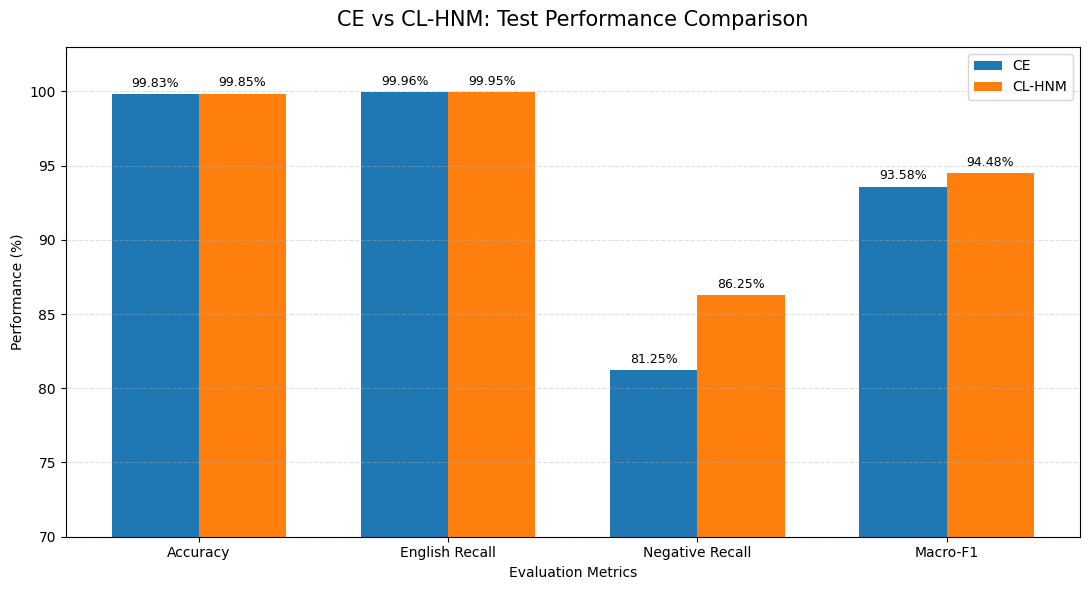

Figure saved successfully:
/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/Research_Graphs/Figure_1_Test_Performance_Comparison.png


In [21]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"

INPUT = BASE + "/Threshold_Analysis/final_test_metrics_threshold_003.csv"
OUTPUT_DIR = BASE + "/Research_Graphs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

df = pd.read_csv(INPUT)

metrics = {
    "Accuracy": "Accuracy",
    "English Recall": "English_Recall",
    "Negative Recall": "Negative_Recall",
    "Macro-F1": "Macro_F1"
}

models = ["CE", "CL-HNM"]
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

for i, model in enumerate(models):

    row = df[df["Model"] == model].iloc[0]

    values = [
        row[column] * 100
        for column in metrics.values()
    ]

    bars = ax.bar(
        x + (i - 0.5) * width,
        values,
        width,
        label=model
    )

    ax.bar_label(
        bars,
        fmt="%.2f%%",
        padding=3,
        fontsize=9
    )

ax.set_title(
    "CE vs CL-HNM: Test Performance Comparison",
    fontsize=15,
    pad=15
)

ax.set_ylabel("Performance (%)")
ax.set_xlabel("Evaluation Metrics")
ax.set_xticks(x)
ax.set_xticklabels(metrics.keys())

ax.set_ylim(70, 103)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

path = OUTPUT_DIR + "/Figure_1_Test_Performance_Comparison.png"

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully:")
print(path)

Confusion matrices

We'll create side-by-side confusion matrices for CE and CL-HNM using the actual test predictions at threshold 0.03.

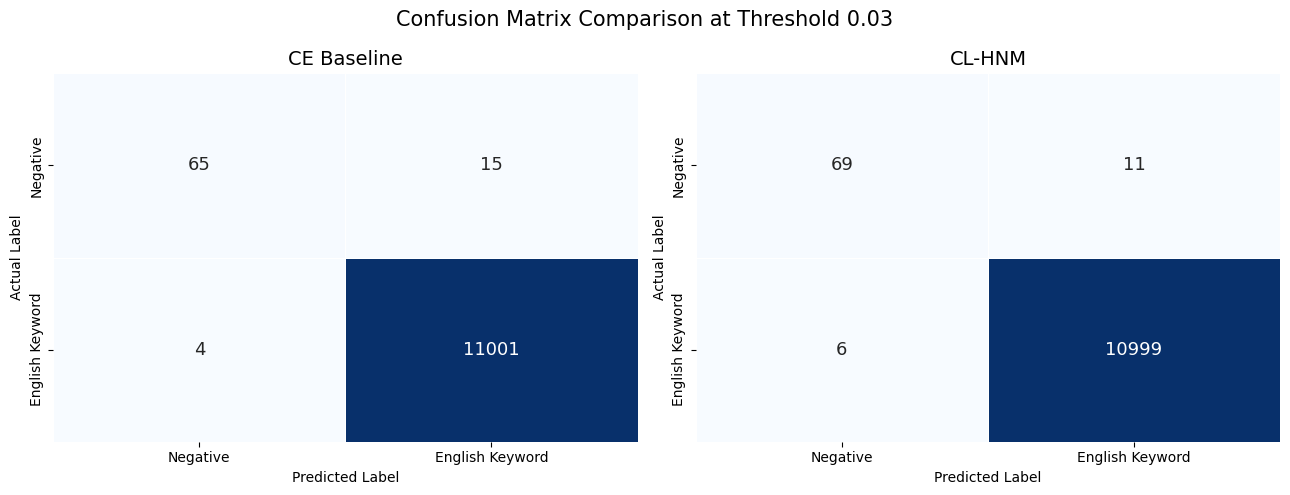

CE Confusion Matrix:
 [[   65    15]
 [    4 11001]]

CL-HNM Confusion Matrix:
 [[   69    11]
 [    6 10999]]

Saved: /content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/Research_Graphs/Figure_2_Confusion_Matrices.png


In [22]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

BASE = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"

INPUT = BASE + "/Threshold_Analysis/test_probabilities_threshold_003.csv"
OUTPUT_DIR = BASE + "/Research_Graphs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

df = pd.read_csv(INPUT)

y_true = df["label"].values

ce_pred = (
    df["ce_english_probability"].values >= 0.03
).astype(int)

cl_pred = (
    df["cl_hnm_english_probability"].values >= 0.03
).astype(int)

ce_cm = confusion_matrix(y_true, ce_pred, labels=[0, 1])
cl_cm = confusion_matrix(y_true, cl_pred, labels=[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

class_names = ["Negative", "English Keyword"]

for ax, cm, title in zip(
    axes,
    [ce_cm, cl_cm],
    ["CE Baseline", "CL-HNM"]
):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        linewidths=0.5,
        ax=ax,
        cbar=False,
        annot_kws={"size": 13}
    )

    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

fig.suptitle(
    "Confusion Matrix Comparison at Threshold 0.03",
    fontsize=15
)

plt.tight_layout()

path = OUTPUT_DIR + "/Figure_2_Confusion_Matrices.png"

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print("CE Confusion Matrix:\n", ce_cm)
print("\nCL-HNM Confusion Matrix:\n", cl_cm)
print("\nSaved:", path)

Threshold-performance curves

This graph is particularly important because it demonstrates how the models behave as the decision threshold changes.

We'll plot:
1. Negative Recall vs Threshold.
2. English Recall vs Threshold.

Both CE and CL-HNM will appear on each graph.

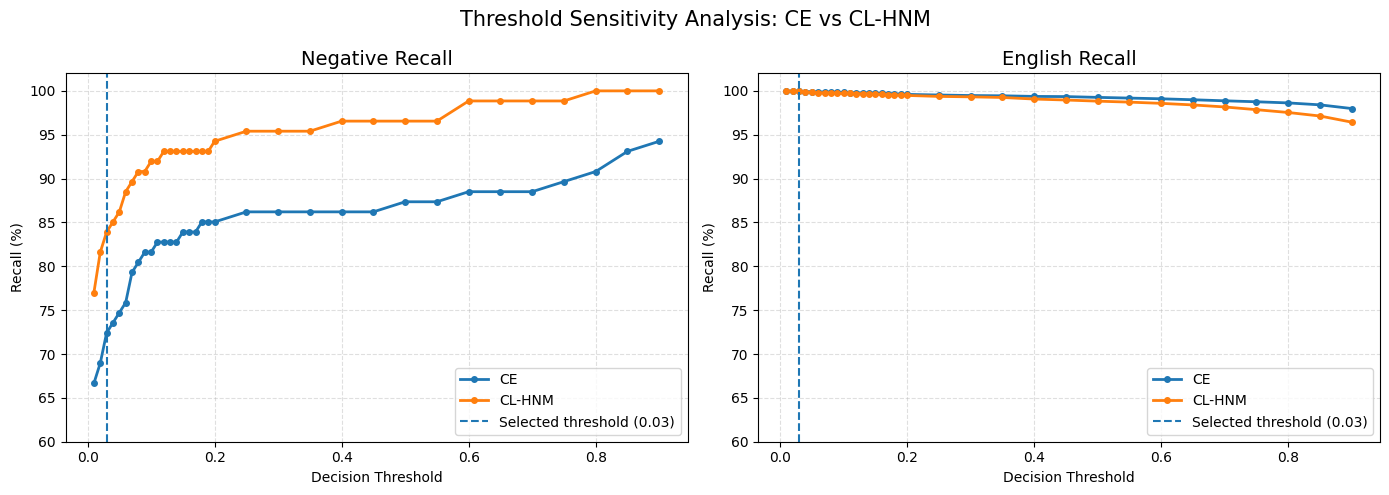

Saved: /content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/Research_Graphs/Figure_3_Threshold_Performance.png


In [23]:
import os
import pandas as pd
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"

FINE = BASE + "/Threshold_Analysis/fine_threshold_comparison.csv"
COARSE = BASE + "/Threshold_Analysis/threshold_comparison.csv"

OUTPUT_DIR = BASE + "/Research_Graphs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Combine both threshold experiments
fine_df = pd.read_csv(FINE)
coarse_df = pd.read_csv(COARSE)

df = pd.concat([fine_df, coarse_df], ignore_index=True)

df = (
    df.drop_duplicates(subset=["Model", "Threshold"])
      .sort_values(["Model", "Threshold"])
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

metrics = [
    ("Negative_Recall", "Negative Recall"),
    ("English_Recall", "English Recall")
]

for ax, (column, title) in zip(axes, metrics):

    for model in ["CE", "CL-HNM"]:

        subset = df[df["Model"] == model]

        ax.plot(
            subset["Threshold"],
            subset[column] * 100,
            marker="o",
            markersize=4,
            linewidth=2,
            label=model
        )

    ax.axvline(
        0.03,
        linestyle="--",
        linewidth=1.5,
        label="Selected threshold (0.03)"
    )

    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Decision Threshold")
    ax.set_ylabel("Recall (%)")
    ax.set_ylim(60, 102)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend()

fig.suptitle(
    "Threshold Sensitivity Analysis: CE vs CL-HNM",
    fontsize=15
)

plt.tight_layout()

path = OUTPUT_DIR + "/Figure_3_Threshold_Performance.png"

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", path)

Training and validation curves
Next, we'll visualize how both models learned during training.

We'll prepare:
- CE training loss.
- CE validation loss.
- CL-HNM training loss.
- CL-HNM validation loss.
- Validation Macro-F1 across epochs.

In [24]:
import pandas as pd
import os

BASE = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"

files = {
    "CE": BASE + "/CE_Baseline/ce_training_metrics.csv",
    "CL-HNM": BASE + "/CL_HNM/Training/cl_hnm_training_metrics.csv"
}

for name, path in files.items():

    print("\n==========", name, "TRAINING METRICS ==========")

    df = pd.read_csv(path)

    print("Columns:")
    print(df.columns.tolist())

    print("\nComplete data:")
    display(df)


========== CE TRAINING METRICS ==========
Columns:
['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'val_precision', 'val_positive_recall', 'val_negative_recall', 'val_macro_f1']

Complete data:


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_precision,val_positive_recall,val_negative_recall,val_macro_f1
0,1,0.160633,0.939833,0.060301,0.984505,0.998680,0.985673,0.850575,0.739488
1,2,0.093424,0.966667,0.051422,0.983015,0.998374,0.984470,0.816092,0.722524
2,3,0.061341,0.980167,0.023626,0.991259,0.998388,0.992786,0.816092,0.806485
3,4,0.071936,0.975000,0.143206,0.945769,0.999788,0.945496,0.977011,0.604657
4,5,0.054861,0.982333,0.078824,0.971692,0.999691,0.971746,0.965517,0.678191
5,6,0.035189,0.986167,0.069965,0.971792,0.998971,0.972548,0.885057,0.668590
6,7,0.030316,0.990500,0.091416,0.988975,0.997380,0.991484,0.701149,0.759014
7,8,0.031724,0.989667,0.022671,0.991557,0.998891,0.992586,0.873563,0.818539
8,9,0.029172,0.991167,0.030422,0.990068,0.998889,0.991083,0.873563,0.799073
9,10,0.051829,0.979667,0.072133,0.981526,0.998981,0.982366,0.885057,0.721773



========== CL-HNM TRAINING METRICS ==========
Columns:
['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'val_macro_f1']

Complete data:


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_macro_f1
0,1,0.060239,0.98050,0.041566,0.983909,0.753395
1,2,0.044870,0.98575,0.042894,0.982519,0.742679
2,3,0.038948,0.99075,0.030745,0.988081,0.788644


Training and validation loss

This figure will show:
- CE training and validation loss across 10 epochs.
- CL-HNM training and validation loss across 3 fine-tuning epochs.
- Best checkpoint epochs.

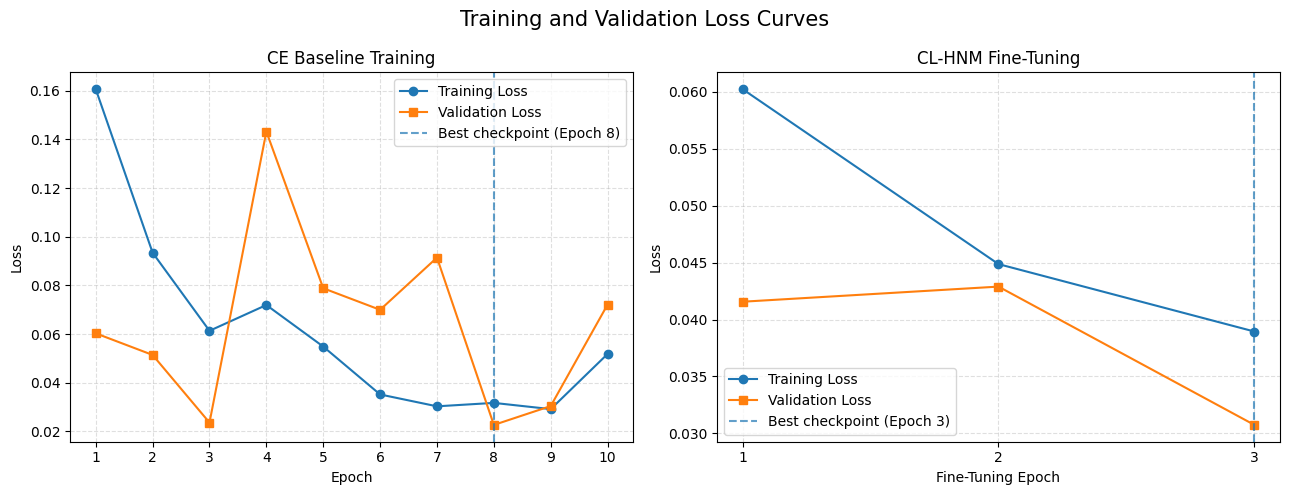

Saved: /content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/Research_Graphs/Figure_4A_Training_Validation_Loss.png


In [25]:
import os
import pandas as pd
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"

CE_PATH = BASE + "/CE_Baseline/ce_training_metrics.csv"
CL_PATH = BASE + "/CL_HNM/Training/cl_hnm_training_metrics.csv"

OUTPUT_DIR = BASE + "/Research_Graphs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

ce = pd.read_csv(CE_PATH)
cl = pd.read_csv(CL_PATH)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# CE baseline
axes[0].plot(
    ce["epoch"], ce["train_loss"],
    marker="o", label="Training Loss"
)
axes[0].plot(
    ce["epoch"], ce["val_loss"],
    marker="s", label="Validation Loss"
)

axes[0].axvline(
    8, linestyle="--", alpha=0.7,
    label="Best checkpoint (Epoch 8)"
)

axes[0].set_title("CE Baseline Training")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks(ce["epoch"])
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend()

# CL-HNM fine-tuning
axes[1].plot(
    cl["epoch"], cl["train_loss"],
    marker="o", label="Training Loss"
)
axes[1].plot(
    cl["epoch"], cl["val_loss"],
    marker="s", label="Validation Loss"
)

axes[1].axvline(
    3, linestyle="--", alpha=0.7,
    label="Best checkpoint (Epoch 3)"
)

axes[1].set_title("CL-HNM Fine-Tuning")
axes[1].set_xlabel("Fine-Tuning Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_xticks(cl["epoch"])
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend()

fig.suptitle(
    "Training and Validation Loss Curves",
    fontsize=15
)

plt.tight_layout()

path = OUTPUT_DIR + "/Figure_4A_Training_Validation_Loss.png"

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", path)

Validation Macro-F1

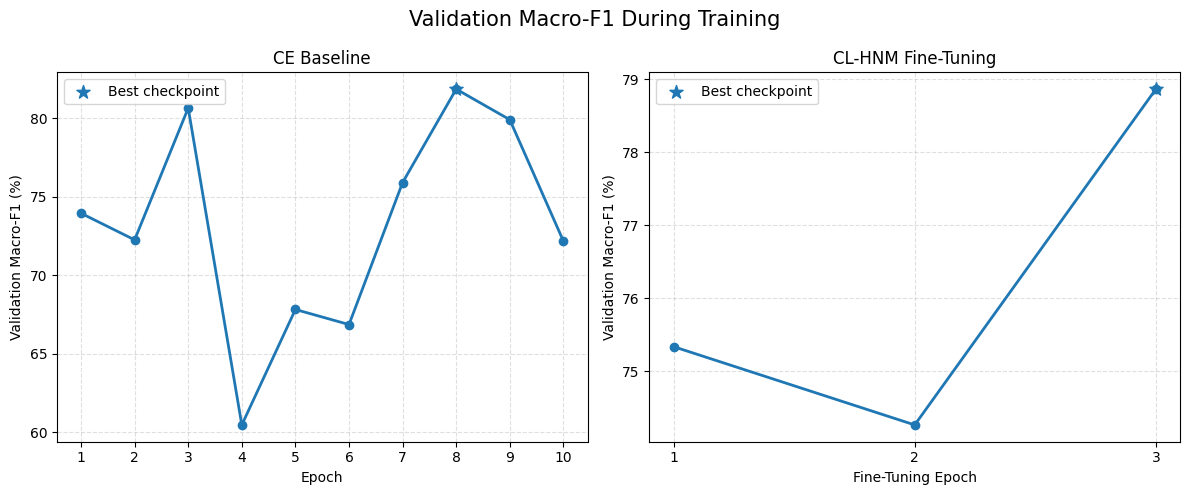

Saved: /content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/Research_Graphs/Figure_4B_Validation_Macro_F1.png


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# CE Macro-F1
axes[0].plot(
    ce["epoch"], ce["val_macro_f1"] * 100,
    marker="o", linewidth=2
)

axes[0].scatter(
    [8], [ce.loc[ce["epoch"] == 8, "val_macro_f1"].iloc[0] * 100],
    s=100, marker="*",
    label="Best checkpoint"
)

axes[0].set_title("CE Baseline")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation Macro-F1 (%)")
axes[0].set_xticks(ce["epoch"])
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend()

# CL-HNM Macro-F1
axes[1].plot(
    cl["epoch"], cl["val_macro_f1"] * 100,
    marker="o", linewidth=2
)

axes[1].scatter(
    [3], [cl.loc[cl["epoch"] == 3, "val_macro_f1"].iloc[0] * 100],
    s=100, marker="*",
    label="Best checkpoint"
)

axes[1].set_title("CL-HNM Fine-Tuning")
axes[1].set_xlabel("Fine-Tuning Epoch")
axes[1].set_ylabel("Validation Macro-F1 (%)")
axes[1].set_xticks(cl["epoch"])
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend()

fig.suptitle(
    "Validation Macro-F1 During Training",
    fontsize=15
)

plt.tight_layout()

path = OUTPUT_DIR + "/Figure_4B_Validation_Macro_F1.png"

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", path)

Create the consolidated research results table

Let's prepare one table containing the final test metrics, confusion matrix counts, and selected threshold.

In [27]:
import os
import pandas as pd

BASE = "/content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment"

INPUT = BASE + "/Threshold_Analysis/final_test_metrics_threshold_003.csv"
OUTPUT_DIR = BASE + "/Research_Graphs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

df = pd.read_csv(INPUT)

summary = df[[
    "Model",
    "Threshold",
    "Accuracy",
    "English_Precision",
    "English_Recall",
    "Negative_Recall",
    "False_Acceptances",
    "False_Rejections",
    "Macro_F1"
]].copy()

# Convert metrics into percentages
percentage_columns = [
    "Accuracy",
    "English_Precision",
    "English_Recall",
    "Negative_Recall",
    "Macro_F1"
]

for column in percentage_columns:
    summary[column] *= 100

summary = summary.round(2)

summary.rename(columns={
    "Model": "Model",
    "Threshold": "Decision Threshold",
    "Accuracy": "Accuracy (%)",
    "English_Precision": "English Precision (%)",
    "English_Recall": "English Recall (%)",
    "Negative_Recall": "Negative Recall (%)",
    "False_Acceptances": "False Acceptances",
    "False_Rejections": "False Rejections",
    "Macro_F1": "Macro-F1 (%)"
}, inplace=True)

output_path = OUTPUT_DIR + "/Final_Research_Results.csv"

summary.to_csv(output_path, index=False)

print("========== FINAL RESEARCH RESULTS ==========")
display(summary)

print("\nSaved:", output_path)

========== FINAL RESEARCH RESULTS ==========


,Model,Decision Threshold,Accuracy (%),English Precision (%),English Recall (%),Negative Recall (%),False Acceptances,False Rejections,Macro-F1 (%)
0,CE,0.03,99.83,99.86,99.96,81.25,15,4,93.58
1,CL-HNM,0.03,99.85,99.90,99.95,86.25,11,6,94.48



Saved: /content/drive/MyDrive/TC_ResNet8_Backup/Recovered_Experiment/Research_Graphs/Final_Research_Results.csv
